# Token -9 anaysis

Rows: 900

Ranking groups:
 target_present  ranking_group
          False  target_absent
           True target_present

Summary:
 target_present  ranking_group  patch_percentage  selected_head_count  n_pairs  valid_recovery_n  source_accuracy  target_accuracy  patched_accuracy  mean_delta_margin  median_delta_margin  mean_recovery  median_recovery  recovery_std  accuracy_gain  recovery_sem
          False  target_absent               0.1                    1       50                50              1.0             0.52              0.68             0.6275               0.6250       0.051470         0.051747      0.017820           0.16      0.002520
          False  target_absent               0.5                    4       50                50              1.0             0.52              0.94             1.7950               1.7500       0.148496         0.151026      0.022425           0.42      0.003171
          False  target_absent               1.0                    8       50

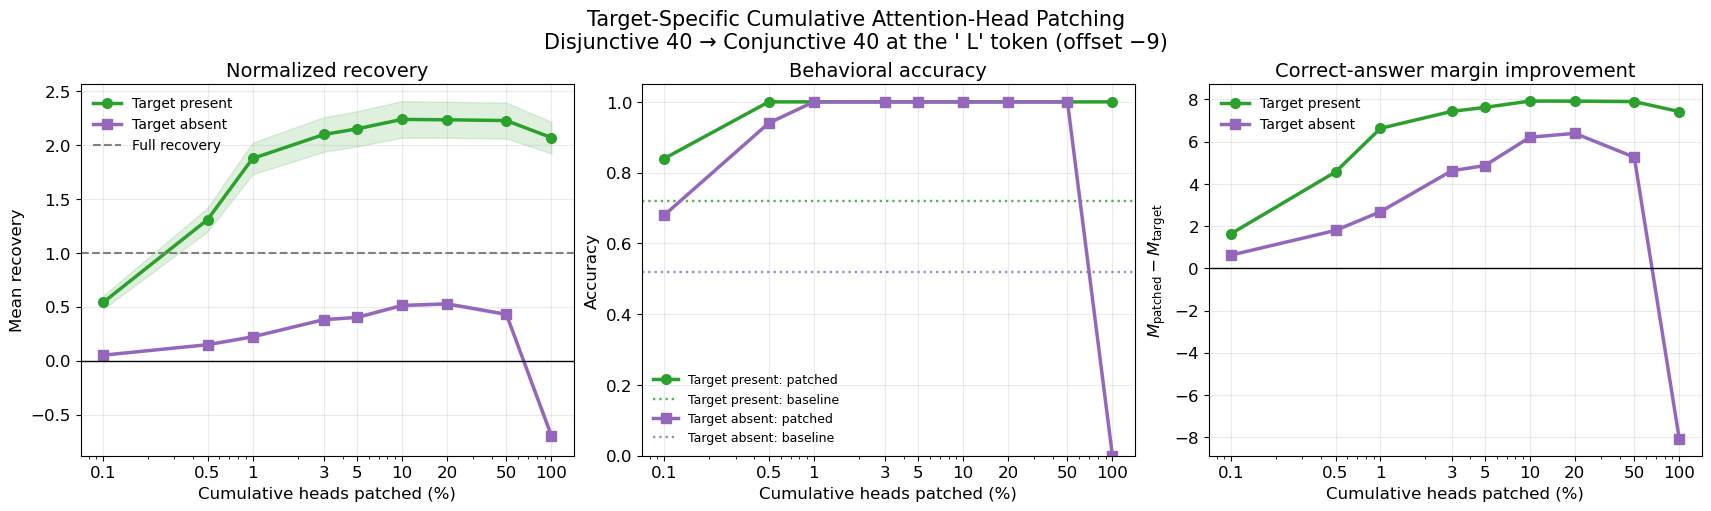

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# LOAD
# ============================================================

PATH = (
    "../Results/"
    "disj40_to_conj40_cumulative_offset_-9.csv"
)

df = pd.read_csv(PATH).copy()

# Keep successful interventions
if "error" in df.columns:
    df = df[df["error"].isna()].copy()

# Normalize target_present
if df["target_present"].dtype == object:
    df["target_present"] = (
        df["target_present"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )

# Ensure numeric values
numeric_columns = [
    "patch_percentage",
    "selected_head_count",
    "source_margin",
    "target_margin",
    "patched_margin",
    "delta_margin",
    "recovery",
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["recovery"] = df["recovery"].replace(
    [np.inf, -np.inf],
    np.nan,
)

# Only use valid recovery values
if "recovery_valid" in df.columns:
    if df["recovery_valid"].dtype == object:
        df["recovery_valid"] = (
            df["recovery_valid"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map(
                {
                    "true": True,
                    "false": False,
                    "1": True,
                    "0": False,
                }
            )
        )

    df.loc[
        ~df["recovery_valid"].fillna(False),
        "recovery",
    ] = np.nan

print("Rows:", len(df))

print("\nRanking groups:")
print(
    df[
        [
            "target_present",
            "ranking_group",
        ]
    ]
    .drop_duplicates()
    .sort_values("target_present")
    .to_string(index=False)
)

# ============================================================
# SUMMARIZE
# ============================================================

summary = (
    df.groupby(
        [
            "target_present",
            "ranking_group",
            "patch_percentage",
            "selected_head_count",
        ],
        as_index=False,
    )
    .agg(
        n_pairs=("trial", "size"),
        valid_recovery_n=("recovery", "count"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        mean_delta_margin=("delta_margin", "mean"),
        median_delta_margin=("delta_margin", "median"),
        mean_recovery=("recovery", "mean"),
        median_recovery=("recovery", "median"),
        recovery_std=("recovery", "std"),
    )
)

summary["accuracy_gain"] = (
    summary["patched_accuracy"]
    - summary["target_accuracy"]
)

summary["recovery_sem"] = (
    summary["recovery_std"]
    / np.sqrt(summary["valid_recovery_n"])
)

summary = summary.sort_values(
    [
        "target_present",
        "patch_percentage",
    ]
)

print("\nSummary:")
print(summary.to_string(index=False))

# ============================================================
# STYLE
# ============================================================

condition_styles = {
    True: {
        "label": "Target present",
        "color": "tab:green",
        "marker": "o",
    },
    False: {
        "label": "Target absent",
        "color": "tab:purple",
        "marker": "s",
    },
}

percentages = sorted(
    summary["patch_percentage"].dropna().unique()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5),
    constrained_layout=True,
)

# ============================================================
# PANEL 1: NORMALIZED RECOVERY
# ============================================================

ax = axes[0]

for target_present, style in condition_styles.items():
    condition_df = summary[
        summary["target_present"] == target_present
    ].sort_values("patch_percentage")

    x = condition_df["patch_percentage"].to_numpy()
    y = condition_df["mean_recovery"].to_numpy()
    sem = condition_df["recovery_sem"].to_numpy()

    ax.plot(
        x,
        y,
        marker=style["marker"],
        color=style["color"],
        linewidth=2.5,
        markersize=7,
        label=style["label"],
    )

    ax.fill_between(
        x,
        y - sem,
        y + sem,
        color=style["color"],
        alpha=0.15,
    )

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.axhline(
    1,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Full recovery",
)

ax.set_title("Normalized recovery")
ax.set_xlabel("Cumulative heads patched (%)")
ax.set_ylabel("Mean recovery")
ax.set_xscale("log")
ax.grid(alpha=0.25)
ax.legend(frameon=False)

# ============================================================
# PANEL 2: PATCHED ACCURACY
# ============================================================

ax = axes[1]

for target_present, style in condition_styles.items():
    condition_df = summary[
        summary["target_present"] == target_present
    ].sort_values("patch_percentage")

    ax.plot(
        condition_df["patch_percentage"],
        condition_df["patched_accuracy"],
        marker=style["marker"],
        color=style["color"],
        linewidth=2.5,
        markersize=7,
        label=f"{style['label']}: patched",
    )

    # Unpatched accuracy is constant within each target-presence group
    baseline = condition_df["target_accuracy"].iloc[0]

    ax.axhline(
        baseline,
        color=style["color"],
        linestyle=":",
        linewidth=1.7,
        alpha=0.8,
        label=f"{style['label']}: baseline",
    )

ax.set_title("Behavioral accuracy")
ax.set_xlabel("Cumulative heads patched (%)")
ax.set_ylabel("Accuracy")
ax.set_xscale("log")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend(
    frameon=False,
    fontsize=9,
)

# ============================================================
# PANEL 3: MARGIN IMPROVEMENT
# ============================================================

ax = axes[2]

for target_present, style in condition_styles.items():
    condition_df = summary[
        summary["target_present"] == target_present
    ].sort_values("patch_percentage")

    ax.plot(
        condition_df["patch_percentage"],
        condition_df["mean_delta_margin"],
        marker=style["marker"],
        color=style["color"],
        linewidth=2.5,
        markersize=7,
        label=style["label"],
    )

ax.axhline(
    0,
    color="black",
    linewidth=1,
)

ax.set_title("Correct-answer margin improvement")
ax.set_xlabel("Cumulative heads patched (%)")
ax.set_ylabel(
    r"$M_{\mathrm{patched}} - M_{\mathrm{target}}$"
)
ax.set_xscale("log")
ax.grid(alpha=0.25)
ax.legend(frameon=False)

# ============================================================
# EXACT X-AXIS TICKS
# ============================================================

for ax in axes:
    ax.set_xticks(percentages)
    ax.set_xticklabels(
        [f"{percentage:g}" for percentage in percentages]
    )

# ============================================================
# TITLE AND SAVE
# ============================================================

fig.suptitle(
    "Target-Specific Cumulative Attention-Head Patching\n"
    "Disjunctive 40 → Conjunctive 40 at the ' L' token "
    "(offset −9)",
    fontsize=15,
)



plt.show()

## Dissecting by value and attention 

Rows by condition:
selection_type  intervention_component
random          attention_matrix          900
                full_head_output          900
                value_vectors             900
ranked          attention_matrix          900
                full_head_output          900
                value_vectors             900
dtype: int64

Unique trials: 100

Random seeds:
[42.]


,target_present,selection_type,intervention_component,patch_percentage,selected_head_count,n_pairs,n_random_runs,source_accuracy,target_accuracy,patched_accuracy,patched_accuracy_sem,mean_delta_margin,delta_margin_sem,mean_recovery,recovery_sem
0,False,random,attention_matrix,0.1,1,50,1,1.0,0.52,0.48,0.0,-0.0150,0.000000,-0.001166,0.000000
1,False,random,attention_matrix,0.5,4,50,1,1.0,0.52,0.52,0.0,0.0325,0.000000,0.002826,0.000000
2,False,random,attention_matrix,1.0,8,50,1,1.0,0.52,0.52,0.0,0.0200,0.000000,0.001809,0.000000
3,False,random,attention_matrix,3.0,24,50,1,1.0,0.52,0.50,0.0,0.0200,0.000000,0.001801,0.000000
4,False,random,attention_matrix,5.0,40,50,1,1.0,0.52,0.54,0.0,0.2450,0.000000,0.021346,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,True,ranked,value_vectors,5.0,40,50,0,1.0,0.72,1.00,0.0,6.6900,0.235369,1.879456,0.145152
104,True,ranked,value_vectors,10.0,79,50,0,1.0,0.72,1.00,0.0,7.0700,0.241782,1.986028,0.152312
105,True,ranked,value_vectors,20.0,157,50,0,1.0,0.72,1.00,0.0,7.2325,0.238806,2.037271,0.155480
106,True,ranked,value_vectors,50.0,392,50,0,1.0,0.72,1.00,0.0,7.0875,0.239851,1.990764,0.151464



Random-control run counts:
 target_present intervention_component  patch_percentage  selected_head_count  n_random_runs
          False       attention_matrix               0.1                    1              1
          False       attention_matrix               0.5                    4              1
          False       attention_matrix               1.0                    8              1
          False       attention_matrix               3.0                   24              1
          False       attention_matrix               5.0                   40              1
          False       attention_matrix              10.0                   79              1
          False       attention_matrix              20.0                  157              1
          False       attention_matrix              50.0                  392              1
          False       attention_matrix             100.0                  784              1
          False       full_head_output    

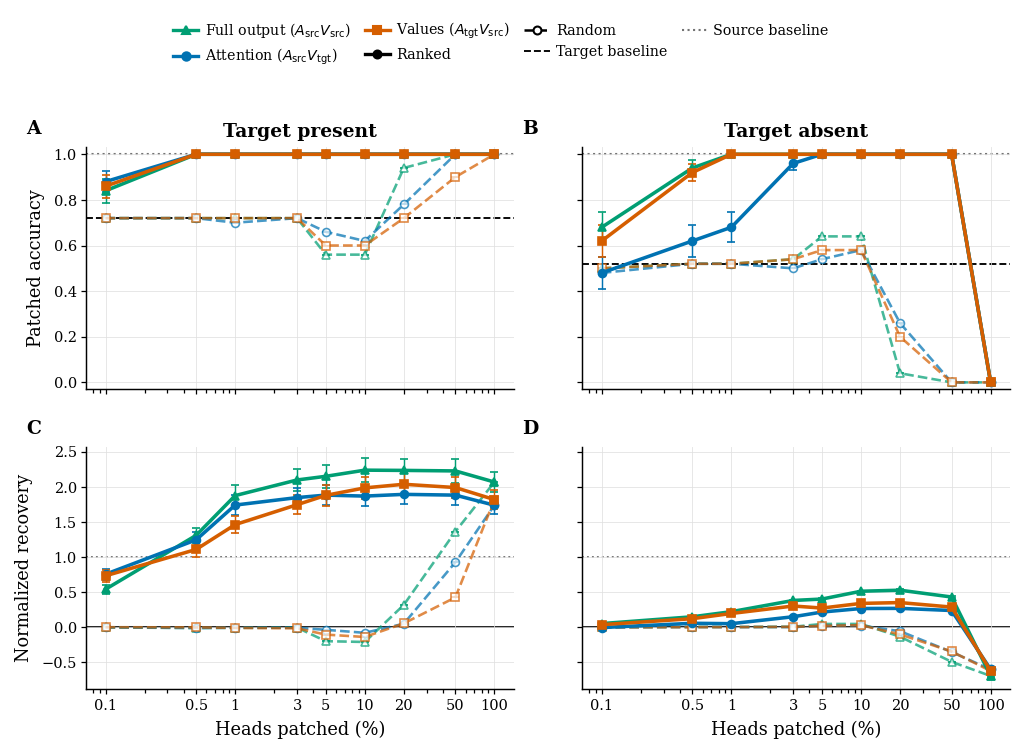

Saved: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_behavior_recovery_neurips.pdf
Saved: /oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_behavior_recovery_neurips.png


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================
# LOAD
# ==========================================================

CSV = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_cumulative_offset_-9.csv"
)

df = pd.read_csv(CSV).copy()

# Remove unsuccessful interventions
if "error" in df.columns:
    df = df[df["error"].isna()].copy()

# Normalize target_present if loaded as text
if df["target_present"].dtype == object:
    df["target_present"] = (
        df["target_present"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
        })
    )

df["recovery"] = pd.to_numeric(
    df["recovery"],
    errors="coerce",
).replace([np.inf, -np.inf], np.nan)

df["delta_margin"] = pd.to_numeric(
    df["delta_margin"],
    errors="coerce",
)

# Compatibility check
required_columns = {
    "selection_type",
    "intervention_component",
    "patch_percentage",
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"CSV is missing columns: {sorted(missing)}.\n"
        "Make sure this file was produced by the updated script."
    )

print("Rows by condition:")
print(
    df.groupby(
        ["selection_type", "intervention_component"]
    )
    .size()
)

print("\nUnique trials:", df["trial"].nunique())

print("\nRandom seeds:")
print(
    df.loc[
        df["selection_type"] == "random",
        "random_seed",
    ].dropna().unique()
)


# ==========================================================
# SUMMARY
#
# Ranked heads:
#   Mean and SEM across trials.
#
# Random controls:
#   1. Calculate each metric within each random seed.
#   2. Average across the 10 seeds.
#   3. Calculate SEM across the 10 seed-level estimates.
# ==========================================================

def sem(series):
    values = pd.to_numeric(
        series,
        errors="coerce",
    ).dropna()

    if len(values) <= 1:
        return 0.0

    return values.std(ddof=1) / np.sqrt(len(values))


group_columns = [
    "target_present",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
]


# ==========================================================
# RANKED HEADS: UNCERTAINTY ACROSS TRIALS
# ==========================================================

ranked_df = df[
    df["selection_type"] == "ranked"
].copy()

ranked_summary = (
    ranked_df.groupby(
        group_columns,
        as_index=False,
    )
    .agg(
        n_pairs=("trial", "nunique"),
        n_random_runs=("random_seed", "nunique"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        patched_accuracy_sem=("patched_correct", sem),
        mean_delta_margin=("delta_margin", "mean"),
        delta_margin_sem=("delta_margin", sem),
        mean_recovery=("recovery", "mean"),
        recovery_sem=("recovery", sem),
    )
)


# ==========================================================
# RANDOM CONTROLS: FIRST AGGREGATE WITHIN EACH SEED
# ==========================================================

random_df = df[
    df["selection_type"] == "random"
].copy()

if random_df["random_seed"].isna().any():
    raise ValueError(
        "Some random-control rows are missing random_seed."
    )

random_seed_summary = (
    random_df.groupby(
        group_columns + ["random_seed"],
        as_index=False,
    )
    .agg(
        n_pairs_seed=("trial", "nunique"),
        source_accuracy_seed=("source_correct", "mean"),
        target_accuracy_seed=("target_correct", "mean"),
        patched_accuracy_seed=("patched_correct", "mean"),
        mean_delta_margin_seed=("delta_margin", "mean"),
        mean_recovery_seed=("recovery", "mean"),
    )
)


# ==========================================================
# RANDOM CONTROLS: MEAN AND SEM ACROSS THE 10 SEEDS
# ==========================================================

random_summary = (
    random_seed_summary.groupby(
        group_columns,
        as_index=False,
    )
    .agg(
        n_pairs=("n_pairs_seed", "sum"),
        n_random_runs=("random_seed", "nunique"),
        source_accuracy=("source_accuracy_seed", "mean"),
        target_accuracy=("target_accuracy_seed", "mean"),
        patched_accuracy=("patched_accuracy_seed", "mean"),
        patched_accuracy_sem=("patched_accuracy_seed", sem),
        mean_delta_margin=("mean_delta_margin_seed", "mean"),
        delta_margin_sem=("mean_delta_margin_seed", sem),
        mean_recovery=("mean_recovery_seed", "mean"),
        recovery_sem=("mean_recovery_seed", sem),
    )
)


# ==========================================================
# COMBINE RANKED AND RANDOM RESULTS
# ==========================================================

summary = pd.concat(
    [
        ranked_summary,
        random_summary,
    ],
    ignore_index=True,
).sort_values(
    [
        "target_present",
        "selection_type",
        "intervention_component",
        "patch_percentage",
    ]
).reset_index(drop=True)

display(summary)


# ==========================================================
# VERIFY THAT EACH RANDOM CONDITION HAS 10 RUNS
# ==========================================================

random_run_check = (
    random_summary[
        [
            "target_present",
            "intervention_component",
            "patch_percentage",
            "selected_head_count",
            "n_random_runs",
        ]
    ]
    .sort_values(
        [
            "target_present",
            "intervention_component",
            "patch_percentage",
        ]
    )
)

print("\nRandom-control run counts:")
print(random_run_check.to_string(index=False))

unexpected = random_run_check[
    random_run_check["n_random_runs"] != 10
]

if not unexpected.empty:
    print(
        "\nWARNING: The following random-control conditions "
        "do not contain exactly 10 runs:"
    )
    print(unexpected.to_string(index=False))

# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6.8,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

component_order = [
    "full_head_output",
    "attention_matrix",
    "value_vectors",
]

component_labels = {
    "full_head_output": (
        r"Full output "
        r"($A_{\mathrm{src}}V_{\mathrm{src}}$)"
    ),
    "attention_matrix": (
        r"Attention "
        r"($A_{\mathrm{src}}V_{\mathrm{tgt}}$)"
    ),
    "value_vectors": (
        r"Values "
        r"($A_{\mathrm{tgt}}V_{\mathrm{src}}$)"
    ),
}

# Colorblind-friendly palette
colors = {
    "full_head_output": "#009E73",
    "attention_matrix": "#0072B2",
    "value_vectors": "#D55E00",
}

markers = {
    "full_head_output": "^",
    "attention_matrix": "o",
    "value_vectors": "s",
}

selection_styles = {
    "ranked": {
        "linestyle": "-",
        "linewidth": 1.7,
        "alpha": 1.0,
        "markerfacecolor": None,
    },
    "random": {
        "linestyle": "--",
        "linewidth": 1.25,
        "alpha": 0.72,
        "markerfacecolor": "white",
    },
}

percentages = sorted(
    summary["patch_percentage"].dropna().unique()
)


# ==========================================================
# COMPACT PLOTTING FUNCTION
# ==========================================================

def plot_component_curves(
    ax,
    data,
    metric,
    error_column,
):
    for selection_type in ["ranked", "random"]:
        for component in component_order:

            component_data = (
                data[
                    (data["selection_type"] == selection_type)
                    & (
                        data["intervention_component"]
                        == component
                    )
                ]
                .sort_values("patch_percentage")
            )

            if component_data.empty:
                continue

            style = selection_styles[selection_type]

            marker_face = (
                colors[component]
                if style["markerfacecolor"] is None
                else style["markerfacecolor"]
            )

            ax.errorbar(
                component_data["patch_percentage"],
                component_data[metric],
                yerr=component_data[error_column],
                color=colors[component],
                marker=markers[component],
                markerfacecolor=marker_face,
                markeredgecolor=colors[component],
                markeredgewidth=0.8,
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                markersize=3.8,
                capsize=1.7,
                capthick=0.7,
                elinewidth=0.7,
                alpha=style["alpha"],
                zorder=3 if selection_type == "ranked" else 2,
            )

    ax.set_xscale("log")
    ax.set_xticks(percentages)
    ax.set_xticklabels([
        f"{value:g}" for value in percentages
    ])

    ax.grid(
        axis="both",
        color="0.88",
        linewidth=0.45,
        alpha=0.8,
        zorder=0,
    )

    ax.tick_params(
        axis="both",
        width=0.6,
        length=2.5,
        pad=2,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# ==========================================================
# 2 × 2 NEURIPS FIGURE
# ==========================================================

# Approximately NeurIPS double-column width.
fig, axes = plt.subplots(
    2,
    2,
    figsize=(7.0, 5.05),
    sharex=True,
    sharey="row",
)

for column, target_present in enumerate([True, False]):

    condition_df = summary[
        summary["target_present"] == target_present
    ].copy()

    if condition_df.empty:
        continue

    condition_title = (
        "Target present"
        if target_present
        else "Target absent"
    )

    source_accuracy = condition_df[
        "source_accuracy"
    ].iloc[0]

    target_accuracy = condition_df[
        "target_accuracy"
    ].iloc[0]

    # ------------------------------------------------------
    # TOP ROW: BEHAVIOR
    # ------------------------------------------------------

    ax_behavior = axes[0, column]

    plot_component_curves(
        ax=ax_behavior,
        data=condition_df,
        metric="patched_accuracy",
        error_column="patched_accuracy_sem",
    )

    ax_behavior.axhline(
        target_accuracy,
        color="black",
        linestyle="--",
        linewidth=0.9,
        zorder=1,
    )

    ax_behavior.axhline(
        source_accuracy,
        color="0.45",
        linestyle=":",
        linewidth=1.0,
        zorder=1,
    )

    ax_behavior.set_ylim(-0.03, 1.03)
    ax_behavior.set_title(
        condition_title,
        fontweight="semibold",
        pad=5,
    )

    # ------------------------------------------------------
    # BOTTOM ROW: NORMALIZED RECOVERY
    # ------------------------------------------------------

    ax_recovery = axes[1, column]

    plot_component_curves(
        ax=ax_recovery,
        data=condition_df,
        metric="mean_recovery",
        error_column="recovery_sem",
    )

    ax_recovery.axhline(
        0,
        color="black",
        linewidth=0.8,
        zorder=1,
    )

    ax_recovery.axhline(
        1,
        color="0.45",
        linestyle=":",
        linewidth=0.9,
        zorder=1,
    )

    ax_recovery.set_xlabel("Heads patched (%)")


# Only left column receives y-axis labels.
axes[0, 0].set_ylabel("Patched accuracy")
axes[1, 0].set_ylabel("Normalized recovery")

axes[0, 1].set_ylabel("")
axes[1, 1].set_ylabel("")


# ==========================================================
# PANEL LABELS
# ==========================================================

for label, ax in zip(
    ["A", "B", "C", "D"],
    axes.flatten(),
):
    ax.text(
        -0.14,
        1.04,
        label,
        transform=ax.transAxes,
        fontsize=9,
        fontweight="bold",
        va="bottom",
        ha="left",
        clip_on=False,
    )


# ==========================================================
# COMPACT SHARED LEGEND
# ==========================================================

component_handles = [
    Line2D(
        [0],
        [0],
        color=colors[component],
        marker=markers[component],
        markerfacecolor=colors[component],
        markeredgecolor=colors[component],
        linestyle="-",
        linewidth=1.6,
        markersize=4,
        label=component_labels[component],
    )
    for component in component_order
]

selection_handles = [
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="-",
        marker="o",
        markerfacecolor="black",
        markeredgecolor="black",
        linewidth=1.6,
        markersize=3.8,
        label="Ranked",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="--",
        marker="o",
        markerfacecolor="white",
        markeredgecolor="black",
        linewidth=1.2,
        markersize=3.8,
        label="Random",
    ),
]

baseline_handles = [
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="--",
        linewidth=0.9,
        label="Target baseline",
    ),
    Line2D(
        [0],
        [0],
        color="0.45",
        linestyle=":",
        linewidth=1.0,
        label="Source baseline",
    ),
]

fig.legend(
    handles=(
        component_handles
        + selection_handles
        + baseline_handles
    ),
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=4,
    frameon=False,
    columnspacing=1.0,
    handletextpad=0.45,
    handlelength=1.8,
    borderaxespad=0,
)

fig.subplots_adjust(
    left=0.105,
    right=0.985,
    bottom=0.105,
    top=0.82,
    wspace=0.16,
    hspace=0.24,
)


# ==========================================================
# SAVE
# ==========================================================

OUT_PDF = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_behavior_recovery_neurips.pdf"
)

OUT_PNG = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_behavior_recovery_neurips.png"
)

fig.savefig(
    OUT_PDF,
    bbox_inches="tight",
    pad_inches=0.02,
)

fig.savefig(
    OUT_PNG,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

print("Saved:", OUT_PDF)
print("Saved:", OUT_PNG)

Rows by 2x2 cell:
ranking_group   target_present  selection_type
target_absent   False           random            1350
                                ranked            1350
                True            random            1350
                                ranked            1350
target_present  False           random            1350
                                ranked            1350
                True            random            1350
                                ranked            1350
dtype: int64

Summary:
 ranking_group  target_present selection_type intervention_component  patch_percentage  selected_head_count  n_pairs  n_random_runs  source_accuracy  target_accuracy  patched_accuracy  patched_accuracy_sem  mean_delta_margin  delta_margin_sem  mean_recovery  recovery_sem
 target_absent           False         random       attention_matrix               0.1                    1       50              1              1.0             0.52              0.48              0.0

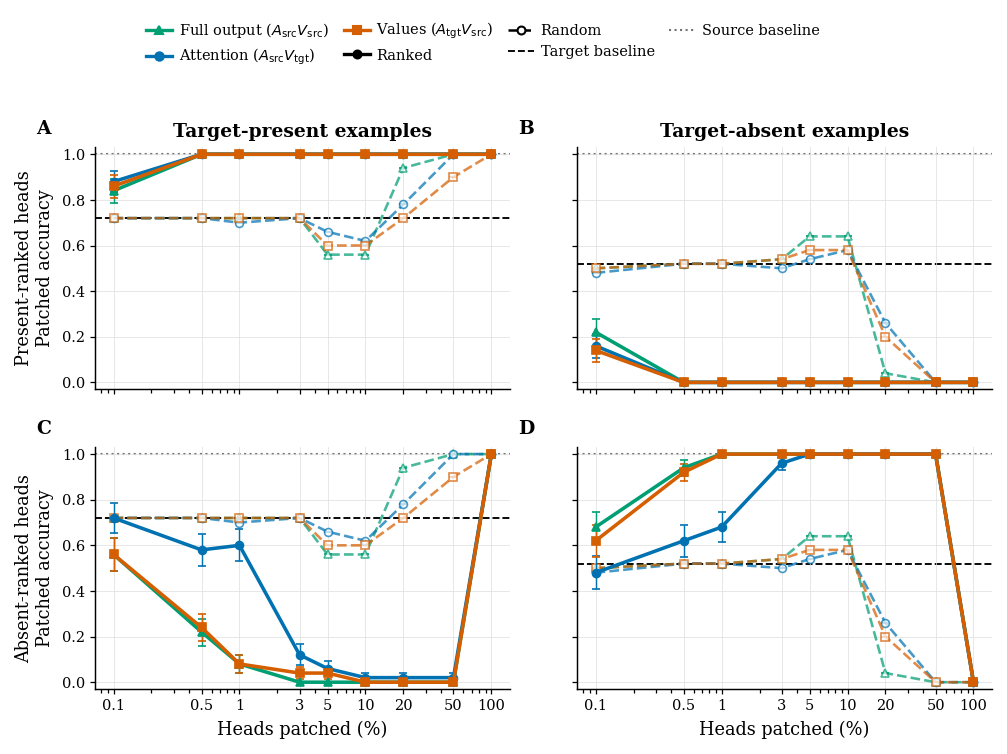

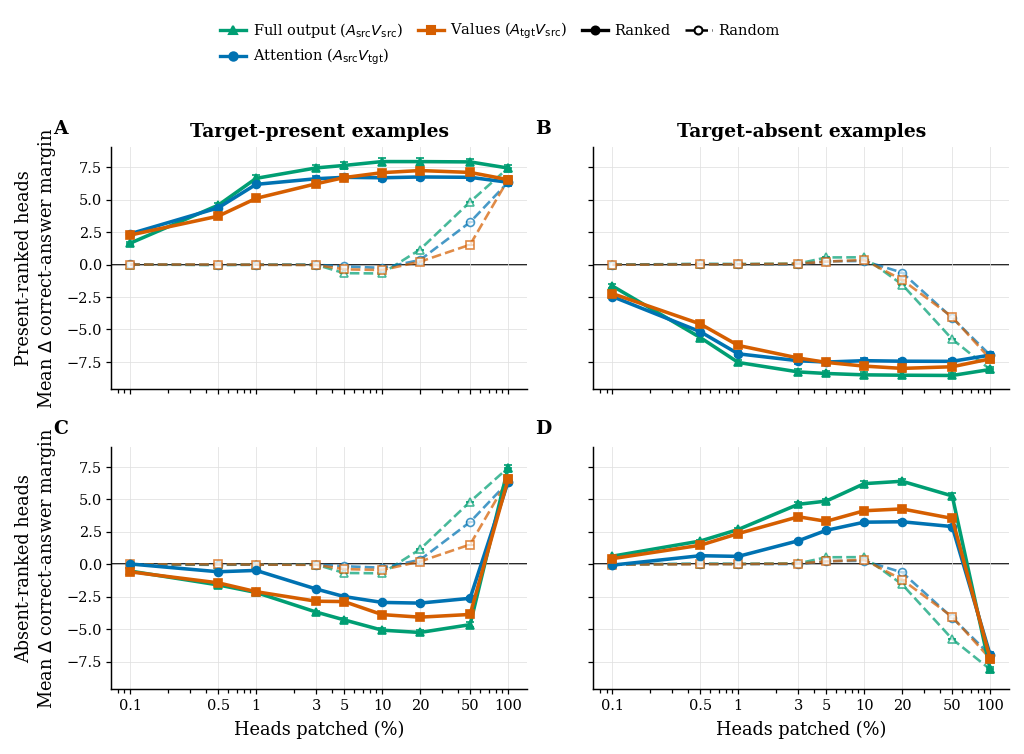

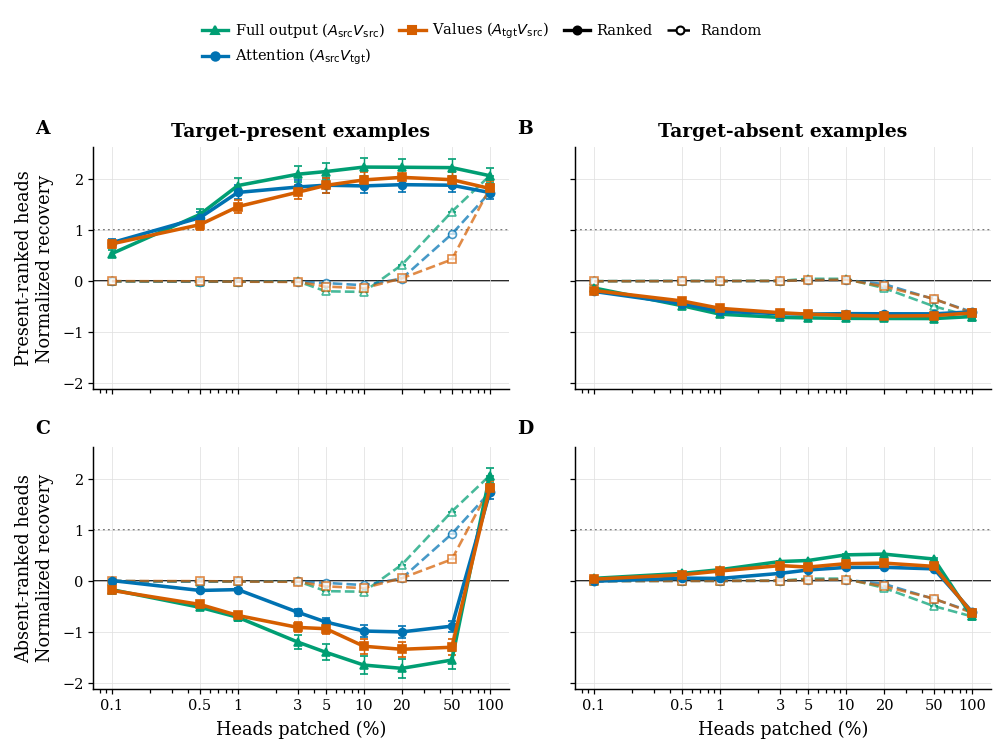

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_cumulative_offset_-9.csv"
)

OUTPUT_DIR = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_cross_eval_figures_offset_-9"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================================
# LOAD AND CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
]:
    df[column] = parse_bool(df[column])

for column in [
    "patch_percentage",
    "selected_head_count",
    "delta_margin",
    "recovery",
]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["recovery"] = df["recovery"].replace(
    [np.inf, -np.inf], np.nan
)

required_columns = {
    "trial",
    "target_present",
    "ranking_group",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
    "source_correct",
    "target_correct",
    "patched_correct",
    "delta_margin",
    "recovery",
}

missing = required_columns - set(df.columns)
if missing:
    raise ValueError(
        f"CSV is missing columns: {sorted(missing)}.\n"
        "Use the output from the new cross-evaluation patching run."
    )

expected_ranking_groups = {"target_present", "target_absent"}
observed_ranking_groups = set(df["ranking_group"].dropna().unique())
missing_groups = expected_ranking_groups - observed_ranking_groups
if missing_groups:
    raise ValueError(
        "The CSV does not contain the full cross-evaluation. Missing "
        f"ranking_group values: {sorted(missing_groups)}"
    )

observed_cells = set(
    df[["target_present", "ranking_group"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)
expected_cells = {
    (True, "target_present"),
    (False, "target_present"),
    (True, "target_absent"),
    (False, "target_absent"),
}
missing_cells = expected_cells - observed_cells
if missing_cells:
    raise ValueError(
        "The CSV is missing cross-evaluation cells: "
        f"{sorted(missing_cells, key=str)}"
    )

print("Rows by 2x2 cell:")
print(
    df.groupby(
        ["ranking_group", "target_present", "selection_type"]
    ).size()
)


# ==========================================================
# SUMMARIZE RANKED AND RANDOM CONDITIONS
# ==========================================================


def sem(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) <= 1:
        return 0.0
    return values.std(ddof=1) / np.sqrt(len(values))


group_columns = [
    "ranking_group",
    "target_present",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
]

ranked_df = df[df["selection_type"] == "ranked"].copy()

ranked_summary = (
    ranked_df.groupby(group_columns, as_index=False)
    .agg(
        n_pairs=("trial", "nunique"),
        n_random_runs=("trial", lambda values: 0),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        patched_accuracy_sem=("patched_correct", sem),
        mean_delta_margin=("delta_margin", "mean"),
        delta_margin_sem=("delta_margin", sem),
        mean_recovery=("recovery", "mean"),
        recovery_sem=("recovery", sem),
    )
)

random_df = df[df["selection_type"] == "random"].copy()

if not random_df.empty:
    if "random_seed" not in random_df.columns:
        raise ValueError("Random rows require a random_seed column.")
    if random_df["random_seed"].isna().any():
        raise ValueError("Some random-control rows are missing random_seed.")

    # First average trials within each independently sampled random-head set.
    random_seed_summary = (
        random_df.groupby(
            group_columns + ["random_seed"], as_index=False
        )
        .agg(
            n_pairs_seed=("trial", "nunique"),
            source_accuracy_seed=("source_correct", "mean"),
            target_accuracy_seed=("target_correct", "mean"),
            patched_accuracy_seed=("patched_correct", "mean"),
            mean_delta_margin_seed=("delta_margin", "mean"),
            mean_recovery_seed=("recovery", "mean"),
        )
    )

    # Then compute uncertainty across random-head samples.
    random_summary = (
        random_seed_summary.groupby(group_columns, as_index=False)
        .agg(
            n_pairs=("n_pairs_seed", "max"),
            n_random_runs=("random_seed", "nunique"),
            source_accuracy=("source_accuracy_seed", "mean"),
            target_accuracy=("target_accuracy_seed", "mean"),
            patched_accuracy=("patched_accuracy_seed", "mean"),
            patched_accuracy_sem=("patched_accuracy_seed", sem),
            mean_delta_margin=("mean_delta_margin_seed", "mean"),
            delta_margin_sem=("mean_delta_margin_seed", sem),
            mean_recovery=("mean_recovery_seed", "mean"),
            recovery_sem=("mean_recovery_seed", sem),
        )
    )

    summary = pd.concat(
        [ranked_summary, random_summary], ignore_index=True
    )
else:
    summary = ranked_summary.copy()

summary = summary.sort_values(
    [
        "ranking_group",
        "target_present",
        "selection_type",
        "intervention_component",
        "patch_percentage",
    ]
).reset_index(drop=True)

print("\nSummary:")
print(summary.to_string(index=False))

if not random_df.empty:
    run_counts = random_summary[
        [
            "ranking_group",
            "target_present",
            "intervention_component",
            "patch_percentage",
            "n_random_runs",
        ]
    ]
    unexpected = run_counts[run_counts["n_random_runs"] != 10]
    if not unexpected.empty:
        print(
            "\nWARNING: Some random controls do not contain exactly "
            "10 independent random seeds:"
        )
        print(unexpected.to_string(index=False))


# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

component_order = [
    "full_head_output",
    "attention_matrix",
    "value_vectors",
]

component_labels = {
    "full_head_output": (
        r"Full output ($A_{\mathrm{src}}V_{\mathrm{src}}$)"
    ),
    "attention_matrix": (
        r"Attention ($A_{\mathrm{src}}V_{\mathrm{tgt}}$)"
    ),
    "value_vectors": (
        r"Values ($A_{\mathrm{tgt}}V_{\mathrm{src}}$)"
    ),
}

colors = {
    "full_head_output": "#009E73",
    "attention_matrix": "#0072B2",
    "value_vectors": "#D55E00",
}

markers = {
    "full_head_output": "^",
    "attention_matrix": "o",
    "value_vectors": "s",
}

selection_styles = {
    "ranked": {
        "linestyle": "-",
        "linewidth": 1.7,
        "alpha": 1.0,
        "markerfacecolor": None,
    },
    "random": {
        "linestyle": "--",
        "linewidth": 1.25,
        "alpha": 0.72,
        "markerfacecolor": "white",
    },
}

percentages = sorted(
    summary["patch_percentage"].dropna().unique()
)

ranking_rows = [
    ("target_present", "Present-ranked heads"),
    ("target_absent", "Absent-ranked heads"),
]

evaluation_columns = [
    (True, "Target-present examples"),
    (False, "Target-absent examples"),
]

metric_settings = {
    "patched_accuracy": {
        "error": "patched_accuracy_sem",
        "ylabel": "Patched accuracy",
        "stem": "patched_accuracy_cross_eval",
        "ylim": (-0.03, 1.03),
    },
    "mean_delta_margin": {
        "error": "delta_margin_sem",
        "ylabel": r"Mean $\Delta$ correct-answer margin",
        "stem": "delta_margin_cross_eval",
        "ylim": None,
    },
    "mean_recovery": {
        "error": "recovery_sem",
        "ylabel": "Normalized recovery",
        "stem": "normalized_recovery_cross_eval",
        "ylim": None,
    },
}


def plot_component_curves(ax, data, metric, error_column):
    for selection_type in ["ranked", "random"]:
        for component in component_order:
            component_data = (
                data[
                    (data["selection_type"] == selection_type)
                    & (data["intervention_component"] == component)
                ]
                .sort_values("patch_percentage")
            )

            if component_data.empty:
                continue

            style = selection_styles[selection_type]
            marker_face = (
                colors[component]
                if style["markerfacecolor"] is None
                else style["markerfacecolor"]
            )

            ax.errorbar(
                component_data["patch_percentage"],
                component_data[metric],
                yerr=component_data[error_column],
                color=colors[component],
                marker=markers[component],
                markerfacecolor=marker_face,
                markeredgecolor=colors[component],
                markeredgewidth=0.8,
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                markersize=3.8,
                capsize=1.7,
                capthick=0.7,
                elinewidth=0.7,
                alpha=style["alpha"],
                zorder=3 if selection_type == "ranked" else 2,
            )

    ax.set_xscale("log")
    ax.set_xticks(percentages)
    ax.set_xticklabels([f"{value:g}" for value in percentages])
    ax.grid(
        axis="both",
        color="0.88",
        linewidth=0.45,
        alpha=0.8,
        zorder=0,
    )
    ax.tick_params(axis="both", width=0.6, length=2.5, pad=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


component_handles = [
    Line2D(
        [0], [0],
        color=colors[component],
        marker=markers[component],
        markerfacecolor=colors[component],
        markeredgecolor=colors[component],
        linestyle="-",
        linewidth=1.6,
        markersize=4,
        label=component_labels[component],
    )
    for component in component_order
]

selection_handles = [
    Line2D(
        [0], [0],
        color="black",
        linestyle="-",
        marker="o",
        markerfacecolor="black",
        markeredgecolor="black",
        linewidth=1.6,
        markersize=3.8,
        label="Ranked",
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        marker="o",
        markerfacecolor="white",
        markeredgecolor="black",
        linewidth=1.2,
        markersize=3.8,
        label="Random",
    ),
]


# ==========================================================
# ONE SEPARATE 2x2 FIGURE PER METRIC
#
# Rows:    ranking used to choose heads
# Columns: examples on which those heads were patched
# ==========================================================

for metric, settings in metric_settings.items():
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.0, 5.05),
        sharex=True,
        sharey=True,
    )

    for row, (ranking_group, ranking_title) in enumerate(
        ranking_rows
    ):
        for column, (target_present, evaluation_title) in enumerate(
            evaluation_columns
        ):
            ax = axes[row, column]
            cell_df = summary[
                (summary["ranking_group"] == ranking_group)
                & (summary["target_present"] == target_present)
            ].copy()

            plot_component_curves(
                ax=ax,
                data=cell_df,
                metric=metric,
                error_column=settings["error"],
            )

            if row == 0:
                ax.set_title(
                    evaluation_title,
                    fontweight="semibold",
                    pad=5,
                )

            if column == 0:
                ax.set_ylabel(
                    f"{ranking_title}\n{settings['ylabel']}"
                )

            if row == 1:
                ax.set_xlabel("Heads patched (%)")

            if settings["ylim"] is not None:
                ax.set_ylim(*settings["ylim"])

            # Accuracy gets the corresponding evaluation baselines.
            if metric == "patched_accuracy" and not cell_df.empty:
                target_accuracy = cell_df["target_accuracy"].iloc[0]
                source_accuracy = cell_df["source_accuracy"].iloc[0]
                ax.axhline(
                    target_accuracy,
                    color="black",
                    linestyle="--",
                    linewidth=0.9,
                    zorder=1,
                )
                ax.axhline(
                    source_accuracy,
                    color="0.45",
                    linestyle=":",
                    linewidth=1.0,
                    zorder=1,
                )

            # Zero means no causal improvement for these metrics.
            if metric in {"mean_delta_margin", "mean_recovery"}:
                ax.axhline(
                    0,
                    color="black",
                    linewidth=0.8,
                    zorder=1,
                )

            # Recovery of one corresponds to full source-target recovery.
            if metric == "mean_recovery":
                ax.axhline(
                    1,
                    color="0.45",
                    linestyle=":",
                    linewidth=0.9,
                    zorder=1,
                )

    for label, ax in zip(["A", "B", "C", "D"], axes.flat):
        ax.text(
            -0.14,
            1.04,
            label,
            transform=ax.transAxes,
            fontsize=9,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False,
        )

    legend_handles = component_handles + selection_handles
    if metric == "patched_accuracy":
        legend_handles += [
            Line2D(
                [0], [0],
                color="black",
                linestyle="--",
                linewidth=0.9,
                label="Target baseline",
            ),
            Line2D(
                [0], [0],
                color="0.45",
                linestyle=":",
                linewidth=1.0,
                label="Source baseline",
            ),
        ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=4,
        frameon=False,
        columnspacing=1.0,
        handletextpad=0.45,
        handlelength=1.8,
        borderaxespad=0,
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.985,
        bottom=0.105,
        top=0.82,
        wspace=0.16,
        hspace=0.24,
    )

    out_pdf = OUTPUT_DIR / f"{settings['stem']}.pdf"
    out_png = OUTPUT_DIR / f"{settings['stem']}.png"

    # fig.savefig(out_pdf, bbox_inches="tight", pad_inches=0.02)
    # fig.savefig(
    #     out_png,
    #     dpi=300,
    #     bbox_inches="tight",
    #     pad_inches=0.02,
    # )
    plt.show()
    plt.close(fig)

    # print("Saved:", out_pdf)
    # print("Saved:", out_png)

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_cumulative_offset_-11.csv"
)

OUTPUT_DIR = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_cross_eval_figures_offset_-9"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================================
# LOAD AND CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
]:
    df[column] = parse_bool(df[column])

for column in [
    "patch_percentage",
    "selected_head_count",
    "delta_margin",
    "recovery",
]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["recovery"] = df["recovery"].replace(
    [np.inf, -np.inf], np.nan
)

required_columns = {
    "trial",
    "target_present",
    "ranking_group",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
    "source_correct",
    "target_correct",
    "patched_correct",
    "delta_margin",
    "recovery",
}

missing = required_columns - set(df.columns)
if missing:
    raise ValueError(
        f"CSV is missing columns: {sorted(missing)}.\n"
        "Use the output from the new cross-evaluation patching run."
    )

expected_ranking_groups = {"target_present", "target_absent"}
observed_ranking_groups = set(df["ranking_group"].dropna().unique())
missing_groups = expected_ranking_groups - observed_ranking_groups
if missing_groups:
    raise ValueError(
        "The CSV does not contain the full cross-evaluation. Missing "
        f"ranking_group values: {sorted(missing_groups)}"
    )

observed_cells = set(
    df[["target_present", "ranking_group"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)
expected_cells = {
    (True, "target_present"),
    (False, "target_present"),
    (True, "target_absent"),
    (False, "target_absent"),
}
missing_cells = expected_cells - observed_cells
if missing_cells:
    raise ValueError(
        "The CSV is missing cross-evaluation cells: "
        f"{sorted(missing_cells, key=str)}"
    )

print("Rows by 2x2 cell:")
print(
    df.groupby(
        ["ranking_group", "target_present", "selection_type"]
    ).size()
)


# ==========================================================
# SUMMARIZE RANKED AND RANDOM CONDITIONS
# ==========================================================


def sem(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) <= 1:
        return 0.0
    return values.std(ddof=1) / np.sqrt(len(values))


group_columns = [
    "ranking_group",
    "target_present",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
]

ranked_df = df[df["selection_type"] == "ranked"].copy()

ranked_summary = (
    ranked_df.groupby(group_columns, as_index=False)
    .agg(
        n_pairs=("trial", "nunique"),
        n_random_runs=("trial", lambda values: 0),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        patched_accuracy_sem=("patched_correct", sem),
        mean_delta_margin=("delta_margin", "mean"),
        delta_margin_sem=("delta_margin", sem),
        mean_recovery=("recovery", "mean"),
        recovery_sem=("recovery", sem),
    )
)

random_df = df[df["selection_type"] == "random"].copy()

if not random_df.empty:
    if "random_seed" not in random_df.columns:
        raise ValueError("Random rows require a random_seed column.")
    if random_df["random_seed"].isna().any():
        raise ValueError("Some random-control rows are missing random_seed.")

    # First average trials within each independently sampled random-head set.
    random_seed_summary = (
        random_df.groupby(
            group_columns + ["random_seed"], as_index=False
        )
        .agg(
            n_pairs_seed=("trial", "nunique"),
            source_accuracy_seed=("source_correct", "mean"),
            target_accuracy_seed=("target_correct", "mean"),
            patched_accuracy_seed=("patched_correct", "mean"),
            mean_delta_margin_seed=("delta_margin", "mean"),
            mean_recovery_seed=("recovery", "mean"),
        )
    )

    # Then compute uncertainty across random-head samples.
    random_summary = (
        random_seed_summary.groupby(group_columns, as_index=False)
        .agg(
            n_pairs=("n_pairs_seed", "max"),
            n_random_runs=("random_seed", "nunique"),
            source_accuracy=("source_accuracy_seed", "mean"),
            target_accuracy=("target_accuracy_seed", "mean"),
            patched_accuracy=("patched_accuracy_seed", "mean"),
            patched_accuracy_sem=("patched_accuracy_seed", sem),
            mean_delta_margin=("mean_delta_margin_seed", "mean"),
            delta_margin_sem=("mean_delta_margin_seed", sem),
            mean_recovery=("mean_recovery_seed", "mean"),
            recovery_sem=("mean_recovery_seed", sem),
        )
    )

    summary = pd.concat(
        [ranked_summary, random_summary], ignore_index=True
    )
else:
    summary = ranked_summary.copy()

summary = summary.sort_values(
    [
        "ranking_group",
        "target_present",
        "selection_type",
        "intervention_component",
        "patch_percentage",
    ]
).reset_index(drop=True)

print("\nSummary:")
print(summary.to_string(index=False))

if not random_df.empty:
    run_counts = random_summary[
        [
            "ranking_group",
            "target_present",
            "intervention_component",
            "patch_percentage",
            "n_random_runs",
        ]
    ]
    unexpected = run_counts[run_counts["n_random_runs"] != 10]
    if not unexpected.empty:
        print(
            "\nWARNING: Some random controls do not contain exactly "
            "10 independent random seeds:"
        )
        print(unexpected.to_string(index=False))


# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

component_order = [
    "full_head_output",
    "attention_matrix",
    "value_vectors",
]

component_labels = {
    "full_head_output": (
        r"Full output ($A_{\mathrm{src}}V_{\mathrm{src}}$)"
    ),
    "attention_matrix": (
        r"Attention ($A_{\mathrm{src}}V_{\mathrm{tgt}}$)"
    ),
    "value_vectors": (
        r"Values ($A_{\mathrm{tgt}}V_{\mathrm{src}}$)"
    ),
}

colors = {
    "full_head_output": "#009E73",
    "attention_matrix": "#0072B2",
    "value_vectors": "#D55E00",
}

markers = {
    "full_head_output": "^",
    "attention_matrix": "o",
    "value_vectors": "s",
}

selection_styles = {
    "ranked": {
        "linestyle": "-",
        "linewidth": 1.7,
        "alpha": 1.0,
        "markerfacecolor": None,
    },
    "random": {
        "linestyle": "--",
        "linewidth": 1.25,
        "alpha": 0.72,
        "markerfacecolor": "white",
    },
}

percentages = sorted(
    summary["patch_percentage"].dropna().unique()
)

ranking_rows = [
    ("target_present", "Present-ranked heads"),
    ("target_absent", "Absent-ranked heads"),
]

evaluation_columns = [
    (True, "Target-present examples"),
    (False, "Target-absent examples"),
]

metric_settings = {
    "patched_accuracy": {
        "error": "patched_accuracy_sem",
        "ylabel": "Patched accuracy",
        "stem": "patched_accuracy_cross_eval",
        "ylim": (-0.03, 1.03),
    },
    "mean_delta_margin": {
        "error": "delta_margin_sem",
        "ylabel": r"Mean $\Delta$ correct-answer margin",
        "stem": "delta_margin_cross_eval",
        "ylim": None,
    },
    "mean_recovery": {
        "error": "recovery_sem",
        "ylabel": "Normalized recovery",
        "stem": "normalized_recovery_cross_eval",
        "ylim": None,
    },
}


def plot_component_curves(ax, data, metric, error_column):
    for selection_type in ["ranked", "random"]:
        for component in component_order:
            component_data = (
                data[
                    (data["selection_type"] == selection_type)
                    & (data["intervention_component"] == component)
                ]
                .sort_values("patch_percentage")
            )

            if component_data.empty:
                continue

            style = selection_styles[selection_type]
            marker_face = (
                colors[component]
                if style["markerfacecolor"] is None
                else style["markerfacecolor"]
            )

            ax.errorbar(
                component_data["patch_percentage"],
                component_data[metric],
                yerr=component_data[error_column],
                color=colors[component],
                marker=markers[component],
                markerfacecolor=marker_face,
                markeredgecolor=colors[component],
                markeredgewidth=0.8,
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                markersize=3.8,
                capsize=1.7,
                capthick=0.7,
                elinewidth=0.7,
                alpha=style["alpha"],
                zorder=3 if selection_type == "ranked" else 2,
            )

    ax.set_xscale("log")
    ax.set_xticks(percentages)
    ax.set_xticklabels([f"{value:g}" for value in percentages])
    ax.grid(
        axis="both",
        color="0.88",
        linewidth=0.45,
        alpha=0.8,
        zorder=0,
    )
    ax.tick_params(axis="both", width=0.6, length=2.5, pad=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


component_handles = [
    Line2D(
        [0], [0],
        color=colors[component],
        marker=markers[component],
        markerfacecolor=colors[component],
        markeredgecolor=colors[component],
        linestyle="-",
        linewidth=1.6,
        markersize=4,
        label=component_labels[component],
    )
    for component in component_order
]

selection_handles = [
    Line2D(
        [0], [0],
        color="black",
        linestyle="-",
        marker="o",
        markerfacecolor="black",
        markeredgecolor="black",
        linewidth=1.6,
        markersize=3.8,
        label="Ranked",
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        marker="o",
        markerfacecolor="white",
        markeredgecolor="black",
        linewidth=1.2,
        markersize=3.8,
        label="Random",
    ),
]


# ==========================================================
# ONE SEPARATE 2x2 FIGURE PER METRIC
#
# Rows:    ranking used to choose heads
# Columns: examples on which those heads were patched
# ==========================================================

for metric, settings in metric_settings.items():
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.0, 5.05),
        sharex=True,
        sharey=True,
    )

    for row, (ranking_group, ranking_title) in enumerate(
        ranking_rows
    ):
        for column, (target_present, evaluation_title) in enumerate(
            evaluation_columns
        ):
            ax = axes[row, column]
            cell_df = summary[
                (summary["ranking_group"] == ranking_group)
                & (summary["target_present"] == target_present)
            ].copy()

            plot_component_curves(
                ax=ax,
                data=cell_df,
                metric=metric,
                error_column=settings["error"],
            )

            if row == 0:
                ax.set_title(
                    evaluation_title,
                    fontweight="semibold",
                    pad=5,
                )

            if column == 0:
                ax.set_ylabel(
                    f"{ranking_title}\n{settings['ylabel']}"
                )

            if row == 1:
                ax.set_xlabel("Heads patched (%)")

            if settings["ylim"] is not None:
                ax.set_ylim(*settings["ylim"])

            # Accuracy gets the corresponding evaluation baselines.
            if metric == "patched_accuracy" and not cell_df.empty:
                target_accuracy = cell_df["target_accuracy"].iloc[0]
                source_accuracy = cell_df["source_accuracy"].iloc[0]
                ax.axhline(
                    target_accuracy,
                    color="black",
                    linestyle="--",
                    linewidth=0.9,
                    zorder=1,
                )
                ax.axhline(
                    source_accuracy,
                    color="0.45",
                    linestyle=":",
                    linewidth=1.0,
                    zorder=1,
                )

            # Zero means no causal improvement for these metrics.
            if metric in {"mean_delta_margin", "mean_recovery"}:
                ax.axhline(
                    0,
                    color="black",
                    linewidth=0.8,
                    zorder=1,
                )

            # Recovery of one corresponds to full source-target recovery.
            if metric == "mean_recovery":
                ax.axhline(
                    1,
                    color="0.45",
                    linestyle=":",
                    linewidth=0.9,
                    zorder=1,
                )

    for label, ax in zip(["A", "B", "C", "D"], axes.flat):
        ax.text(
            -0.14,
            1.04,
            label,
            transform=ax.transAxes,
            fontsize=9,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False,
        )

    legend_handles = component_handles + selection_handles
    if metric == "patched_accuracy":
        legend_handles += [
            Line2D(
                [0], [0],
                color="black",
                linestyle="--",
                linewidth=0.9,
                label="Target baseline",
            ),
            Line2D(
                [0], [0],
                color="0.45",
                linestyle=":",
                linewidth=1.0,
                label="Source baseline",
            ),
        ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=4,
        frameon=False,
        columnspacing=1.0,
        handletextpad=0.45,
        handlelength=1.8,
        borderaxespad=0,
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.985,
        bottom=0.105,
        top=0.82,
        wspace=0.16,
        hspace=0.24,
    )

    out_pdf = OUTPUT_DIR / f"{settings['stem']}.pdf"
    out_png = OUTPUT_DIR / f"{settings['stem']}.png"

    # fig.savefig(out_pdf, bbox_inches="tight", pad_inches=0.02)
    # fig.savefig(
    #     out_png,
    #     dpi=300,
    #     bbox_inches="tight",
    #     pad_inches=0.02,
    # )
    plt.show()
    plt.close(fig)

    # print("Saved:", out_pdf)
    # print("Saved:", out_png)

FileNotFoundError: [Errno 2] No such file or directory: '/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_cumulative_offset_-11.csv'

## PCA of target_present ranked heads

In [11]:
# Quick scan over all selected heads in your payload to compare linear correlations:
for idx, h in enumerate(selected_heads):
    X = conj_outputs[:, idx, :].numpy()
    pca = PCA(n_components=1).fit(X)
    pc1 = pca.transform(X)[:, 0]
    
    r_margin = np.corrcoef(pc1, conj_df["margin"])[0, 1]
    r_green = np.corrcoef(pc1, conj_df["green_T_distractors"])[0, 1]
    
    print(f"Rank {idx+1} (L{h['layer']}H{h['head']}): |r_margin| = {abs(r_margin):.2f}, |r_greenT| = {abs(r_green):.2f}")

Rank 1 (L15H14): |r_margin| = 0.68, |r_greenT| = 0.26
Rank 2 (L15H20): |r_margin| = 0.72, |r_greenT| = 0.22
Rank 3 (L16H5): |r_margin| = 0.66, |r_greenT| = 0.30
Rank 4 (L17H22): |r_margin| = 0.80, |r_greenT| = 0.43
Rank 5 (L17H26): |r_margin| = 0.65, |r_greenT| = 0.23
Rank 6 (L15H4): |r_margin| = 0.57, |r_greenT| = 0.45
Rank 7 (L15H15): |r_margin| = 0.74, |r_greenT| = 0.36
Rank 8 (L15H21): |r_margin| = 0.61, |r_greenT| = 0.18


## Minimal Pair swap experiment - do the present ranked heads create an "L" Map

,patch_percentage,selected_head_count,selection_type,n_pairs,source_accuracy,target_accuracy,patched_accuracy,patched_accuracy_sem,mean_delta_margin,delta_margin_sem,mean_recovery,recovery_sem
0,0.1,1,random,100,1.0,1.0,1.00,0.000000,-0.00375,0.005463,-0.007165,0.003515
1,0.1,1,ranked,100,1.0,1.0,0.95,0.021904,-1.07250,0.037613,-0.500051,0.067726
2,0.2,2,random,100,1.0,1.0,1.00,0.000000,-0.01125,0.008351,-0.009199,0.009925
3,0.2,2,ranked,100,1.0,1.0,0.27,0.044620,-5.48125,0.136323,-2.668555,0.391202
4,0.5,4,random,100,1.0,1.0,1.00,0.000000,-0.01750,0.008708,-0.002025,0.007341
5,0.5,4,ranked,100,1.0,1.0,0.22,0.041633,-5.48875,0.133713,-2.697013,0.401940
6,1.0,8,random,100,1.0,1.0,1.00,0.000000,-0.00875,0.009275,-0.000376,0.011849
7,1.0,8,ranked,100,1.0,1.0,0.00,0.000000,-7.94125,0.209055,-3.770888,0.556847
8,10.0,79,random,100,1.0,1.0,0.96,0.019695,-0.16250,0.030541,-0.013971,0.031528
9,10.0,79,ranked,100,1.0,1.0,0.01,0.010000,-7.99125,0.290676,-3.647406,0.594200


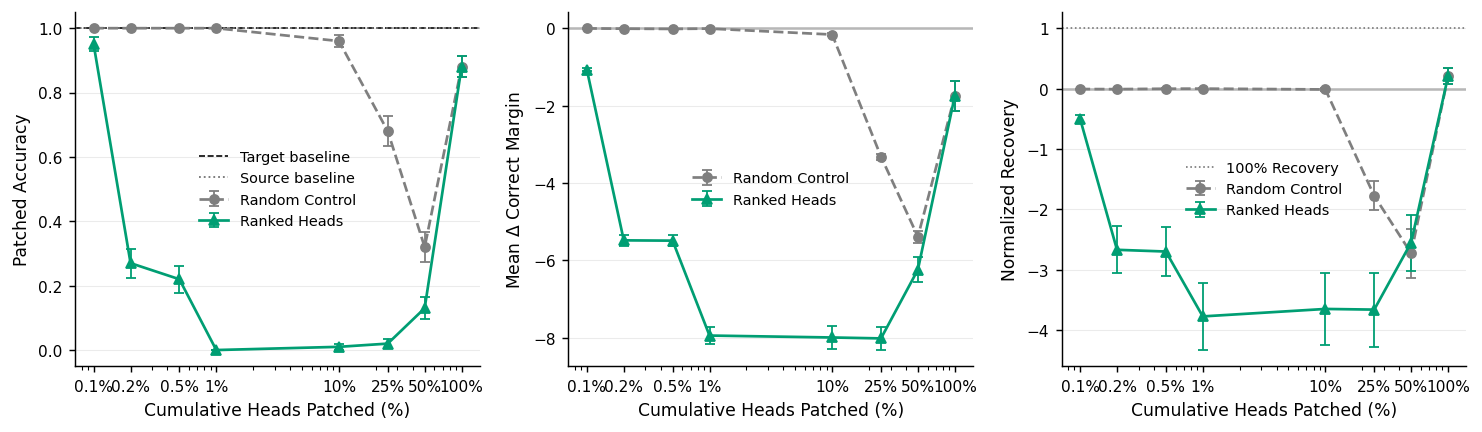

In [4]:
#%matplotlib inline
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

# ==========================================
# 1. LOAD & CLEAN
# ==========================================
INPUT_CSV = Path("/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/mp_s_present_ranked_heads_offset_-9.csv")
df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()

def parse_bool(series):
    if series.dtype == object:
        return series.astype(str).str.strip().str.lower().map({
            "true": True, "false": False, "1": True, "0": False
        })
    return series.astype(bool)

for col in ["target_present", "source_correct", "target_correct", "patched_correct"]:
    if col in df.columns:
        df[col] = parse_bool(df[col])

for col in ["patch_percentage", "selected_head_count", "source_margin", "target_margin", "patched_margin", "delta_margin", "recovery"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "recovery" in df.columns:
    df["recovery"] = df["recovery"].replace([np.inf, -np.inf], np.nan)

# ==========================================
# 2. AGGREGATE SUMMARY & ERROR BARS (SEM)
# ==========================================
def sem(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    return values.std(ddof=1) / np.sqrt(len(values)) if len(values) > 1 else 0.0

group_columns = ["patch_percentage", "selected_head_count", "selection_type"]
if "ranking_group" in df.columns:
    group_columns.insert(0, "ranking_group")

summary = (
    df.groupby(group_columns, as_index=False)
    .agg(
        n_pairs=("trial", "nunique"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        patched_accuracy_sem=("patched_correct", sem),
        mean_delta_margin=("delta_margin", "mean"),
        delta_margin_sem=("delta_margin", sem),
        mean_recovery=("recovery", "mean"),
        recovery_sem=("recovery", sem),
    )
    .sort_values(group_columns)
    .reset_index(drop=True)
)

# Display tabular summary in notebook
display(summary)

# ==========================================
# 3. INLINE VISUALIZATION
# ==========================================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.5,
    "figure.dpi": 130,
})

styles = {
    "ranked": {"color": "#009E73", "marker": "^", "linestyle": "-", "label": "Ranked Heads"},
    "random": {"color": "#7f7f7f", "marker": "o", "linestyle": "--", "label": "Random Control"},
}

metrics = [
    ("patched_accuracy", "patched_accuracy_sem", "Patched Accuracy", (-0.05, 1.05)),
    ("mean_delta_margin", "delta_margin_sem", r"Mean $\Delta$ Correct Margin", None),
    ("mean_recovery", "recovery_sem", "Normalized Recovery", None),
]

percentages = sorted(summary["patch_percentage"].dropna().unique())
is_single_percentage = len(percentages) == 1

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4), dpi=130)

for ax, (metric, err_col, ylabel, ylim) in zip(axes, metrics):
    for selection_type in summary["selection_type"].unique():
        sub_df = summary[summary["selection_type"] == selection_type].sort_values("patch_percentage")
        st = styles.get(selection_type, styles["ranked"])
        
        if is_single_percentage:
            x_pos = 0 if selection_type == "ranked" else 1
            ax.errorbar(
                x_pos, sub_df[metric].iloc[0], yerr=sub_df[err_col].iloc[0],
                color=st["color"], marker=st["marker"], capsize=3.5, elinewidth=1.2,
                markersize=6.5, label=st["label"], linestyle="none"
            )
        else:
            ax.errorbar(
                sub_df["patch_percentage"], sub_df[metric], yerr=sub_df[err_col],
                color=st["color"], marker=st["marker"], linestyle=st["linestyle"],
                markersize=5, capsize=2.5, elinewidth=1.0, label=st["label"]
            )

    # Baseline annotations
    if metric == "patched_accuracy":
        tgt_acc = summary["target_accuracy"].iloc[0]
        src_acc = summary["source_accuracy"].iloc[0]
        ax.axhline(tgt_acc, color="black", linestyle="--", linewidth=0.9, label="Target baseline")
        ax.axhline(src_acc, color="0.45", linestyle=":", linewidth=1.0, label="Source baseline")
    elif metric in {"mean_delta_margin", "mean_recovery"}:
        ax.axhline(0, color="black", linewidth=0.8, linestyle="-", zorder=1)
        if metric == "mean_recovery":
            ax.axhline(1.0, color="0.45", linestyle=":", linewidth=0.9, label="100% Recovery")

    # Axes formatting
    if is_single_percentage:
        types = list(summary["selection_type"].unique())
        ax.set_xticks(range(len(types)))
        ax.set_xticklabels([t.capitalize() for t in types])
        ax.set_xlim(-0.5, len(types) - 0.5)
        ax.set_xlabel(f"Intervention ({percentages[0]:g}%)")
    else:
        if len(percentages) > 2:
            ax.set_xscale("log")
        ax.set_xticks(percentages)
        ax.set_xticklabels([f"{v:g}%" for v in percentages])
        ax.set_xlabel("Cumulative Heads Patched (%)")

    ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)

    ax.grid(axis="y", color="0.9", linewidth=0.6, alpha=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, loc="best")

plt.tight_layout()
plt.show()

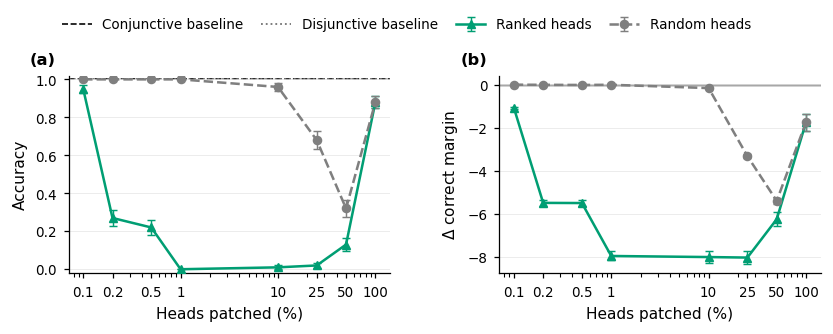

Saved figure to:
mp_s_present_head_patching_neurips.pdf


In [5]:
# ==========================================
# 3. NEURIPS-STYLE FIGURE:
#    BEHAVIOR + DELTA MARGIN ONLY
# ==========================================

from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_PDF =  "mp_s_present_head_patching_neurips.pdf"

# NeurIPS-ish compact typography
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

styles = {
    "ranked": {
        "color": "#009E73",
        "marker": "^",
        "linestyle": "-",
        "label": "Ranked heads",
    },
    "random": {
        "color": "#7f7f7f",
        "marker": "o",
        "linestyle": "--",
        "label": "Random heads",
    },
}

metrics = [
    (
        "patched_accuracy",
        "patched_accuracy_sem",
        "Accuracy",
        (-0.02, 1.02),
    ),
    (
        "mean_delta_margin",
        "delta_margin_sem",
        r"$\Delta$ correct margin",
        None,
    ),
]

percentages = sorted(
    summary["patch_percentage"].dropna().unique()
)

is_single_percentage = len(percentages) == 1


# ==========================================
# CREATE FIGURE
# ==========================================

# ~6.5 inches = approximately full NeurIPS text width
fig, axes = plt.subplots(
    1,
    2,
    figsize=(6.5, 2.45),
    sharex=False,
)


for ax_idx, (
    ax,
    (metric, err_col, ylabel, ylim),
) in enumerate(zip(axes, metrics)):

    # --------------------------------------
    # Ranked + random intervention curves
    # --------------------------------------

    for selection_type in ["ranked", "random"]:

        if selection_type not in summary["selection_type"].unique():
            continue

        sub_df = (
            summary[
                summary["selection_type"] == selection_type
            ]
            .sort_values("patch_percentage")
            .copy()
        )

        st = styles[selection_type]

        if is_single_percentage:

            x_pos = 0 if selection_type == "ranked" else 1

            ax.errorbar(
                x_pos,
                sub_df[metric].iloc[0],
                yerr=sub_df[err_col].iloc[0],
                color=st["color"],
                marker=st["marker"],
                markersize=5,
                markeredgewidth=0.8,
                capsize=2.5,
                elinewidth=0.9,
                linestyle="none",
                label=st["label"],
                zorder=3,
            )

        else:

            ax.errorbar(
                sub_df["patch_percentage"],
                sub_df[metric],
                yerr=sub_df[err_col],
                color=st["color"],
                marker=st["marker"],
                markeredgewidth=0.8,
                linestyle=st["linestyle"],
                markersize=4.5,
                capsize=2,
                elinewidth=0.8,
                label=st["label"],
                zorder=3,
            )


    # --------------------------------------
    # Baselines
    # --------------------------------------

    if metric == "patched_accuracy":

        target_acc = summary["target_accuracy"].iloc[0]
        source_acc = summary["source_accuracy"].iloc[0]

        ax.axhline(
            target_acc,
            color="black",
            linestyle="--",
            linewidth=0.9,
            label="Conjunctive baseline",
            zorder=1,
        )

        ax.axhline(
            source_acc,
            color="0.45",
            linestyle=":",
            linewidth=1.0,
            label="Disjunctive baseline",
            zorder=1,
        )

    elif metric == "mean_delta_margin":

        ax.axhline(
            0,
            color="black",
            linewidth=0.75,
            linestyle="-",
            zorder=1,
        )


    # --------------------------------------
    # X axis
    # --------------------------------------

    if is_single_percentage:

        types = [
            t for t in ["ranked", "random"]
            if t in summary["selection_type"].unique()
        ]

        ax.set_xticks(range(len(types)))

        ax.set_xticklabels([
            styles[t]["label"]
            for t in types
        ])

        ax.set_xlim(
            -0.5,
            len(types) - 0.5,
        )

        ax.set_xlabel(
            f"Heads patched ({percentages[0]:g}%)"
        )

    else:

        if len(percentages) > 2:
            ax.set_xscale("log")

        ax.set_xticks(percentages)

        ax.set_xticklabels([
            f"{v:g}" for v in percentages
        ])

        ax.set_xlabel("Heads patched (%)")


    # --------------------------------------
    # Y axis / styling
    # --------------------------------------

    ax.set_ylabel(ylabel)

    if ylim is not None:
        ax.set_ylim(*ylim)

    ax.grid(
        axis="y",
        color="0.90",
        linewidth=0.5,
        alpha=0.8,
        zorder=0,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        direction="out",
        length=3,
        width=0.7,
    )

    # Panel labels
    ax.text(
        -0.12,
        1.04,
        f"({'ab'[ax_idx]})",
        transform=ax.transAxes,
        fontsize=9,
        fontweight="bold",
        va="bottom",
        ha="left",
    )


# ==========================================
# SHARED LEGEND
# ==========================================

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=4,
    frameon=False,
    columnspacing=1.3,
    handlelength=2.2,
)


# ==========================================
# LAYOUT + SAVE
# ==========================================

fig.subplots_adjust(
    left=0.10,
    right=0.99,
    bottom=0.20,
    top=0.82,
    wspace=0.34,
)

fig.savefig(
    OUTPUT_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.02,
)

plt.show()

print(f"Saved figure to:\n{OUTPUT_PDF}")


Summary:


,source_pairing,selection_type,patch_percentage,n,source_accuracy,target_accuracy,patched_accuracy,mean_delta_margin
0,matched,random,0.1,100,1.0,1.0,1.00,-0.00375
1,matched,random,0.2,100,1.0,1.0,1.00,-0.01125
2,matched,random,0.5,100,1.0,1.0,1.00,-0.01750
3,matched,random,1.0,100,1.0,1.0,1.00,-0.00875
4,matched,random,10.0,100,1.0,1.0,0.96,-0.16250
5,matched,random,25.0,100,1.0,1.0,0.68,-3.31625
6,matched,random,50.0,100,1.0,1.0,0.32,-5.38750
7,matched,random,100.0,100,1.0,1.0,0.88,-1.74500
8,matched,ranked,0.1,100,1.0,1.0,0.95,-1.07250
9,matched,ranked,0.2,100,1.0,1.0,0.27,-5.48125


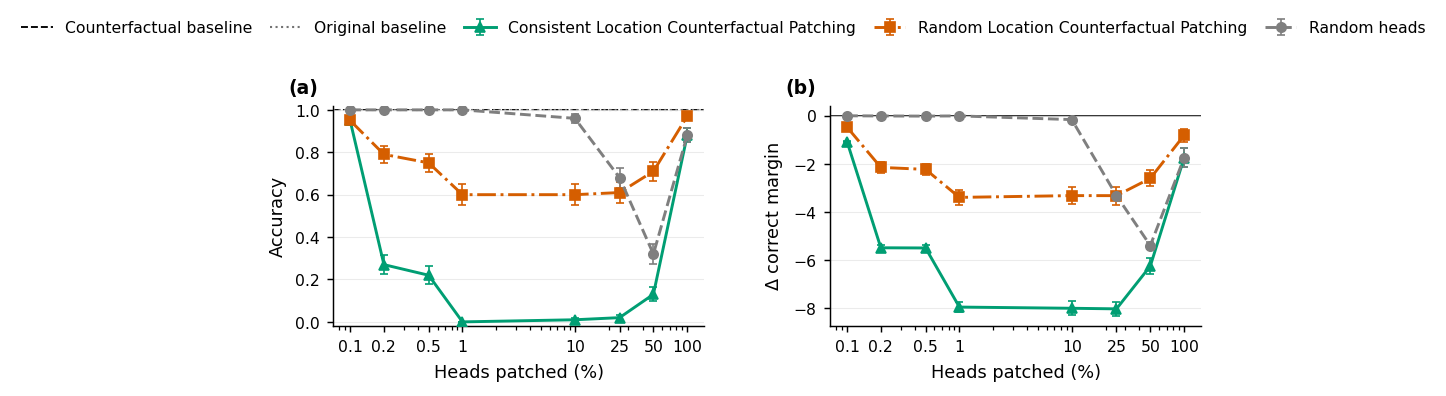

Saved figure to:
/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/mp_s_present_head_patching_spatial_control_neurips.pdf


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ==========================================================
# PATHS
# ==========================================================

MATCHED_CSV = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "mp_s_present_ranked_heads_offset_-9.csv"
)

UNPAIRED_CSV = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "mp_s_present_ranked_heads_unpaired_offset_-9.csv"
)

OUTPUT_PDF = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "mp_s_present_head_patching_spatial_control_neurips.pdf"
)


# ==========================================================
# LOAD + CLEAN
# ==========================================================

def load_results(path):
    df = pd.read_csv(path).copy()

    if "error" in df.columns:
        df = df[df["error"].isna()].copy()

    # Parse boolean columns if loaded as strings
    for col in [
        "target_present",
        "source_correct",
        "target_correct",
        "patched_correct",
    ]:
        if col in df.columns and df[col].dtype == object:
            df[col] = (
                df[col]
                .astype(str)
                .str.strip()
                .str.lower()
                .map({
                    "true": True,
                    "false": False,
                    "1": True,
                    "0": False,
                })
            )

    # Make sure important numeric columns are numeric
    for col in [
        "patch_percentage",
        "source_margin",
        "target_margin",
        "patched_margin",
        "delta_margin",
        "recovery",
    ]:
        if col in df.columns:
            df[col] = pd.to_numeric(
                df[col],
                errors="coerce",
            )

    return df


matched_df = load_results(MATCHED_CSV)
unpaired_df = load_results(UNPAIRED_CSV)


# ==========================================================
# SUMMARIZE
# ==========================================================

def make_summary(df):

    summary = (
        df.groupby(
            [
                "selection_type",
                "patch_percentage",
            ],
            as_index=False,
        )
        .agg(
            n=("patched_correct", "size"),

            source_accuracy=(
                "source_correct",
                "mean",
            ),

            target_accuracy=(
                "target_correct",
                "mean",
            ),

            patched_accuracy=(
                "patched_correct",
                "mean",
            ),

            mean_delta_margin=(
                "delta_margin",
                "mean",
            ),

            delta_margin_std=(
                "delta_margin",
                "std",
            ),
        )
    )

    # ------------------------------------------------------
    # Accuracy SEM
    # ------------------------------------------------------

    summary["patched_accuracy_sem"] = np.sqrt(
        summary["patched_accuracy"]
        * (1 - summary["patched_accuracy"])
        / summary["n"]
    )

    # ------------------------------------------------------
    # Delta-margin SEM
    # ------------------------------------------------------

    summary["delta_margin_sem"] = (
        summary["delta_margin_std"]
        / np.sqrt(summary["n"])
    )

    return summary


matched_summary = make_summary(matched_df)
unpaired_summary = make_summary(unpaired_df)


# Label the source-pairing condition
matched_summary["source_pairing"] = "matched"
unpaired_summary["source_pairing"] = "unpaired"


# ==========================================================
# COMBINE
# ==========================================================

plot_df = pd.concat(
    [
        matched_summary,
        unpaired_summary,
    ],
    ignore_index=True,
)


# ==========================================================
# SANITY CHECK
# ==========================================================

print("\nSummary:")
display(
    plot_df[
        [
            "source_pairing",
            "selection_type",
            "patch_percentage",
            "n",
            "source_accuracy",
            "target_accuracy",
            "patched_accuracy",
            "mean_delta_margin",
        ]
    ].sort_values(
        [
            "source_pairing",
            "selection_type",
            "patch_percentage",
        ]
    )
)


# ==========================================================
# NEURIPS-STYLE TYPOGRAPHY
# ==========================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


# ==========================================================
# PLOT STYLES
# ==========================================================

styles = {

    # Main causal intervention
    ("ranked", "matched"): {
        "color": "#009E73",
        "marker": "^",
        "linestyle": "-",
        "label": "Consistent Location Counterfactual Patching",
    },

    # Spatial correspondence control
    ("ranked", "unpaired"): {
        "color": "#D55E00",
        "marker": "s",
        "linestyle": "-.",
        "label": "Random Location Counterfactual Patching",
    },

    # Head-selection control
    ("random", "matched"): {
        "color": "#7f7f7f",
        "marker": "o",
        "linestyle": "--",
        "label": "Random heads",
    },
}


# ==========================================================
# METRICS
# ==========================================================

metrics = [

    (
        "patched_accuracy",
        "patched_accuracy_sem",
        "Accuracy",
        (-0.02, 1.02),
    ),

    (
        "mean_delta_margin",
        "delta_margin_sem",
        r"$\Delta$ correct margin",
        None,
    ),

]


percentages = sorted(
    plot_df[
        "patch_percentage"
    ].dropna().unique()
)

is_single_percentage = (
    len(percentages) == 1
)


# ==========================================================
# CREATE FIGURE
# ==========================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(6.5, 2.45),
    sharex=False,
)


# ==========================================================
# DRAW PANELS
# ==========================================================

for ax_idx, (
    ax,
    (
        metric,
        err_col,
        ylabel,
        ylim,
    ),
) in enumerate(
    zip(
        axes,
        metrics,
    )
):

    # ======================================================
    # INTERVENTION CURVES
    # ======================================================

    for (
        selection_type,
        pairing,
    ), st in styles.items():

        sub_df = plot_df[
            (
                plot_df["selection_type"]
                == selection_type
            )
            &
            (
                plot_df["source_pairing"]
                == pairing
            )
        ].copy()

        if len(sub_df) == 0:
            continue

        sub_df = sub_df.sort_values(
            "patch_percentage"
        )

        # --------------------------------------------------
        # Single-percentage case
        # --------------------------------------------------

        if is_single_percentage:

            available_conditions = []

            for key in styles:

                key_df = plot_df[
                    (
                        plot_df["selection_type"]
                        == key[0]
                    )
                    &
                    (
                        plot_df["source_pairing"]
                        == key[1]
                    )
                ]

                if len(key_df) > 0:
                    available_conditions.append(
                        key
                    )

            x_pos = available_conditions.index(
                (
                    selection_type,
                    pairing,
                )
            )

            ax.errorbar(
                x_pos,
                sub_df[metric].iloc[0],
                yerr=sub_df[err_col].iloc[0],

                color=st["color"],
                marker=st["marker"],

                markersize=5,
                markeredgewidth=0.8,

                capsize=2.5,
                elinewidth=0.9,

                linestyle="none",

                label=st["label"],

                zorder=3,
            )

        # --------------------------------------------------
        # Multiple percentages
        # --------------------------------------------------

        else:

            ax.errorbar(
                sub_df["patch_percentage"],
                sub_df[metric],

                yerr=sub_df[err_col],

                color=st["color"],
                marker=st["marker"],
                linestyle=st["linestyle"],

                markeredgewidth=0.8,
                markersize=4.5,

                capsize=2,
                elinewidth=0.8,

                label=st["label"],

                zorder=3,
            )


    # ======================================================
    # BASELINES
    # ======================================================

    if metric == "patched_accuracy":

        # Use the matched experiment's baselines.
        #
        # These correspond to the normal:
        #
        # original_i
        # counterfactual_i

        baseline_df = matched_summary

        target_acc = (
            baseline_df[
                "target_accuracy"
            ].iloc[0]
        )

        source_acc = (
            baseline_df[
                "source_accuracy"
            ].iloc[0]
        )

        # Counterfactual baseline
        ax.axhline(
            target_acc,
            color="black",
            linestyle="--",
            linewidth=0.9,
            label="Counterfactual baseline",
            zorder=1,
        )

        # Original baseline
        ax.axhline(
            source_acc,
            color="0.45",
            linestyle=":",
            linewidth=1.0,
            label="Original baseline",
            zorder=1,
        )


    elif metric == "mean_delta_margin":

        # No change from counterfactual baseline
        ax.axhline(
            0,
            color="black",
            linewidth=0.75,
            linestyle="-",
            zorder=1,
        )


    # ======================================================
    # X AXIS
    # ======================================================

    if is_single_percentage:

        available_conditions = []

        for key in styles:

            key_df = plot_df[
                (
                    plot_df["selection_type"]
                    == key[0]
                )
                &
                (
                    plot_df["source_pairing"]
                    == key[1]
                )
            ]

            if len(key_df) > 0:
                available_conditions.append(
                    key
                )

        ax.set_xticks(
            range(
                len(
                    available_conditions
                )
            )
        )

        ax.set_xticklabels(
            [
                styles[key]["label"]
                for key
                in available_conditions
            ],
            rotation=15,
            ha="right",
        )

        ax.set_xlim(
            -0.5,
            len(
                available_conditions
            ) - 0.5,
        )

        ax.set_xlabel(
            f"Heads patched "
            f"({percentages[0]:g}%)"
        )


    else:

        # Log scale is especially useful here because:
        #
        # 0.1, 0.2, 0.5, 1, 10
        #
        # are highly unevenly spaced.

        if len(percentages) > 2:
            ax.set_xscale(
                "log"
            )

        ax.set_xticks(
            percentages
        )

        ax.set_xticklabels(
            [
                f"{v:g}"
                for v in percentages
            ]
        )

        ax.set_xlabel(
            "Heads patched (%)"
        )


    # ======================================================
    # Y AXIS
    # ======================================================

    ax.set_ylabel(
        ylabel
    )

    if ylim is not None:
        ax.set_ylim(
            *ylim
        )


    # ======================================================
    # VISUAL STYLE
    # ======================================================

    ax.grid(
        axis="y",
        color="0.90",
        linewidth=0.5,
        alpha=0.8,
        zorder=0,
    )

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )

    ax.tick_params(
        direction="out",
        length=3,
        width=0.7,
    )


    # ======================================================
    # PANEL LABELS
    # ======================================================

    ax.text(
        -0.12,
        1.04,

        f"({'ab'[ax_idx]})",

        transform=ax.transAxes,

        fontsize=9,
        fontweight="bold",

        va="bottom",
        ha="left",
    )


# ==========================================================
# SHARED LEGEND
# ==========================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)

# Remove duplicate entries while preserving order
unique_legend = {}

for handle, label in zip(
    handles,
    labels,
):
    if label not in unique_legend:
        unique_legend[label] = handle


fig.legend(
    list(
        unique_legend.values()
    ),

    list(
        unique_legend.keys()
    ),

    loc="upper center",

    bbox_to_anchor=(
        0.5,
        1.07,
    ),

    ncol=5,

    frameon=False,

    columnspacing=1.15,

    handlelength=2.0,
)


# ==========================================================
# LAYOUT
# ==========================================================

fig.subplots_adjust(
    left=0.10,
    right=0.99,

    bottom=0.20,
    top=0.80,

    wspace=0.34,
)


# ==========================================================
# SAVE
# ==========================================================

fig.savefig(
    OUTPUT_PDF,

    format="pdf",

    bbox_inches="tight",

    pad_inches=0.02,
)

plt.show()

print(
    f"Saved figure to:\n"
    f"{OUTPUT_PDF}"
)

# Token -11 analyss

Rows by 2x2 cell:
ranking_group   target_present  selection_type
target_absent   False           random            1350
                                ranked            1350
                True            random            1350
                                ranked            1350
target_present  False           random            1350
                                ranked            1350
                True            random            1350
                                ranked            1350
dtype: int64

Summary:
 ranking_group  target_present selection_type intervention_component  patch_percentage  selected_head_count  n_pairs  n_random_runs  source_accuracy  target_accuracy  patched_accuracy  patched_accuracy_sem  mean_delta_margin  delta_margin_sem  mean_recovery  recovery_sem
 target_absent           False         random       attention_matrix               0.1                    1       50              1              1.0             0.52              0.52              0.0

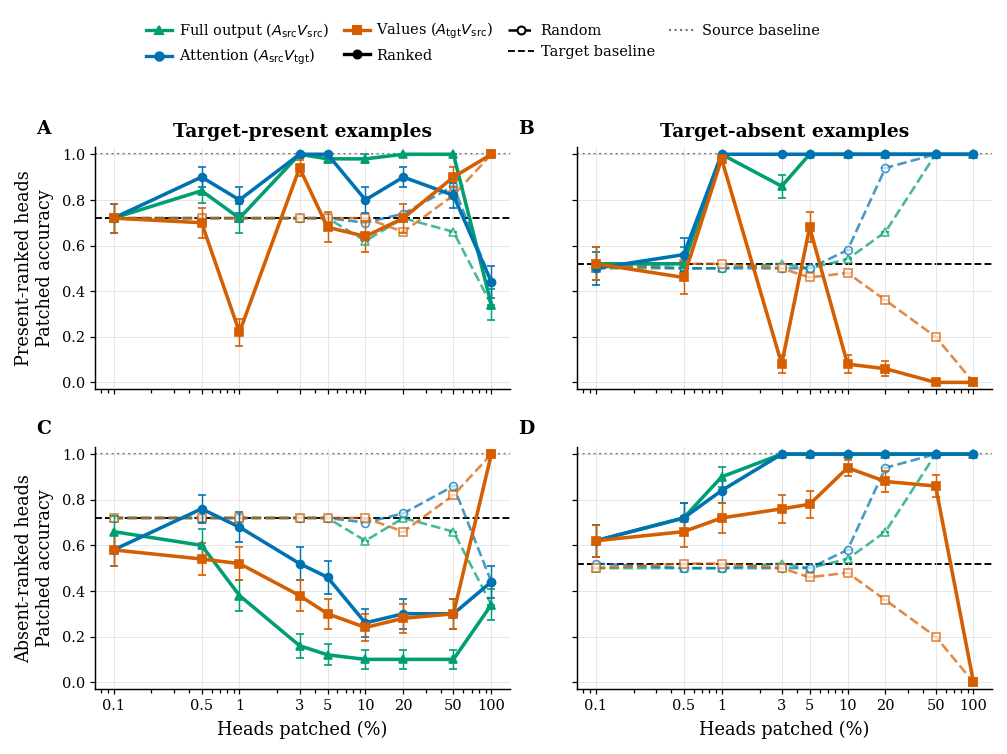

KeyboardInterrupt: 

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_cumulative_offset_-11.csv"
)

OUTPUT_DIR = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_cross_eval_figures_offset_-11"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================================
# LOAD AND CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
]:
    df[column] = parse_bool(df[column])

for column in [
    "patch_percentage",
    "selected_head_count",
    "delta_margin",
    "recovery",
]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["recovery"] = df["recovery"].replace(
    [np.inf, -np.inf], np.nan
)

required_columns = {
    "trial",
    "target_present",
    "ranking_group",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
    "source_correct",
    "target_correct",
    "patched_correct",
    "delta_margin",
    "recovery",
}

missing = required_columns - set(df.columns)
if missing:
    raise ValueError(
        f"CSV is missing columns: {sorted(missing)}.\n"
        "Use the output from the new cross-evaluation patching run."
    )

expected_ranking_groups = {"target_present", "target_absent"}
observed_ranking_groups = set(df["ranking_group"].dropna().unique())
missing_groups = expected_ranking_groups - observed_ranking_groups
if missing_groups:
    raise ValueError(
        "The CSV does not contain the full cross-evaluation. Missing "
        f"ranking_group values: {sorted(missing_groups)}"
    )

observed_cells = set(
    df[["target_present", "ranking_group"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)
expected_cells = {
    (True, "target_present"),
    (False, "target_present"),
    (True, "target_absent"),
    (False, "target_absent"),
}
missing_cells = expected_cells - observed_cells
if missing_cells:
    raise ValueError(
        "The CSV is missing cross-evaluation cells: "
        f"{sorted(missing_cells, key=str)}"
    )

print("Rows by 2x2 cell:")
print(
    df.groupby(
        ["ranking_group", "target_present", "selection_type"]
    ).size()
)


# ==========================================================
# SUMMARIZE RANKED AND RANDOM CONDITIONS
# ==========================================================


def sem(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) <= 1:
        return 0.0
    return values.std(ddof=1) / np.sqrt(len(values))


group_columns = [
    "ranking_group",
    "target_present",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
]

ranked_df = df[df["selection_type"] == "ranked"].copy()

ranked_summary = (
    ranked_df.groupby(group_columns, as_index=False)
    .agg(
        n_pairs=("trial", "nunique"),
        n_random_runs=("trial", lambda values: 0),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        patched_accuracy_sem=("patched_correct", sem),
        mean_delta_margin=("delta_margin", "mean"),
        delta_margin_sem=("delta_margin", sem),
        mean_recovery=("recovery", "mean"),
        recovery_sem=("recovery", sem),
    )
)

random_df = df[df["selection_type"] == "random"].copy()

if not random_df.empty:
    if "random_seed" not in random_df.columns:
        raise ValueError("Random rows require a random_seed column.")
    if random_df["random_seed"].isna().any():
        raise ValueError("Some random-control rows are missing random_seed.")

    # First average trials within each independently sampled random-head set.
    random_seed_summary = (
        random_df.groupby(
            group_columns + ["random_seed"], as_index=False
        )
        .agg(
            n_pairs_seed=("trial", "nunique"),
            source_accuracy_seed=("source_correct", "mean"),
            target_accuracy_seed=("target_correct", "mean"),
            patched_accuracy_seed=("patched_correct", "mean"),
            mean_delta_margin_seed=("delta_margin", "mean"),
            mean_recovery_seed=("recovery", "mean"),
        )
    )

    # Then compute uncertainty across random-head samples.
    random_summary = (
        random_seed_summary.groupby(group_columns, as_index=False)
        .agg(
            n_pairs=("n_pairs_seed", "max"),
            n_random_runs=("random_seed", "nunique"),
            source_accuracy=("source_accuracy_seed", "mean"),
            target_accuracy=("target_accuracy_seed", "mean"),
            patched_accuracy=("patched_accuracy_seed", "mean"),
            patched_accuracy_sem=("patched_accuracy_seed", sem),
            mean_delta_margin=("mean_delta_margin_seed", "mean"),
            delta_margin_sem=("mean_delta_margin_seed", sem),
            mean_recovery=("mean_recovery_seed", "mean"),
            recovery_sem=("mean_recovery_seed", sem),
        )
    )

    summary = pd.concat(
        [ranked_summary, random_summary], ignore_index=True
    )
else:
    summary = ranked_summary.copy()

summary = summary.sort_values(
    [
        "ranking_group",
        "target_present",
        "selection_type",
        "intervention_component",
        "patch_percentage",
    ]
).reset_index(drop=True)

print("\nSummary:")
print(summary.to_string(index=False))

if not random_df.empty:
    run_counts = random_summary[
        [
            "ranking_group",
            "target_present",
            "intervention_component",
            "patch_percentage",
            "n_random_runs",
        ]
    ]
    unexpected = run_counts[run_counts["n_random_runs"] != 10]
    if not unexpected.empty:
        print(
            "\nWARNING: Some random controls do not contain exactly "
            "10 independent random seeds:"
        )
        print(unexpected.to_string(index=False))


# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

component_order = [
    "full_head_output",
    "attention_matrix",
    "value_vectors",
]

component_labels = {
    "full_head_output": (
        r"Full output ($A_{\mathrm{src}}V_{\mathrm{src}}$)"
    ),
    "attention_matrix": (
        r"Attention ($A_{\mathrm{src}}V_{\mathrm{tgt}}$)"
    ),
    "value_vectors": (
        r"Values ($A_{\mathrm{tgt}}V_{\mathrm{src}}$)"
    ),
}

colors = {
    "full_head_output": "#009E73",
    "attention_matrix": "#0072B2",
    "value_vectors": "#D55E00",
}

markers = {
    "full_head_output": "^",
    "attention_matrix": "o",
    "value_vectors": "s",
}

selection_styles = {
    "ranked": {
        "linestyle": "-",
        "linewidth": 1.7,
        "alpha": 1.0,
        "markerfacecolor": None,
    },
    "random": {
        "linestyle": "--",
        "linewidth": 1.25,
        "alpha": 0.72,
        "markerfacecolor": "white",
    },
}

percentages = sorted(
    summary["patch_percentage"].dropna().unique()
)

ranking_rows = [
    ("target_present", "Present-ranked heads"),
    ("target_absent", "Absent-ranked heads"),
]

evaluation_columns = [
    (True, "Target-present examples"),
    (False, "Target-absent examples"),
]

metric_settings = {
    "patched_accuracy": {
        "error": "patched_accuracy_sem",
        "ylabel": "Patched accuracy",
        "stem": "patched_accuracy_cross_eval",
        "ylim": (-0.03, 1.03),
    },
    "mean_delta_margin": {
        "error": "delta_margin_sem",
        "ylabel": r"Mean $\Delta$ correct-answer margin",
        "stem": "delta_margin_cross_eval",
        "ylim": None,
    },
    "mean_recovery": {
        "error": "recovery_sem",
        "ylabel": "Normalized recovery",
        "stem": "normalized_recovery_cross_eval",
        "ylim": None,
    },
}


def plot_component_curves(ax, data, metric, error_column):
    for selection_type in ["ranked", "random"]:
        for component in component_order:
            component_data = (
                data[
                    (data["selection_type"] == selection_type)
                    & (data["intervention_component"] == component)
                ]
                .sort_values("patch_percentage")
            )

            if component_data.empty:
                continue

            style = selection_styles[selection_type]
            marker_face = (
                colors[component]
                if style["markerfacecolor"] is None
                else style["markerfacecolor"]
            )

            ax.errorbar(
                component_data["patch_percentage"],
                component_data[metric],
                yerr=component_data[error_column],
                color=colors[component],
                marker=markers[component],
                markerfacecolor=marker_face,
                markeredgecolor=colors[component],
                markeredgewidth=0.8,
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                markersize=3.8,
                capsize=1.7,
                capthick=0.7,
                elinewidth=0.7,
                alpha=style["alpha"],
                zorder=3 if selection_type == "ranked" else 2,
            )

    ax.set_xscale("log")
    ax.set_xticks(percentages)
    ax.set_xticklabels([f"{value:g}" for value in percentages])
    ax.grid(
        axis="both",
        color="0.88",
        linewidth=0.45,
        alpha=0.8,
        zorder=0,
    )
    ax.tick_params(axis="both", width=0.6, length=2.5, pad=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


component_handles = [
    Line2D(
        [0], [0],
        color=colors[component],
        marker=markers[component],
        markerfacecolor=colors[component],
        markeredgecolor=colors[component],
        linestyle="-",
        linewidth=1.6,
        markersize=4,
        label=component_labels[component],
    )
    for component in component_order
]

selection_handles = [
    Line2D(
        [0], [0],
        color="black",
        linestyle="-",
        marker="o",
        markerfacecolor="black",
        markeredgecolor="black",
        linewidth=1.6,
        markersize=3.8,
        label="Ranked",
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        marker="o",
        markerfacecolor="white",
        markeredgecolor="black",
        linewidth=1.2,
        markersize=3.8,
        label="Random",
    ),
]


# ==========================================================
# ONE SEPARATE 2x2 FIGURE PER METRIC
#
# Rows:    ranking used to choose heads
# Columns: examples on which those heads were patched
# ==========================================================

for metric, settings in metric_settings.items():
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.0, 5.05),
        sharex=True,
        sharey=True,
    )

    for row, (ranking_group, ranking_title) in enumerate(
        ranking_rows
    ):
        for column, (target_present, evaluation_title) in enumerate(
            evaluation_columns
        ):
            ax = axes[row, column]
            cell_df = summary[
                (summary["ranking_group"] == ranking_group)
                & (summary["target_present"] == target_present)
            ].copy()

            plot_component_curves(
                ax=ax,
                data=cell_df,
                metric=metric,
                error_column=settings["error"],
            )

            if row == 0:
                ax.set_title(
                    evaluation_title,
                    fontweight="semibold",
                    pad=5,
                )

            if column == 0:
                ax.set_ylabel(
                    f"{ranking_title}\n{settings['ylabel']}"
                )

            if row == 1:
                ax.set_xlabel("Heads patched (%)")

            if settings["ylim"] is not None:
                ax.set_ylim(*settings["ylim"])

            # Accuracy gets the corresponding evaluation baselines.
            if metric == "patched_accuracy" and not cell_df.empty:
                target_accuracy = cell_df["target_accuracy"].iloc[0]
                source_accuracy = cell_df["source_accuracy"].iloc[0]
                ax.axhline(
                    target_accuracy,
                    color="black",
                    linestyle="--",
                    linewidth=0.9,
                    zorder=1,
                )
                ax.axhline(
                    source_accuracy,
                    color="0.45",
                    linestyle=":",
                    linewidth=1.0,
                    zorder=1,
                )

            # Zero means no causal improvement for these metrics.
            if metric in {"mean_delta_margin", "mean_recovery"}:
                ax.axhline(
                    0,
                    color="black",
                    linewidth=0.8,
                    zorder=1,
                )

            # Recovery of one corresponds to full source-target recovery.
            if metric == "mean_recovery":
                ax.axhline(
                    1,
                    color="0.45",
                    linestyle=":",
                    linewidth=0.9,
                    zorder=1,
                )

    for label, ax in zip(["A", "B", "C", "D"], axes.flat):
        ax.text(
            -0.14,
            1.04,
            label,
            transform=ax.transAxes,
            fontsize=9,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False,
        )

    legend_handles = component_handles + selection_handles
    if metric == "patched_accuracy":
        legend_handles += [
            Line2D(
                [0], [0],
                color="black",
                linestyle="--",
                linewidth=0.9,
                label="Target baseline",
            ),
            Line2D(
                [0], [0],
                color="0.45",
                linestyle=":",
                linewidth=1.0,
                label="Source baseline",
            ),
        ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=4,
        frameon=False,
        columnspacing=1.0,
        handletextpad=0.45,
        handlelength=1.8,
        borderaxespad=0,
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.985,
        bottom=0.105,
        top=0.82,
        wspace=0.16,
        hspace=0.24,
    )

    out_pdf = OUTPUT_DIR / f"{settings['stem']}.pdf"
    out_png = OUTPUT_DIR / f"{settings['stem']}.png"

    # fig.savefig(out_pdf, bbox_inches="tight", pad_inches=0.02)
    # fig.savefig(
    #     out_png,
    #     dpi=300,
    #     bbox_inches="tight",
    #     pad_inches=0.02,
    # )
    plt.show()
    plt.close(fig)

    # print("Saved:", out_pdf)
    # print("Saved:", out_png)

Rows by 2x2 cell:
ranking_group   target_present  selection_type
target_absent   False           random            1350
                                ranked            1350
                True            random            1350
                                ranked            1350
target_present  False           random            1350
                                ranked            1350
                True            random            1350
                                ranked            1350
dtype: int64

Summary:
 ranking_group  target_present selection_type intervention_component  patch_percentage  selected_head_count  n_pairs  n_random_runs  source_accuracy  target_accuracy  patched_accuracy  patched_accuracy_sem  mean_delta_margin  delta_margin_sem  mean_recovery  recovery_sem
 target_absent           False         random       attention_matrix               0.1                    1       50              1              1.0             0.52              0.48              0.0

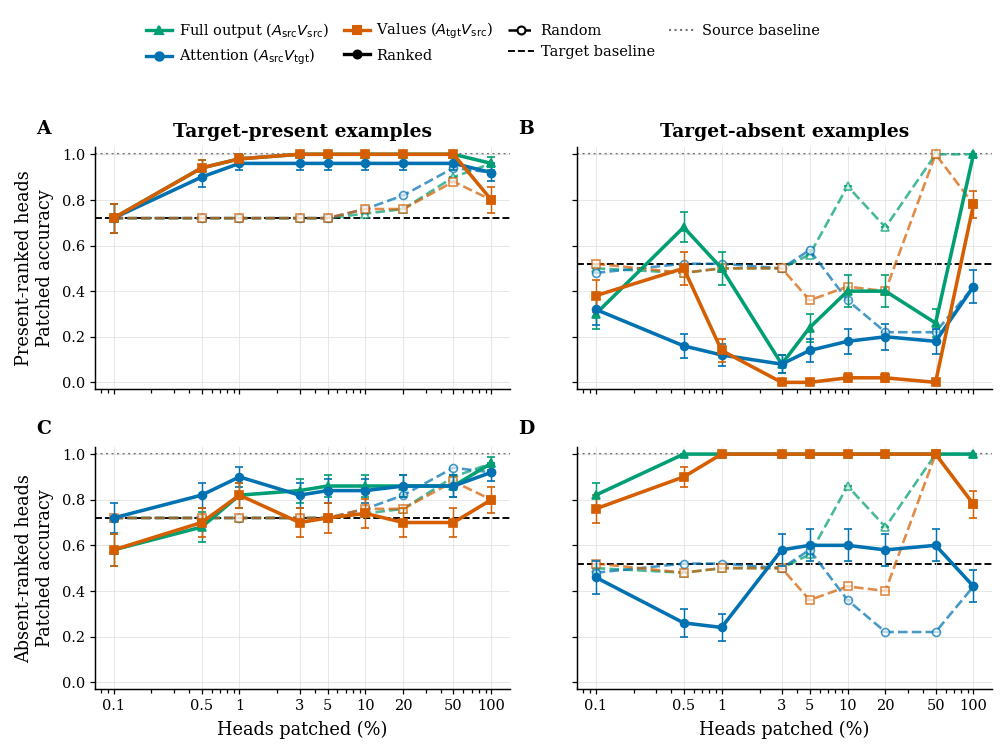

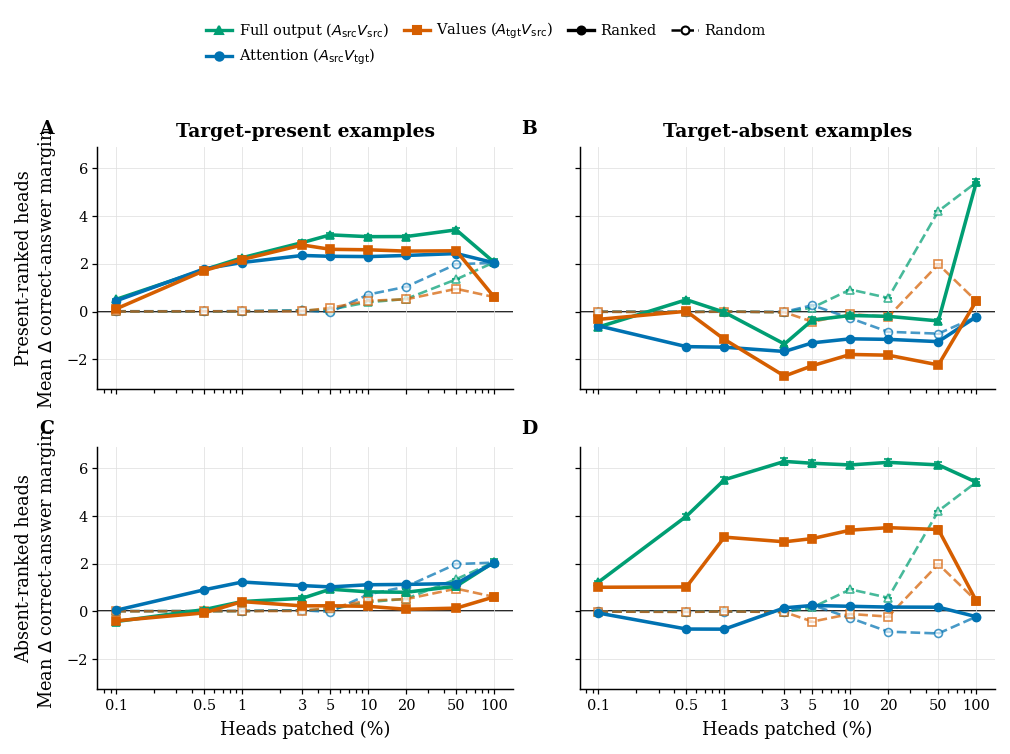

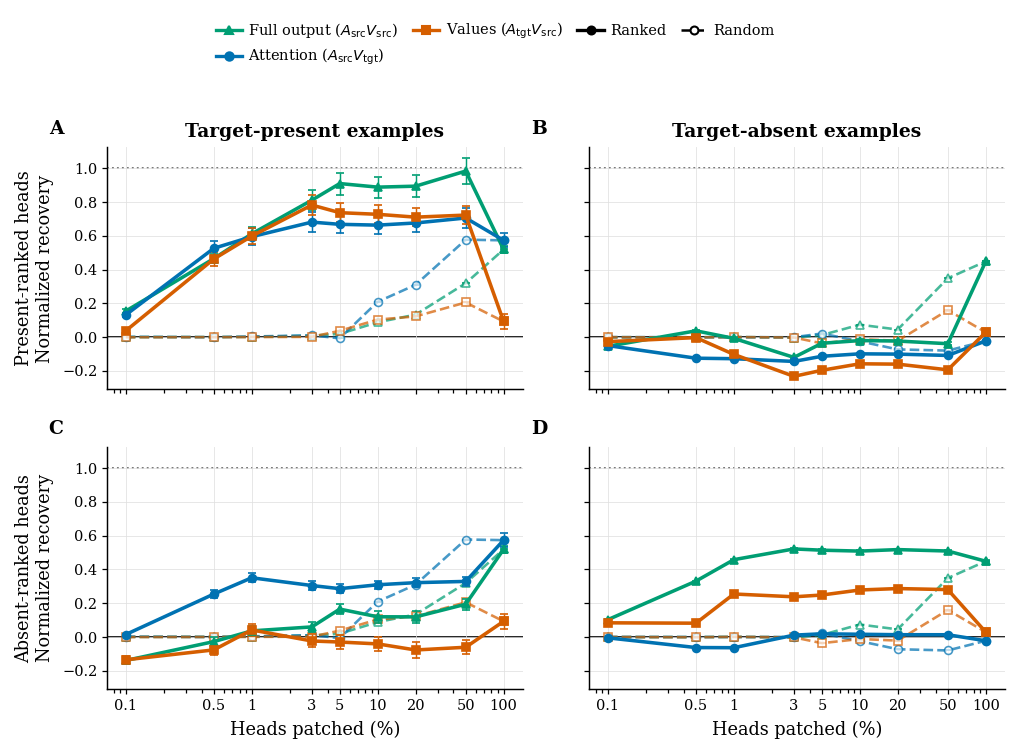

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_cumulative_offset_-5.csv"
)

OUTPUT_DIR = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_cross_eval_figures_offset_-5"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================================
# LOAD AND CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
]:
    df[column] = parse_bool(df[column])

for column in [
    "patch_percentage",
    "selected_head_count",
    "delta_margin",
    "recovery",
]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df["recovery"] = df["recovery"].replace(
    [np.inf, -np.inf], np.nan
)

required_columns = {
    "trial",
    "target_present",
    "ranking_group",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
    "source_correct",
    "target_correct",
    "patched_correct",
    "delta_margin",
    "recovery",
}

missing = required_columns - set(df.columns)
if missing:
    raise ValueError(
        f"CSV is missing columns: {sorted(missing)}.\n"
        "Use the output from the new cross-evaluation patching run."
    )

expected_ranking_groups = {"target_present", "target_absent"}
observed_ranking_groups = set(df["ranking_group"].dropna().unique())
missing_groups = expected_ranking_groups - observed_ranking_groups
if missing_groups:
    raise ValueError(
        "The CSV does not contain the full cross-evaluation. Missing "
        f"ranking_group values: {sorted(missing_groups)}"
    )

observed_cells = set(
    df[["target_present", "ranking_group"]]
    .drop_duplicates()
    .itertuples(index=False, name=None)
)
expected_cells = {
    (True, "target_present"),
    (False, "target_present"),
    (True, "target_absent"),
    (False, "target_absent"),
}
missing_cells = expected_cells - observed_cells
if missing_cells:
    raise ValueError(
        "The CSV is missing cross-evaluation cells: "
        f"{sorted(missing_cells, key=str)}"
    )

print("Rows by 2x2 cell:")
print(
    df.groupby(
        ["ranking_group", "target_present", "selection_type"]
    ).size()
)


# ==========================================================
# SUMMARIZE RANKED AND RANDOM CONDITIONS
# ==========================================================


def sem(series):
    values = pd.to_numeric(series, errors="coerce").dropna()
    if len(values) <= 1:
        return 0.0
    return values.std(ddof=1) / np.sqrt(len(values))


group_columns = [
    "ranking_group",
    "target_present",
    "selection_type",
    "intervention_component",
    "patch_percentage",
    "selected_head_count",
]

ranked_df = df[df["selection_type"] == "ranked"].copy()

ranked_summary = (
    ranked_df.groupby(group_columns, as_index=False)
    .agg(
        n_pairs=("trial", "nunique"),
        n_random_runs=("trial", lambda values: 0),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        patched_accuracy_sem=("patched_correct", sem),
        mean_delta_margin=("delta_margin", "mean"),
        delta_margin_sem=("delta_margin", sem),
        mean_recovery=("recovery", "mean"),
        recovery_sem=("recovery", sem),
    )
)

random_df = df[df["selection_type"] == "random"].copy()

if not random_df.empty:
    if "random_seed" not in random_df.columns:
        raise ValueError("Random rows require a random_seed column.")
    if random_df["random_seed"].isna().any():
        raise ValueError("Some random-control rows are missing random_seed.")

    # First average trials within each independently sampled random-head set.
    random_seed_summary = (
        random_df.groupby(
            group_columns + ["random_seed"], as_index=False
        )
        .agg(
            n_pairs_seed=("trial", "nunique"),
            source_accuracy_seed=("source_correct", "mean"),
            target_accuracy_seed=("target_correct", "mean"),
            patched_accuracy_seed=("patched_correct", "mean"),
            mean_delta_margin_seed=("delta_margin", "mean"),
            mean_recovery_seed=("recovery", "mean"),
        )
    )

    # Then compute uncertainty across random-head samples.
    random_summary = (
        random_seed_summary.groupby(group_columns, as_index=False)
        .agg(
            n_pairs=("n_pairs_seed", "max"),
            n_random_runs=("random_seed", "nunique"),
            source_accuracy=("source_accuracy_seed", "mean"),
            target_accuracy=("target_accuracy_seed", "mean"),
            patched_accuracy=("patched_accuracy_seed", "mean"),
            patched_accuracy_sem=("patched_accuracy_seed", sem),
            mean_delta_margin=("mean_delta_margin_seed", "mean"),
            delta_margin_sem=("mean_delta_margin_seed", sem),
            mean_recovery=("mean_recovery_seed", "mean"),
            recovery_sem=("mean_recovery_seed", sem),
        )
    )

    summary = pd.concat(
        [ranked_summary, random_summary], ignore_index=True
    )
else:
    summary = ranked_summary.copy()

summary = summary.sort_values(
    [
        "ranking_group",
        "target_present",
        "selection_type",
        "intervention_component",
        "patch_percentage",
    ]
).reset_index(drop=True)

print("\nSummary:")
print(summary.to_string(index=False))

if not random_df.empty:
    run_counts = random_summary[
        [
            "ranking_group",
            "target_present",
            "intervention_component",
            "patch_percentage",
            "n_random_runs",
        ]
    ]
    unexpected = run_counts[run_counts["n_random_runs"] != 10]
    if not unexpected.empty:
        print(
            "\nWARNING: Some random controls do not contain exactly "
            "10 independent random seeds:"
        )
        print(unexpected.to_string(index=False))


# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.7,
    "lines.linewidth": 1.5,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

component_order = [
    "full_head_output",
    "attention_matrix",
    "value_vectors",
]

component_labels = {
    "full_head_output": (
        r"Full output ($A_{\mathrm{src}}V_{\mathrm{src}}$)"
    ),
    "attention_matrix": (
        r"Attention ($A_{\mathrm{src}}V_{\mathrm{tgt}}$)"
    ),
    "value_vectors": (
        r"Values ($A_{\mathrm{tgt}}V_{\mathrm{src}}$)"
    ),
}

colors = {
    "full_head_output": "#009E73",
    "attention_matrix": "#0072B2",
    "value_vectors": "#D55E00",
}

markers = {
    "full_head_output": "^",
    "attention_matrix": "o",
    "value_vectors": "s",
}

selection_styles = {
    "ranked": {
        "linestyle": "-",
        "linewidth": 1.7,
        "alpha": 1.0,
        "markerfacecolor": None,
    },
    "random": {
        "linestyle": "--",
        "linewidth": 1.25,
        "alpha": 0.72,
        "markerfacecolor": "white",
    },
}

percentages = sorted(
    summary["patch_percentage"].dropna().unique()
)

ranking_rows = [
    ("target_present", "Present-ranked heads"),
    ("target_absent", "Absent-ranked heads"),
]

evaluation_columns = [
    (True, "Target-present examples"),
    (False, "Target-absent examples"),
]

metric_settings = {
    "patched_accuracy": {
        "error": "patched_accuracy_sem",
        "ylabel": "Patched accuracy",
        "stem": "patched_accuracy_cross_eval",
        "ylim": (-0.03, 1.03),
    },
    "mean_delta_margin": {
        "error": "delta_margin_sem",
        "ylabel": r"Mean $\Delta$ correct-answer margin",
        "stem": "delta_margin_cross_eval",
        "ylim": None,
    },
    "mean_recovery": {
        "error": "recovery_sem",
        "ylabel": "Normalized recovery",
        "stem": "normalized_recovery_cross_eval",
        "ylim": None,
    },
}


def plot_component_curves(ax, data, metric, error_column):
    for selection_type in ["ranked", "random"]:
        for component in component_order:
            component_data = (
                data[
                    (data["selection_type"] == selection_type)
                    & (data["intervention_component"] == component)
                ]
                .sort_values("patch_percentage")
            )

            if component_data.empty:
                continue

            style = selection_styles[selection_type]
            marker_face = (
                colors[component]
                if style["markerfacecolor"] is None
                else style["markerfacecolor"]
            )

            ax.errorbar(
                component_data["patch_percentage"],
                component_data[metric],
                yerr=component_data[error_column],
                color=colors[component],
                marker=markers[component],
                markerfacecolor=marker_face,
                markeredgecolor=colors[component],
                markeredgewidth=0.8,
                linestyle=style["linestyle"],
                linewidth=style["linewidth"],
                markersize=3.8,
                capsize=1.7,
                capthick=0.7,
                elinewidth=0.7,
                alpha=style["alpha"],
                zorder=3 if selection_type == "ranked" else 2,
            )

    ax.set_xscale("log")
    ax.set_xticks(percentages)
    ax.set_xticklabels([f"{value:g}" for value in percentages])
    ax.grid(
        axis="both",
        color="0.88",
        linewidth=0.45,
        alpha=0.8,
        zorder=0,
    )
    ax.tick_params(axis="both", width=0.6, length=2.5, pad=2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


component_handles = [
    Line2D(
        [0], [0],
        color=colors[component],
        marker=markers[component],
        markerfacecolor=colors[component],
        markeredgecolor=colors[component],
        linestyle="-",
        linewidth=1.6,
        markersize=4,
        label=component_labels[component],
    )
    for component in component_order
]

selection_handles = [
    Line2D(
        [0], [0],
        color="black",
        linestyle="-",
        marker="o",
        markerfacecolor="black",
        markeredgecolor="black",
        linewidth=1.6,
        markersize=3.8,
        label="Ranked",
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        marker="o",
        markerfacecolor="white",
        markeredgecolor="black",
        linewidth=1.2,
        markersize=3.8,
        label="Random",
    ),
]


# ==========================================================
# ONE SEPARATE 2x2 FIGURE PER METRIC
#
# Rows:    ranking used to choose heads
# Columns: examples on which those heads were patched
# ==========================================================

for metric, settings in metric_settings.items():
    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.0, 5.05),
        sharex=True,
        sharey=True,
    )

    for row, (ranking_group, ranking_title) in enumerate(
        ranking_rows
    ):
        for column, (target_present, evaluation_title) in enumerate(
            evaluation_columns
        ):
            ax = axes[row, column]
            cell_df = summary[
                (summary["ranking_group"] == ranking_group)
                & (summary["target_present"] == target_present)
            ].copy()

            plot_component_curves(
                ax=ax,
                data=cell_df,
                metric=metric,
                error_column=settings["error"],
            )

            if row == 0:
                ax.set_title(
                    evaluation_title,
                    fontweight="semibold",
                    pad=5,
                )

            if column == 0:
                ax.set_ylabel(
                    f"{ranking_title}\n{settings['ylabel']}"
                )

            if row == 1:
                ax.set_xlabel("Heads patched (%)")

            if settings["ylim"] is not None:
                ax.set_ylim(*settings["ylim"])

            # Accuracy gets the corresponding evaluation baselines.
            if metric == "patched_accuracy" and not cell_df.empty:
                target_accuracy = cell_df["target_accuracy"].iloc[0]
                source_accuracy = cell_df["source_accuracy"].iloc[0]
                ax.axhline(
                    target_accuracy,
                    color="black",
                    linestyle="--",
                    linewidth=0.9,
                    zorder=1,
                )
                ax.axhline(
                    source_accuracy,
                    color="0.45",
                    linestyle=":",
                    linewidth=1.0,
                    zorder=1,
                )

            # Zero means no causal improvement for these metrics.
            if metric in {"mean_delta_margin", "mean_recovery"}:
                ax.axhline(
                    0,
                    color="black",
                    linewidth=0.8,
                    zorder=1,
                )

            # Recovery of one corresponds to full source-target recovery.
            if metric == "mean_recovery":
                ax.axhline(
                    1,
                    color="0.45",
                    linestyle=":",
                    linewidth=0.9,
                    zorder=1,
                )

    for label, ax in zip(["A", "B", "C", "D"], axes.flat):
        ax.text(
            -0.14,
            1.04,
            label,
            transform=ax.transAxes,
            fontsize=9,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False,
        )

    legend_handles = component_handles + selection_handles
    if metric == "patched_accuracy":
        legend_handles += [
            Line2D(
                [0], [0],
                color="black",
                linestyle="--",
                linewidth=0.9,
                label="Target baseline",
            ),
            Line2D(
                [0], [0],
                color="0.45",
                linestyle=":",
                linewidth=1.0,
                label="Source baseline",
            ),
        ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.995),
        ncol=4,
        frameon=False,
        columnspacing=1.0,
        handletextpad=0.45,
        handlelength=1.8,
        borderaxespad=0,
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.985,
        bottom=0.105,
        top=0.82,
        wspace=0.16,
        hspace=0.24,
    )

    out_pdf = OUTPUT_DIR / f"{settings['stem']}.pdf"
    out_png = OUTPUT_DIR / f"{settings['stem']}.png"

    # fig.savefig(out_pdf, bbox_inches="tight", pad_inches=0.02)
    # fig.savefig(
    #     out_png,
    #     dpi=300,
    #     bbox_inches="tight",
    #     pad_inches=0.02,
    # )
    plt.show()
    plt.close(fig)

    # print("Saved:", out_pdf)
    # print("Saved:", out_png)

# Can cosine similarity predict correctness

 layer  head  correct_n  incorrect_n  correct_mean  incorrect_mean  mean_difference_correct_minus_incorrect  mannwhitney_u      p_value
    15     4         36           14      0.402843        0.427775                                -0.024932          200.0 2.658159e-01
    15    14         36           14      0.781083        0.809191                                -0.028108           95.0 7.210101e-04
    15    15         36           14      0.834039        0.758684                                 0.075356          466.0 3.968031e-06
    15    20         36           14      0.842907        0.635251                                 0.207655          497.0 1.271823e-07
    15    21         36           14      0.530110        0.434323                                 0.095787          422.0 2.499111e-04
    16     5         36           14      0.492594        0.473586                                 0.019008          302.0 2.848282e-01
    17    22         36           14      0.5764

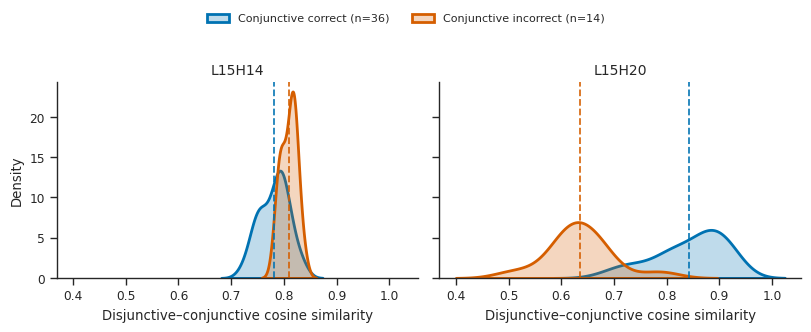

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from scipy.stats import mannwhitneyu

RESULTS_DIR = Path(
    "../Results/disj40_to_conj40_head_outputs_top8_offset_-9"
)

payload = torch.load(
    RESULTS_DIR / "head_outputs.pt",
    map_location="cpu",
    weights_only=False,
)

vectors = payload["head_outputs"]       # [examples, heads, head_dim]
metadata = payload["metadata"]
selected_heads = payload["selected_heads"]

# Find the disjunctive and conjunctive example belonging to each trial.
trial_indices = {}

for index, meta in enumerate(metadata):
    if not bool(meta["target_present"]):
        continue

    trial_indices.setdefault(meta["trial"], {})[
        meta["condition"]
    ] = index

rows = []

for trial, indices in trial_indices.items():
    if not {"disjunctive", "conjunctive"} <= indices.keys():
        continue

    disj_index = indices["disjunctive"]
    conj_index = indices["conjunctive"]

    disj_vectors = vectors[disj_index]
    conj_vectors = vectors[conj_index]

    # One cosine similarity per selected head.
    similarities = F.cosine_similarity(
        disj_vectors,
        conj_vectors,
        dim=-1,
    )

    conjunctive_correct = bool(
        metadata[conj_index]["correct"]
    )

    for head_index, similarity in enumerate(similarities):
        head = selected_heads[head_index]

        rows.append({
            "trial": trial,
            "layer": int(head["layer"]),
            "head": int(head["head"]),
            "rank": int(head["rank"]),
            "conjunctive_correct": conjunctive_correct,
            "cosine_similarity": float(similarity),
            "disjunctive_margin": float(
                metadata[disj_index]["margin"]
            ),
            "conjunctive_margin": float(
                metadata[conj_index]["margin"]
            ),
        })

df = pd.DataFrame(rows)
df.to_csv(
    RESULTS_DIR / "paired_cosine_similarities.csv",
    index=False,
)

# ==========================================================
# STATISTICAL SUMMARY
# ==========================================================

summary_rows = []

for (layer, head), group in df.groupby(["layer", "head"]):
    correct = group.loc[
        group["conjunctive_correct"],
        "cosine_similarity",
    ]
    incorrect = group.loc[
        ~group["conjunctive_correct"],
        "cosine_similarity",
    ]

    if len(correct) > 0 and len(incorrect) > 0:
        statistic, p_value = mannwhitneyu(
            correct,
            incorrect,
            alternative="two-sided",
        )
    else:
        statistic, p_value = float("nan"), float("nan")

    summary_rows.append({
        "layer": layer,
        "head": head,
        "correct_n": len(correct),
        "incorrect_n": len(incorrect),
        "correct_mean": correct.mean(),
        "incorrect_mean": incorrect.mean(),
        "mean_difference_correct_minus_incorrect": (
            correct.mean() - incorrect.mean()
        ),
        "mannwhitney_u": statistic,
        "p_value": p_value,
    })

summary = pd.DataFrame(summary_rows)
summary.to_csv(
    RESULTS_DIR / "paired_cosine_similarity_summary.csv",
    index=False,
)

print(summary.to_string(index=False))# ==========================================================
# OVERLAID COSINE-SIMILARITY DISTRIBUTIONS
# Top two ranked heads
# ==========================================================

sns.set_theme(style="ticks", context="paper")

top_two = (
    df[["rank", "layer", "head"]]
    .drop_duplicates()
    .sort_values("rank")
    .head(2)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8.2, 3.2),
    sharex=True,
    sharey=True,
)

colors = {
    True: "#0072B2",
    False: "#D55E00",
}

labels = {
    True: "Conjunctive correct",
    False: "Conjunctive incorrect",
}

for ax, head_info in zip(axes, top_two.itertuples(index=False)):
    head_df = df[
        (df["layer"] == head_info.layer)
        & (df["head"] == head_info.head)
    ].copy()

    for correct in (True, False):
        values = head_df.loc[
            head_df["conjunctive_correct"] == correct,
            "cosine_similarity",
        ].dropna()

        if len(values) < 2:
            continue

        sns.kdeplot(
            x=values,
            ax=ax,
            color=colors[correct],
            fill=True,
            alpha=0.25,
            linewidth=2,
            common_norm=False,
            label=f"{labels[correct]} (n={len(values)})",
        )

        ax.axvline(
            values.mean(),
            color=colors[correct],
            linestyle="--",
            linewidth=1.3,
            alpha=0.9,
        )

    ax.set_title(
        f"L{head_info.layer}H{head_info.head}",
        fontsize=10,
    )
    ax.set_xlabel("Disjunctive–conjunctive cosine similarity")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Density")
axes[1].set_ylabel("")

# Keep one shared legend.
handles, legend_labels = axes[0].get_legend_handles_labels()

for ax in axes:
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

fig.legend(
    handles,
    legend_labels,
    frameon=False,
    fontsize=8,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=2,
)

fig.tight_layout(rect=[0, 0, 1, 0.90])

fig.savefig(
    "top2_cosine_similarity_distributions.pdf",
    bbox_inches="tight",
)



plt.show()

## Attention Masks

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# LOAD
# ==========================================================

RESULTS_DIR = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_attention_maps_top8_offset_-9"
)

TOKEN_PATH = os.path.join(
    RESULTS_DIR,
    "token_attention.csv",
)

SELECTED_HEADS_PATH = os.path.join(
    RESULTS_DIR,
    "selected_heads.csv",
)

df = pd.read_csv(TOKEN_PATH)
selected_heads = (
    pd.read_csv(SELECTED_HEADS_PATH)
    .sort_values("rank")
)

# Normalize target_present if necessary
if df["target_present"].dtype == object:
    df["target_present"] = (
        df["target_present"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
        })
    )

print("Rows:", len(df))
print("Trials:", df["trial"].nunique())
display(selected_heads)

Rows: 510400
Trials: 100


,layer,head,ranking_score,rank
0,15,14,1.6425,1
1,15,20,1.4825,2
2,16,5,1.1625,3
3,17,22,0.8400,4
4,17,26,0.8075,5
5,15,4,0.6975,6
6,15,15,0.6800,7
7,15,21,0.6475,8


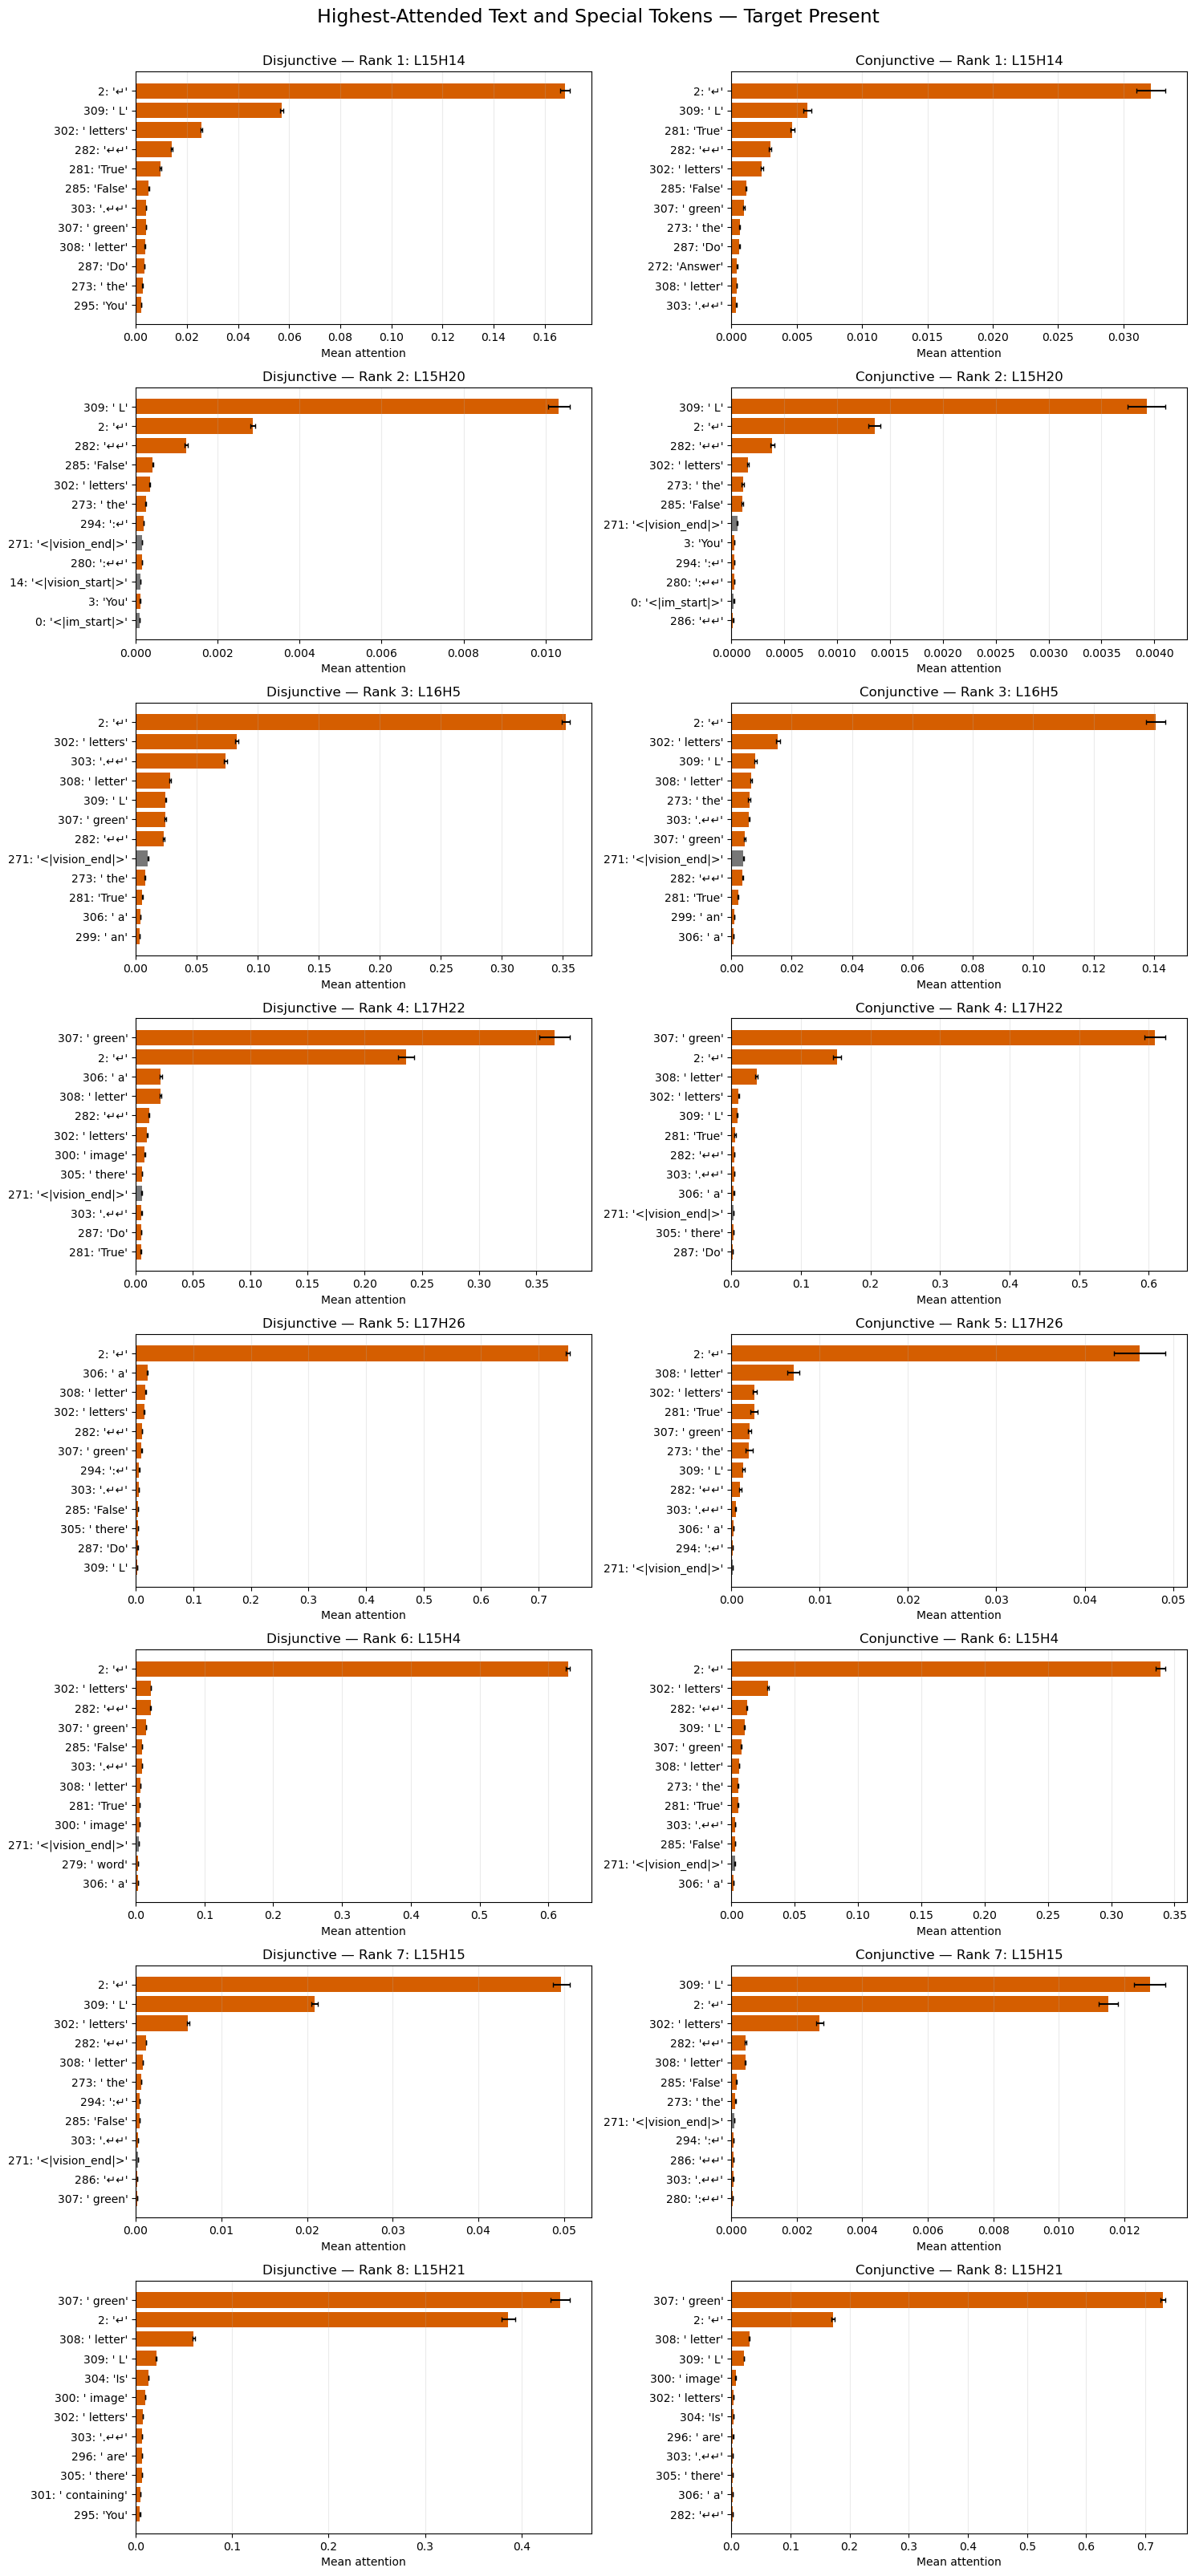

In [10]:
# ==========================================================
# SETTINGS
# ==========================================================

TARGET_PRESENT = True
TOP_N = 12

text_df = df[
    (df["target_present"] == TARGET_PRESENT)
    & (df["token_group"].isin(["text", "special"]))
].copy()

# Average each token position across trials
text_summary = (
    text_df.groupby(
        [
            "condition",
            "layer",
            "head",
            "rank",
            "key_position",
            "token_id",
            "token_text",
            "token_group",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        mean_attention=("attention", "mean"),
        sem_attention=(
            "attention",
            lambda values: (
                values.std(ddof=1) / np.sqrt(len(values))
                if len(values) > 1
                else 0.0
            ),
        ),
    )
)

head_order = [
    (int(row.layer), int(row.head), int(row.rank))
    for row in selected_heads.itertuples(index=False)
]

colors = {
    "text": "#D55E00",
    "special": "#777777",
}

fig, axes = plt.subplots(
    len(head_order),
    2,
    figsize=(15, 4 * len(head_order)),
)

for row_index, (layer, head, rank) in enumerate(head_order):

    for column_index, condition in enumerate(
        ["disjunctive", "conjunctive"]
    ):
        ax = axes[row_index, column_index]

        part = (
            text_summary[
                (text_summary["layer"] == layer)
                & (text_summary["head"] == head)
                & (text_summary["condition"] == condition)
            ]
            .nlargest(TOP_N, "mean_attention")
            .sort_values("mean_attention")
        )

        labels = [
            f"{int(position)}: {str(token).replace(chr(10), '↵')!r}"
            for position, token in zip(
                part["key_position"],
                part["token_text"],
            )
        ]

        bar_colors = [
            colors.get(group, "#999999")
            for group in part["token_group"]
        ]

        ax.barh(
            labels,
            part["mean_attention"],
            xerr=part["sem_attention"],
            color=bar_colors,
            capsize=2,
        )

        ax.set_title(
            f"{condition.title()} — Rank {rank}: L{layer}H{head}"
        )

        ax.set_xlabel("Mean attention")
        ax.grid(axis="x", alpha=0.25)

target_label = (
    "Target Present"
    if TARGET_PRESENT
    else "Target Absent"
)

fig.suptitle(
    f"Highest-Attended Text and Special Tokens — {target_label}",
    fontsize=17,
    y=1.002,
)

plt.tight_layout()
plt.show()

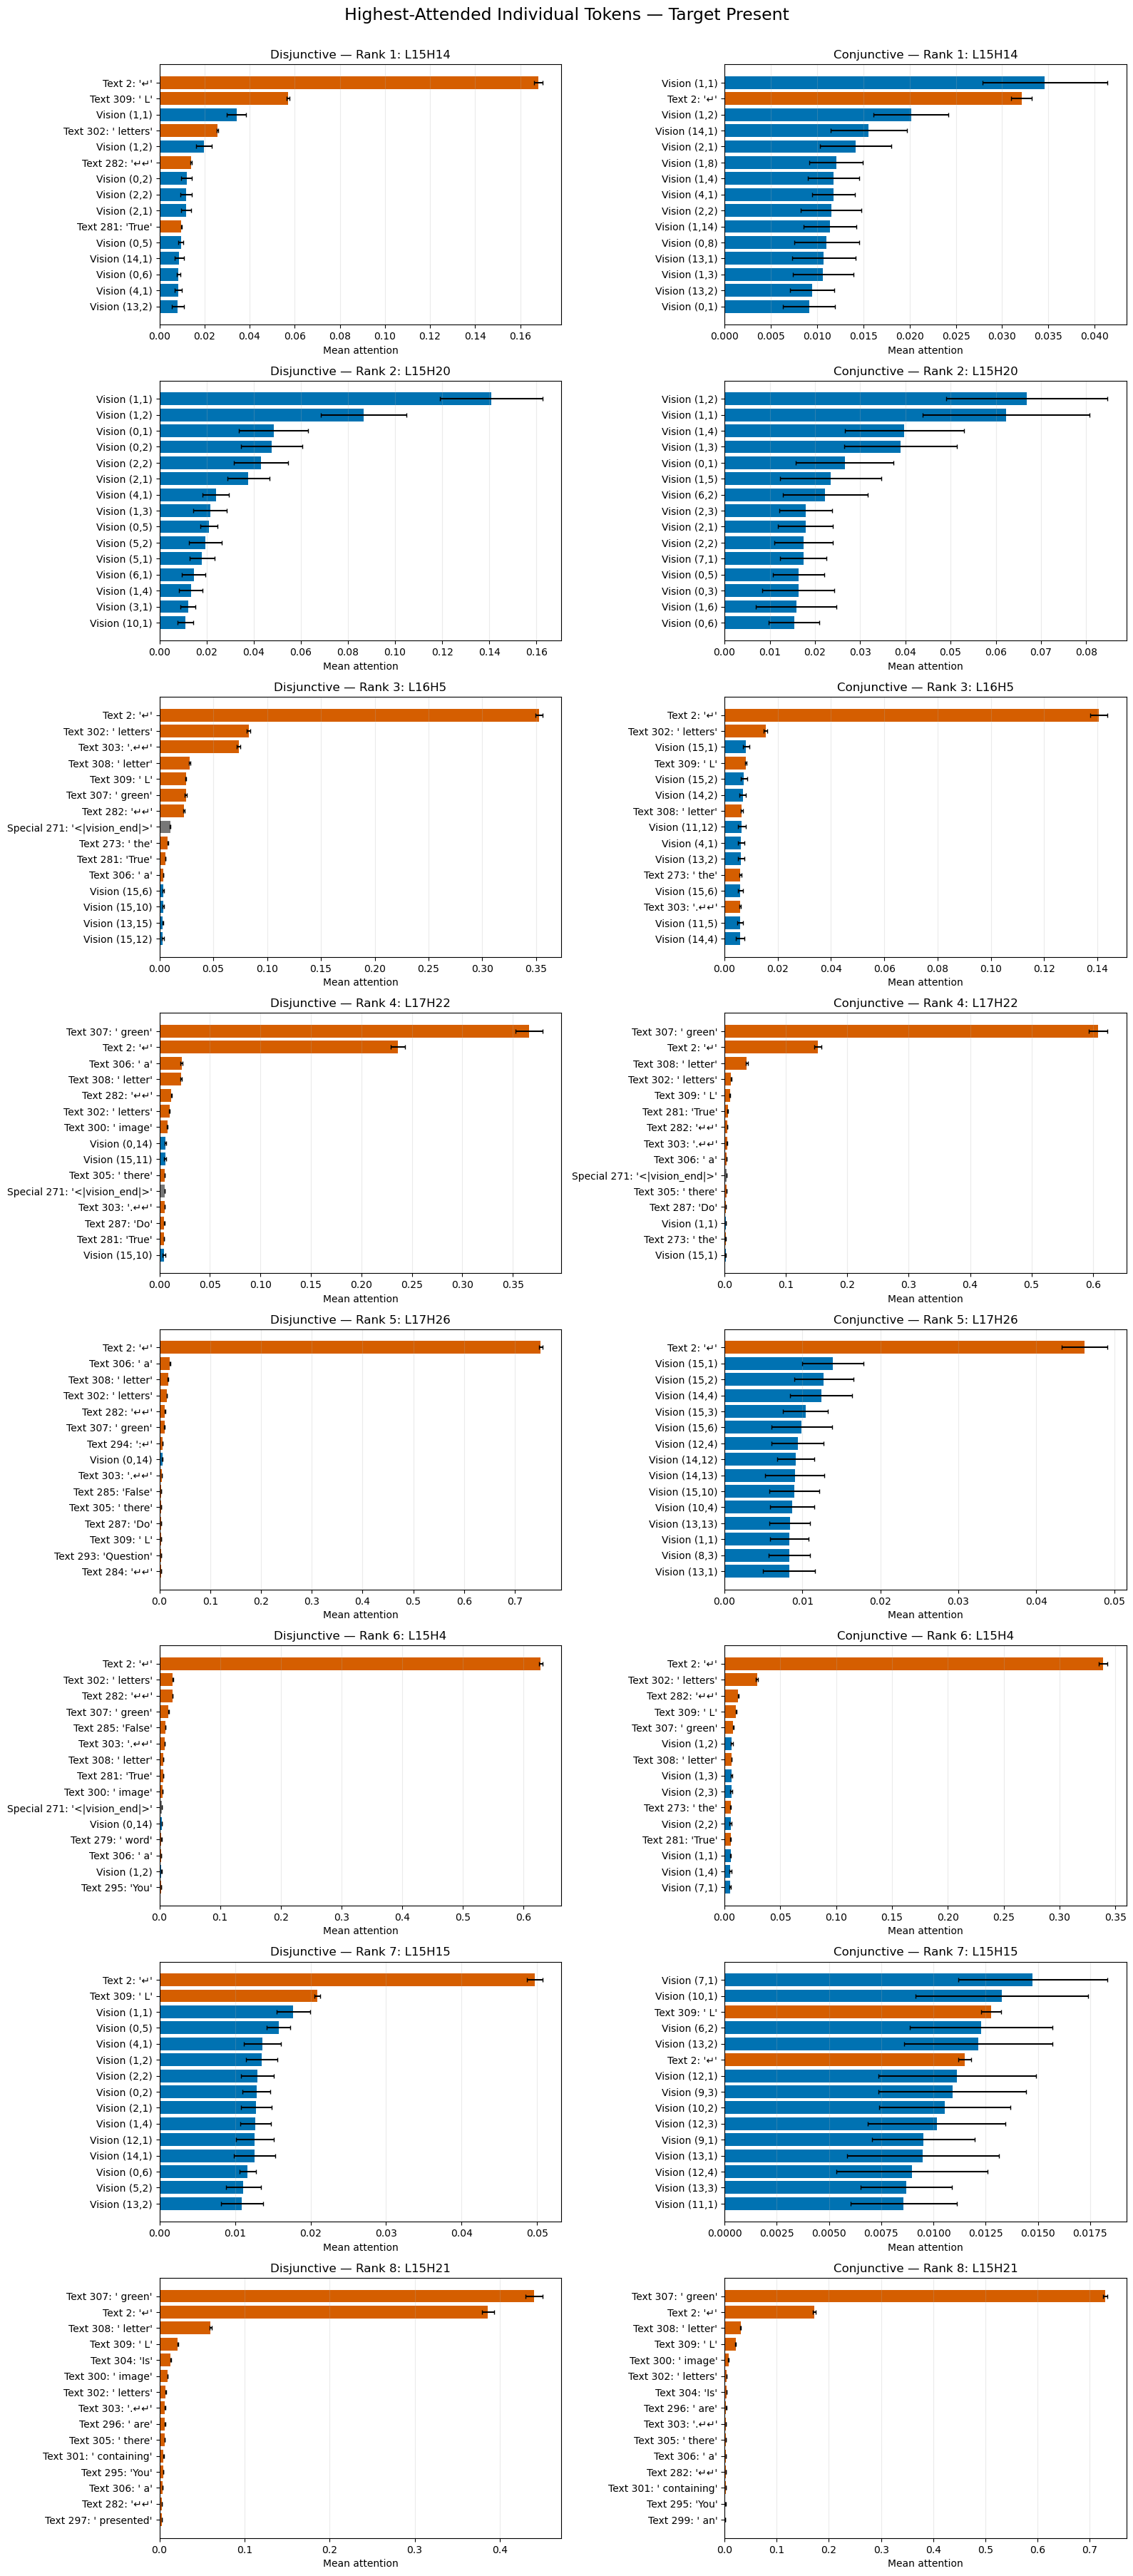

In [9]:
# ==========================================================
# TOP TOKENS ACROSS VISION, TEXT, AND SPECIAL TOKENS
# ==========================================================

TARGET_PRESENT = True
TOP_N = 15

all_summary = (
    df[df["target_present"] == TARGET_PRESENT]
    .groupby(
        [
            "condition",
            "layer",
            "head",
            "rank",
            "key_position",
            "token_id",
            "token_text",
            "token_group",
            "visual_row",
            "visual_col",
        ],
        as_index=False,
        dropna=False,
    )
    .agg(
        mean_attention=("attention", "mean"),
        sem_attention=(
            "attention",
            lambda values: (
                values.std(ddof=1) / np.sqrt(len(values))
                if len(values) > 1
                else 0.0
            ),
        ),
    )
)


def make_token_label(row):
    if row["token_group"] == "vision":
        return (
            f"Vision "
            f"({int(row['visual_row'])},"
            f"{int(row['visual_col'])})"
        )

    token = str(row["token_text"])
    token = token.replace("\n", "↵")
    token = token.replace("\t", "⇥")

    return (
        f"{row['token_group'].title()} "
        f"{int(row['key_position'])}: {token!r}"
    )


colors = {
    "vision": "#0072B2",
    "text": "#D55E00",
    "special": "#777777",
}

fig, axes = plt.subplots(
    len(head_order),
    2,
    figsize=(16, 4.5 * len(head_order)),
)

for row_index, (layer, head, rank) in enumerate(head_order):

    for column_index, condition in enumerate(
        ["disjunctive", "conjunctive"]
    ):
        ax = axes[row_index, column_index]

        part = (
            all_summary[
                (all_summary["layer"] == layer)
                & (all_summary["head"] == head)
                & (all_summary["condition"] == condition)
            ]
            .nlargest(TOP_N, "mean_attention")
            .copy()
        )

        part["display_label"] = part.apply(
            make_token_label,
            axis=1,
        )

        part = part.sort_values("mean_attention")

        bar_colors = [
            colors[group]
            for group in part["token_group"]
        ]

        ax.barh(
            part["display_label"],
            part["mean_attention"],
            xerr=part["sem_attention"],
            color=bar_colors,
            capsize=2,
        )

        ax.set_title(
            f"{condition.title()} — Rank {rank}: L{layer}H{head}"
        )

        ax.set_xlabel("Mean attention")
        ax.grid(axis="x", alpha=0.25)

fig.suptitle(
    (
        "Highest-Attended Individual Tokens "
        f"— {'Target Present' if TARGET_PRESENT else 'Target Absent'}"
    ),
    fontsize=17,
    y=1.002,
)

plt.tight_layout()
plt.show()

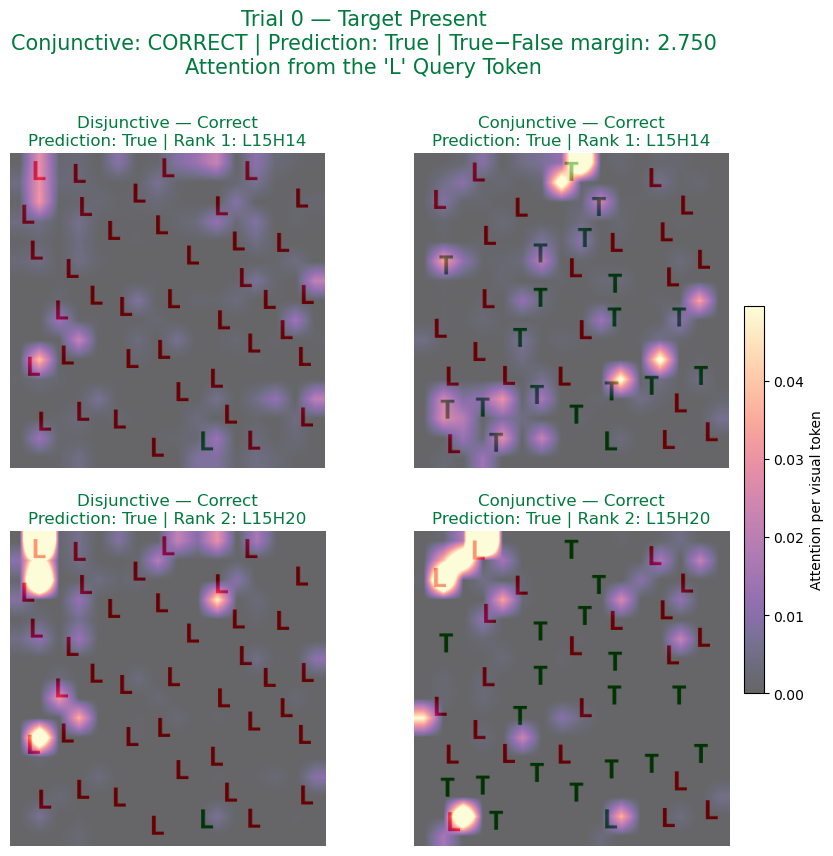

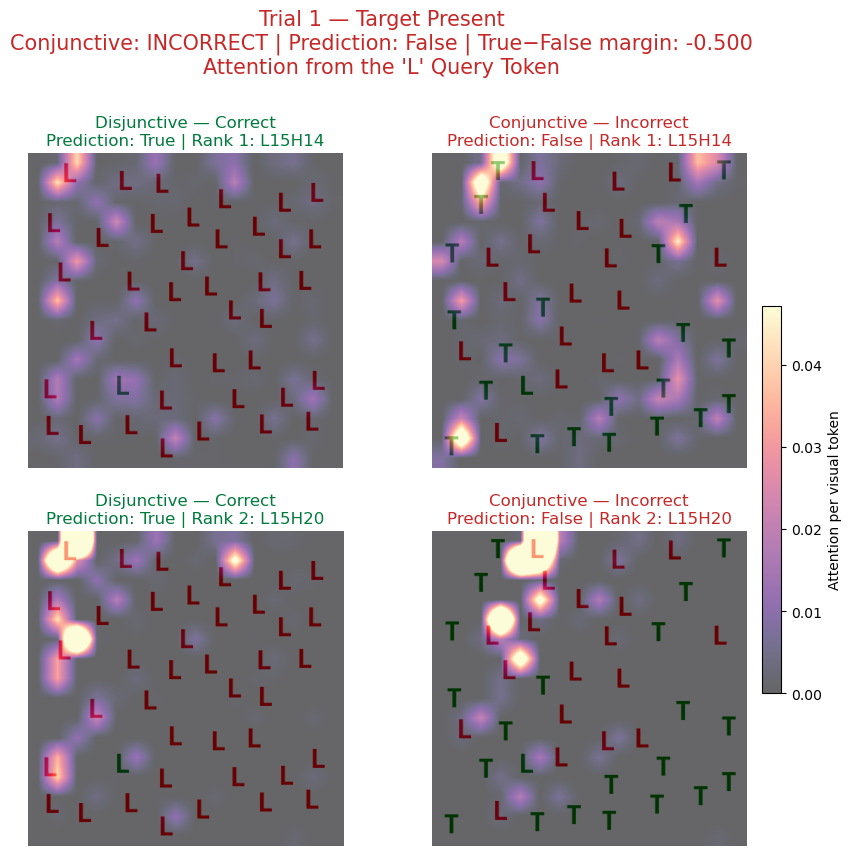

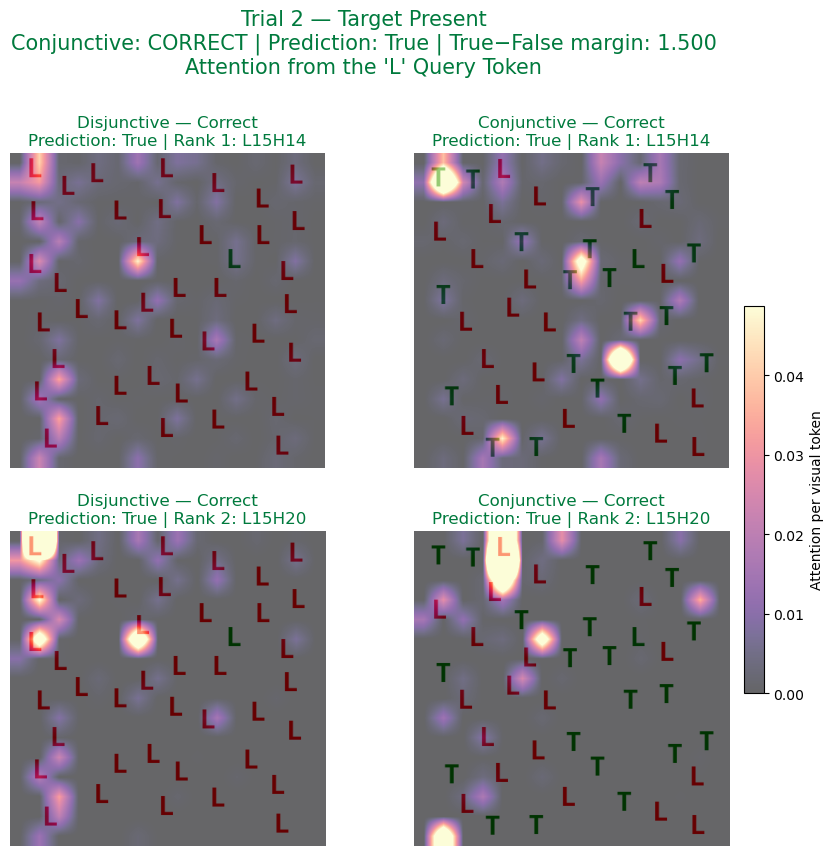

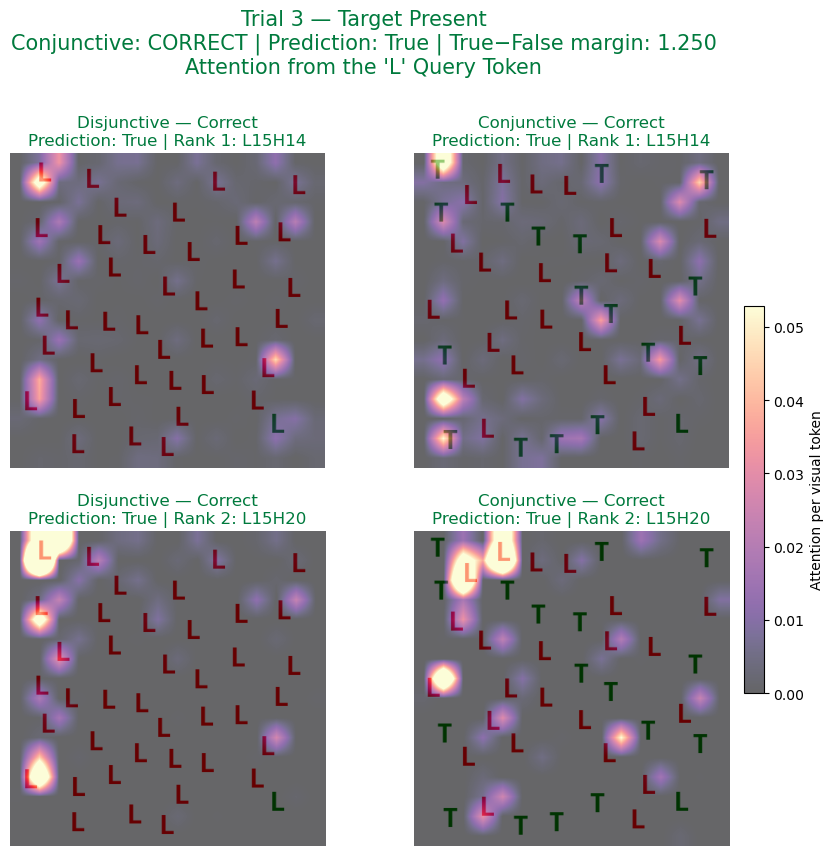

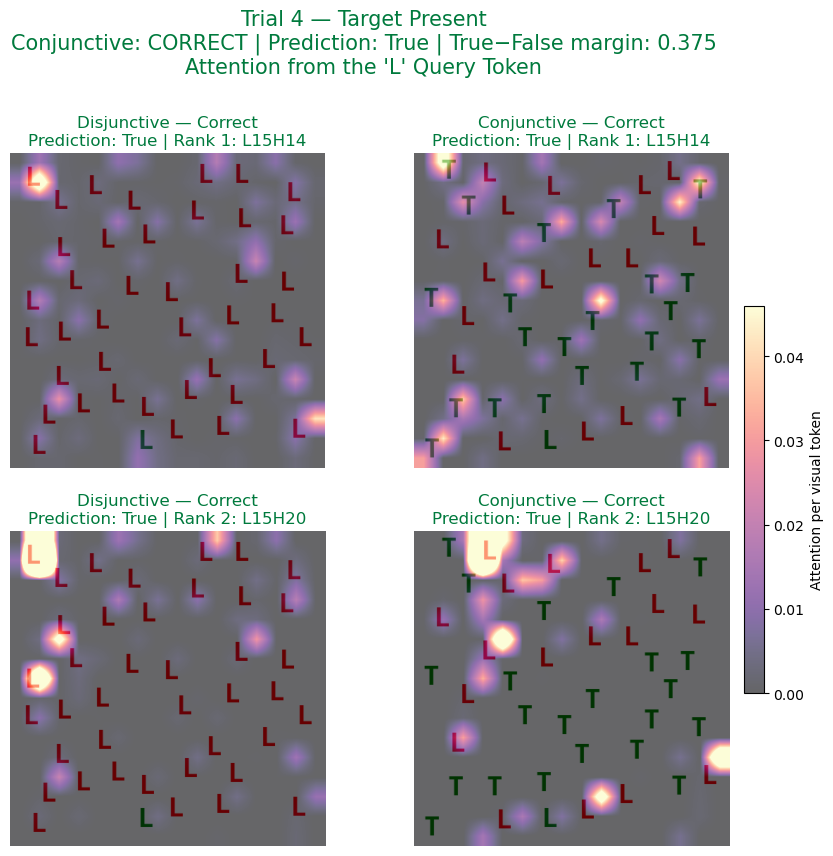

In [8]:
# ==========================================================
# CREATE ONE FIGURE PER MATCHED TRIAL
# ==========================================================

conditions = [
    "disjunctive",
    "conjunctive",
]

for trial in available_trials:

    trial_df = df[
        (df["trial"] == trial)
        & (df["target_present"] == TARGET_PRESENT)
        & (df["token_group"] == "vision")
    ].copy()

    # ------------------------------------------------------
    # BEHAVIORAL RESULTS
    # ------------------------------------------------------

    condition_behavior = (
        trial_df[
            [
                "condition",
                "prediction",
                "correct",
                "margin",
            ]
        ]
        .drop_duplicates("condition")
        .set_index("condition")
    )

    conjunctive_correct = bool(
        condition_behavior.loc[
            "conjunctive",
            "correct",
        ]
    )

    conjunctive_prediction = bool(
        condition_behavior.loc[
            "conjunctive",
            "prediction",
        ]
    )

    conjunctive_margin = float(
        condition_behavior.loc[
            "conjunctive",
            "margin",
        ]
    )

    conjunctive_status = (
        "CORRECT"
        if conjunctive_correct
        else "INCORRECT"
    )

    conjunctive_prediction_label = (
        "True"
        if conjunctive_prediction
        else "False"
    )

    # ------------------------------------------------------
    # SHARED ATTENTION SCALE
    # ------------------------------------------------------

    vmax = trial_df["attention"].quantile(0.995)

    if not np.isfinite(vmax) or vmax <= 0:
        vmax = trial_df["attention"].max()

    # ------------------------------------------------------
    # FIGURE
    # ------------------------------------------------------

    fig, axes = plt.subplots(
        len(heads_to_plot),
        2,
        figsize=(
            10,
            4.5 * len(heads_to_plot),
        ),
        squeeze=False,
    )

    last_overlay = None

    for row_index, head_row in enumerate(
        heads_to_plot.itertuples(index=False)
    ):
        layer = int(head_row.layer)
        head = int(head_row.head)
        rank = int(head_row.rank)

        for column_index, condition in enumerate(
            conditions
        ):
            ax = axes[
                row_index,
                column_index,
            ]

            part = (
                trial_df[
                    (trial_df["layer"] == layer)
                    & (trial_df["head"] == head)
                    & (
                        trial_df["condition"]
                        == condition
                    )
                ]
                .sort_values(
                    ["visual_row", "visual_col"]
                )
            )

            if part.empty:
                ax.axis("off")
                continue

            image_path = part[
                "image_path"
            ].iloc[0]

            condition_correct = bool(
                part["correct"].iloc[0]
            )

            condition_prediction = bool(
                part["prediction"].iloc[0]
            )

            condition_status = (
                "Correct"
                if condition_correct
                else "Incorrect"
            )

            condition_prediction_label = (
                "True"
                if condition_prediction
                else "False"
            )

            title_color = (
                "#007A3D"
                if condition_correct
                else "#C62828"
            )

            last_overlay = make_attention_overlay(
                ax=ax,
                image_path=image_path,
                visual_attention=part[
                    "attention"
                ].to_numpy(),
                visual_rows=part[
                    "visual_row"
                ].to_numpy(),
                visual_cols=part[
                    "visual_col"
                ].to_numpy(),
                title=(
                    f"{condition.title()} — "
                    f"{condition_status}\n"
                    f"Prediction: "
                    f"{condition_prediction_label} | "
                    f"Rank {rank}: L{layer}H{head}"
                ),
                vmax=vmax,
            )

            ax.title.set_color(
                title_color
            )

    if last_overlay is not None:
        fig.colorbar(
            last_overlay,
            ax=axes,
            fraction=0.025,
            pad=0.02,
            label="Attention per visual token",
        )

    target_label = (
        "Present"
        if TARGET_PRESENT
        else "Absent"
    )

    fig.suptitle(
        (
            f"Trial {trial} — Target {target_label}\n"
            f"Conjunctive: {conjunctive_status} | "
            f"Prediction: {conjunctive_prediction_label} | "
            f"True−False margin: {conjunctive_margin:.3f}\n"
            "Attention from the 'L' Query Token"
        ),
        fontsize=15,
        y=1.04,
        color=(
            "#007A3D"
            if conjunctive_correct
            else "#C62828"
        ),
    )

    plt.show()

In [13]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# LOAD
# ==========================================================

RESULTS_DIR = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_attention_maps_top8_offset_-9"
)

df = pd.read_csv(
    os.path.join(
        RESULTS_DIR,
        "token_attention.csv",
    )
)

selected_heads = (
    pd.read_csv(
        os.path.join(
            RESULTS_DIR,
            "selected_heads.csv",
        )
    )
    .sort_values("rank")
)

if df["target_present"].dtype == object:
    df["target_present"] = (
        df["target_present"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
        })
    )

vision_df = df[
    df["token_group"] == "vision"
].copy()

In [14]:
# ==========================================================
# MAP TARGET LOCATION TO THE VISUAL-TOKEN GRID
# ==========================================================

def load_target_plot_position(image_path):
    """
    Load the target's position_plot from the image's matching JSON file.
    Returns (x_plot, y_plot), or None if no target exists.
    """

    json_path = os.path.splitext(image_path)[0] + ".json"

    with open(json_path, "r") as handle:
        metadata = json.load(handle)

    target_objects = [
        obj
        for obj in metadata.get("objects", [])
        if str(obj.get("role", "")).lower() == "target"
    ]

    if not target_objects:
        return None

    position = target_objects[0].get("position_plot")

    if position is None or len(position) != 2:
        return None

    return float(position[0]), float(position[1])


def target_visual_token(image_path, grid_height, grid_width):
    """
    Convert the dataset's 9x9 position_plot coordinates to a visual-token
    grid coordinate.

    The dataset uses positions centered at approximately:
        0.5, 1.5, ..., 8.5
    """

    position = load_target_plot_position(image_path)

    if position is None:
        return None

    x_plot, y_plot = position

    x_normalized = (x_plot - 0.5) / 9.0
    y_normalized = (y_plot - 0.5) / 9.0

    target_column = int(
        np.clip(
            np.floor(x_normalized * grid_width),
            0,
            grid_width - 1,
        )
    )

    # If position_plot uses a bottom-left plotting origin, flip the y-axis.
    target_row = int(
        np.clip(
            np.floor((1.0 - y_normalized) * grid_height),
            0,
            grid_height - 1,
        )
    )

    return target_row, target_column

# ==========================================================
# CALCULATE TARGET-REGION ATTENTION PER EXAMPLE AND HEAD
# ==========================================================

target_rows = []

group_columns = [
    "condition",
    "trial",
    "target_present",
    "image_path",
    "layer",
    "head",
    "rank",
]

for group_key, part in vision_df.groupby(
    group_columns,
    sort=False,
):
    (
        condition,
        trial,
        target_present,
        image_path,
        layer,
        head,
        rank,
    ) = group_key

    grid_height = int(part["visual_row"].max()) + 1
    grid_width = int(part["visual_col"].max()) + 1

    target_location = target_visual_token(
        image_path=image_path,
        grid_height=grid_height,
        grid_width=grid_width,
    )

    if target_location is None:
        continue

    target_row, target_column = target_location

    # Use a 3x3 neighborhood around the target center.
    in_target_window = (
        part["visual_row"].between(
            max(0, target_row - 1),
            min(grid_height - 1, target_row + 1),
        )
        & part["visual_col"].between(
            max(0, target_column - 1),
            min(grid_width - 1, target_column + 1),
        )
    )

    target_attention_mass = part.loc[
        in_target_window,
        "attention",
    ].sum()

    center_attention = part.loc[
        (part["visual_row"] == target_row)
        & (part["visual_col"] == target_column),
        "attention",
    ].sum()

    total_vision_mass = part[
        "attention"
    ].sum()

    target_fraction_of_vision = (
        target_attention_mass / total_vision_mass
        if total_vision_mass > 0
        else np.nan
    )

    target_rows.append({
        "condition": condition,
        "trial": trial,
        "target_present": target_present,
        "image_path": image_path,
        "layer": int(layer),
        "head": int(head),
        "rank": int(rank),
        "grid_height": grid_height,
        "grid_width": grid_width,
        "target_visual_row": target_row,
        "target_visual_col": target_column,
        "target_center_attention": center_attention,
        "target_window_attention": target_attention_mass,
        "total_vision_attention": total_vision_mass,
        "target_fraction_of_vision": target_fraction_of_vision,
    })

target_df = pd.DataFrame(target_rows)

print("Target-region rows:", len(target_df))
display(target_df.head())

Target-region rows: 800


,condition,trial,target_present,image_path,layer,head,rank,grid_height,grid_width,target_visual_row,target_visual_col,target_center_attention,target_window_attention,total_vision_attention,target_fraction_of_vision
0,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,14,1,16,16,14,9,0.002228,0.037800,0.631726,0.059836
1,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,20,2,16,16,14,9,0.000017,0.007227,0.981699,0.007362
2,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,4,6,16,16,14,9,0.000564,0.016350,0.202109,0.080899
3,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,15,7,16,16,14,9,0.018319,0.067468,0.913486,0.073858
4,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,21,8,16,16,14,9,0.000002,0.000485,0.005175,0.093656


Target-region rows: 800


,condition,trial,target_present,image_path,layer,head,rank,grid_height,grid_width,target_visual_row,target_visual_col,target_center_attention,target_window_attention,total_vision_attention,target_fraction_of_vision
0,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,14,1,16,16,14,9,0.002228,0.037800,0.631726,0.059836
1,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,20,2,16,16,14,9,0.000017,0.007227,0.981699,0.007362
2,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,4,6,16,16,14,9,0.000564,0.016350,0.202109,0.080899
3,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,15,7,16,16,14,9,0.018319,0.067468,0.913486,0.073858
4,disjunctive,0,True,/oscar/data/epavlick/aparasel/Binding-Problem-...,15,21,8,16,16,14,9,0.000002,0.000485,0.005175,0.093656


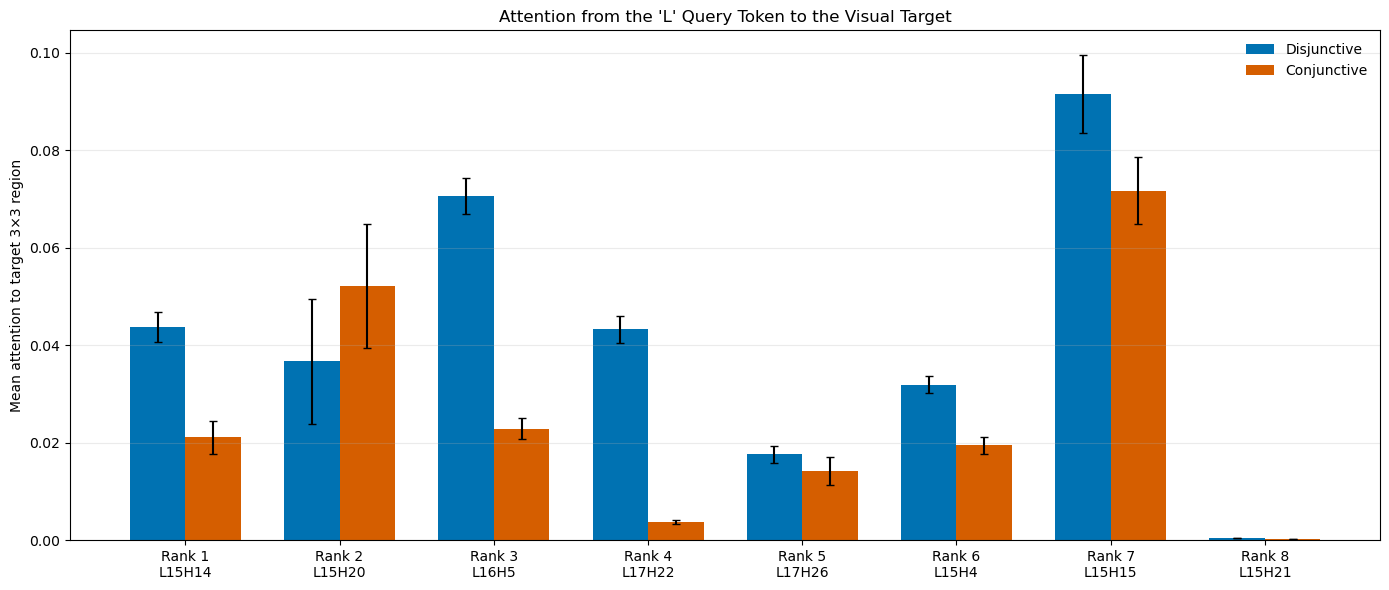

In [17]:
# ==========================================================
# CALCULATE TARGET-REGION ATTENTION PER EXAMPLE AND HEAD
# ==========================================================

target_rows = []

group_columns = [
    "condition",
    "trial",
    "target_present",
    "image_path",
    "layer",
    "head",
    "rank",
]

for group_key, part in vision_df.groupby(
    group_columns,
    sort=False,
):
    (
        condition,
        trial,
        target_present,
        image_path,
        layer,
        head,
        rank,
    ) = group_key

    grid_height = int(part["visual_row"].max()) + 1
    grid_width = int(part["visual_col"].max()) + 1

    target_location = target_visual_token(
        image_path=image_path,
        grid_height=grid_height,
        grid_width=grid_width,
    )

    if target_location is None:
        continue

    target_row, target_column = target_location

    # Use a 3x3 neighborhood around the target center.
    in_target_window = (
        part["visual_row"].between(
            max(0, target_row - 1),
            min(grid_height - 1, target_row + 1),
        )
        & part["visual_col"].between(
            max(0, target_column - 1),
            min(grid_width - 1, target_column + 1),
        )
    )

    target_attention_mass = part.loc[
        in_target_window,
        "attention",
    ].sum()

    center_attention = part.loc[
        (part["visual_row"] == target_row)
        & (part["visual_col"] == target_column),
        "attention",
    ].sum()

    total_vision_mass = part[
        "attention"
    ].sum()

    target_fraction_of_vision = (
        target_attention_mass / total_vision_mass
        if total_vision_mass > 0
        else np.nan
    )

    target_rows.append({
        "condition": condition,
        "trial": trial,
        "target_present": target_present,
        "image_path": image_path,
        "layer": int(layer),
        "head": int(head),
        "rank": int(rank),
        "grid_height": grid_height,
        "grid_width": grid_width,
        "target_visual_row": target_row,
        "target_visual_col": target_column,
        "target_center_attention": center_attention,
        "target_window_attention": target_attention_mass,
        "total_vision_attention": total_vision_mass,
        "target_fraction_of_vision": target_fraction_of_vision,
    })

target_df = pd.DataFrame(target_rows)

print("Target-region rows:", len(target_df))
display(target_df.head())
# ==========================================================
# SUMMARIZE DISJUNCTIVE VS CONJUNCTIVE
# ==========================================================

present_target_df = target_df[
    target_df["target_present"] == True
].copy()


def sem(values):
    values = pd.to_numeric(
        values,
        errors="coerce",
    ).dropna()

    if len(values) <= 1:
        return 0.0

    return values.std(ddof=1) / np.sqrt(len(values))


summary = (
    present_target_df.groupby(
        [
            "condition",
            "layer",
            "head",
            "rank",
        ],
        as_index=False,
    )
    .agg(
        n_trials=("trial", "nunique"),
        mean_target_attention=(
            "target_window_attention",
            "mean",
        ),
        sem_target_attention=(
            "target_window_attention",
            sem,
        ),
        mean_target_fraction_of_vision=(
            "target_fraction_of_vision",
            "mean",
        ),
        sem_target_fraction_of_vision=(
            "target_fraction_of_vision",
            sem,
        ),
        mean_total_vision_attention=(
            "total_vision_attention",
            "mean",
        ),
    )
)

# ==========================================================
# PLOT ABSOLUTE TARGET ATTENTION
# ==========================================================

head_order = [
    (
        int(row.layer),
        int(row.head),
        int(row.rank),
    )
    for row in selected_heads.itertuples(index=False)
]

x = np.arange(len(head_order))
width = 0.36

fig, ax = plt.subplots(
    figsize=(14, 6),
)

for index, condition in enumerate(
    ["disjunctive", "conjunctive"]
):
    condition_df = (
        summary[
            summary["condition"] == condition
        ]
        .set_index(["layer", "head"])
    )

    means = []
    errors = []

    for layer, head, rank in head_order:
        row = condition_df.loc[
            (layer, head)
        ]

        means.append(
            row["mean_target_attention"]
        )

        errors.append(
            row["sem_target_attention"]
        )

    ax.bar(
        x + (index - 0.5) * width,
        means,
        width,
        yerr=errors,
        capsize=3,
        label=condition.title(),
        color=(
            "#0072B2"
            if condition == "disjunctive"
            else "#D55E00"
        ),
    )

ax.set_xticks(
    x,
    [
        f"Rank {rank}\nL{layer}H{head}"
        for layer, head, rank in head_order
    ],
)

ax.set_ylabel(
    "Mean attention to target 3×3 region"
)

ax.set_title(
    "Attention from the 'L' Query Token to the Visual Target"
)

ax.legend(
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()
plt.show()

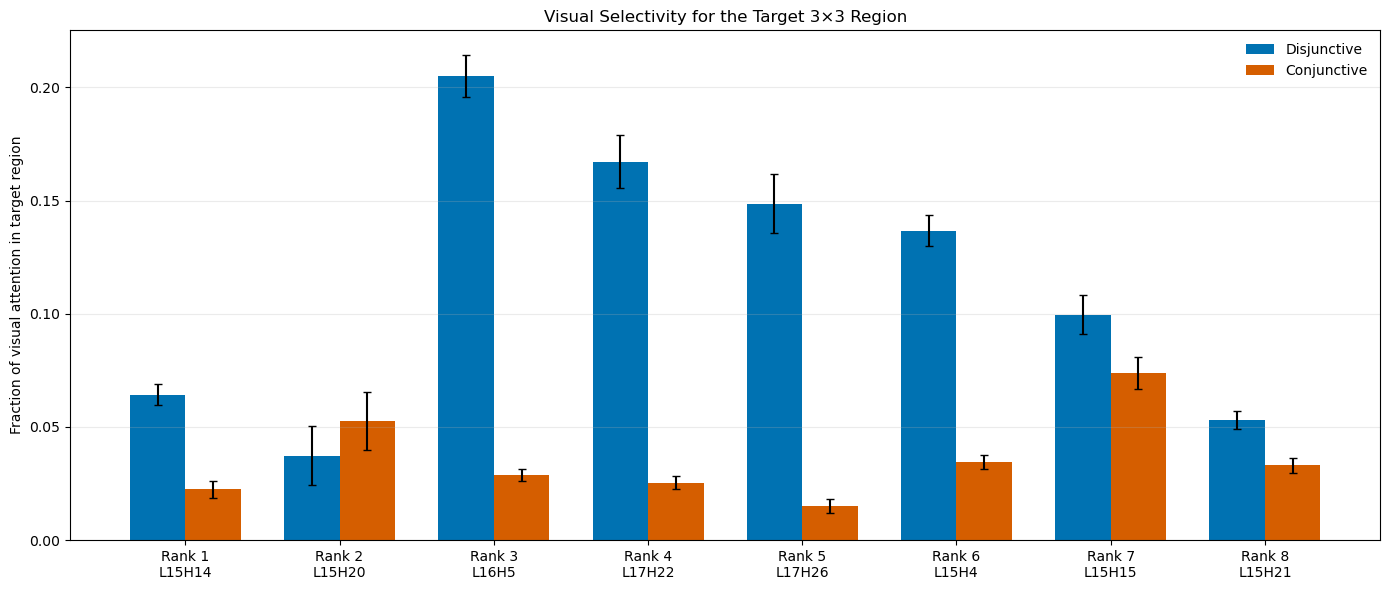

In [18]:
# ==========================================================
# PLOT TARGET FRACTION OF VISION ATTENTION
# ==========================================================

fig, ax = plt.subplots(
    figsize=(14, 6),
)

for index, condition in enumerate(
    ["disjunctive", "conjunctive"]
):
    condition_df = (
        summary[
            summary["condition"] == condition
        ]
        .set_index(["layer", "head"])
    )

    means = []
    errors = []

    for layer, head, rank in head_order:
        row = condition_df.loc[
            (layer, head)
        ]

        means.append(
            row[
                "mean_target_fraction_of_vision"
            ]
        )

        errors.append(
            row[
                "sem_target_fraction_of_vision"
            ]
        )

    ax.bar(
        x + (index - 0.5) * width,
        means,
        width,
        yerr=errors,
        capsize=3,
        label=condition.title(),
        color=(
            "#0072B2"
            if condition == "disjunctive"
            else "#D55E00"
        ),
    )

ax.set_xticks(
    x,
    [
        f"Rank {rank}\nL{layer}H{head}"
        for layer, head, rank in head_order
    ],
)

ax.set_ylabel(
    "Fraction of visual attention in target region"
)

ax.set_title(
    "Visual Selectivity for the Target 3×3 Region"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

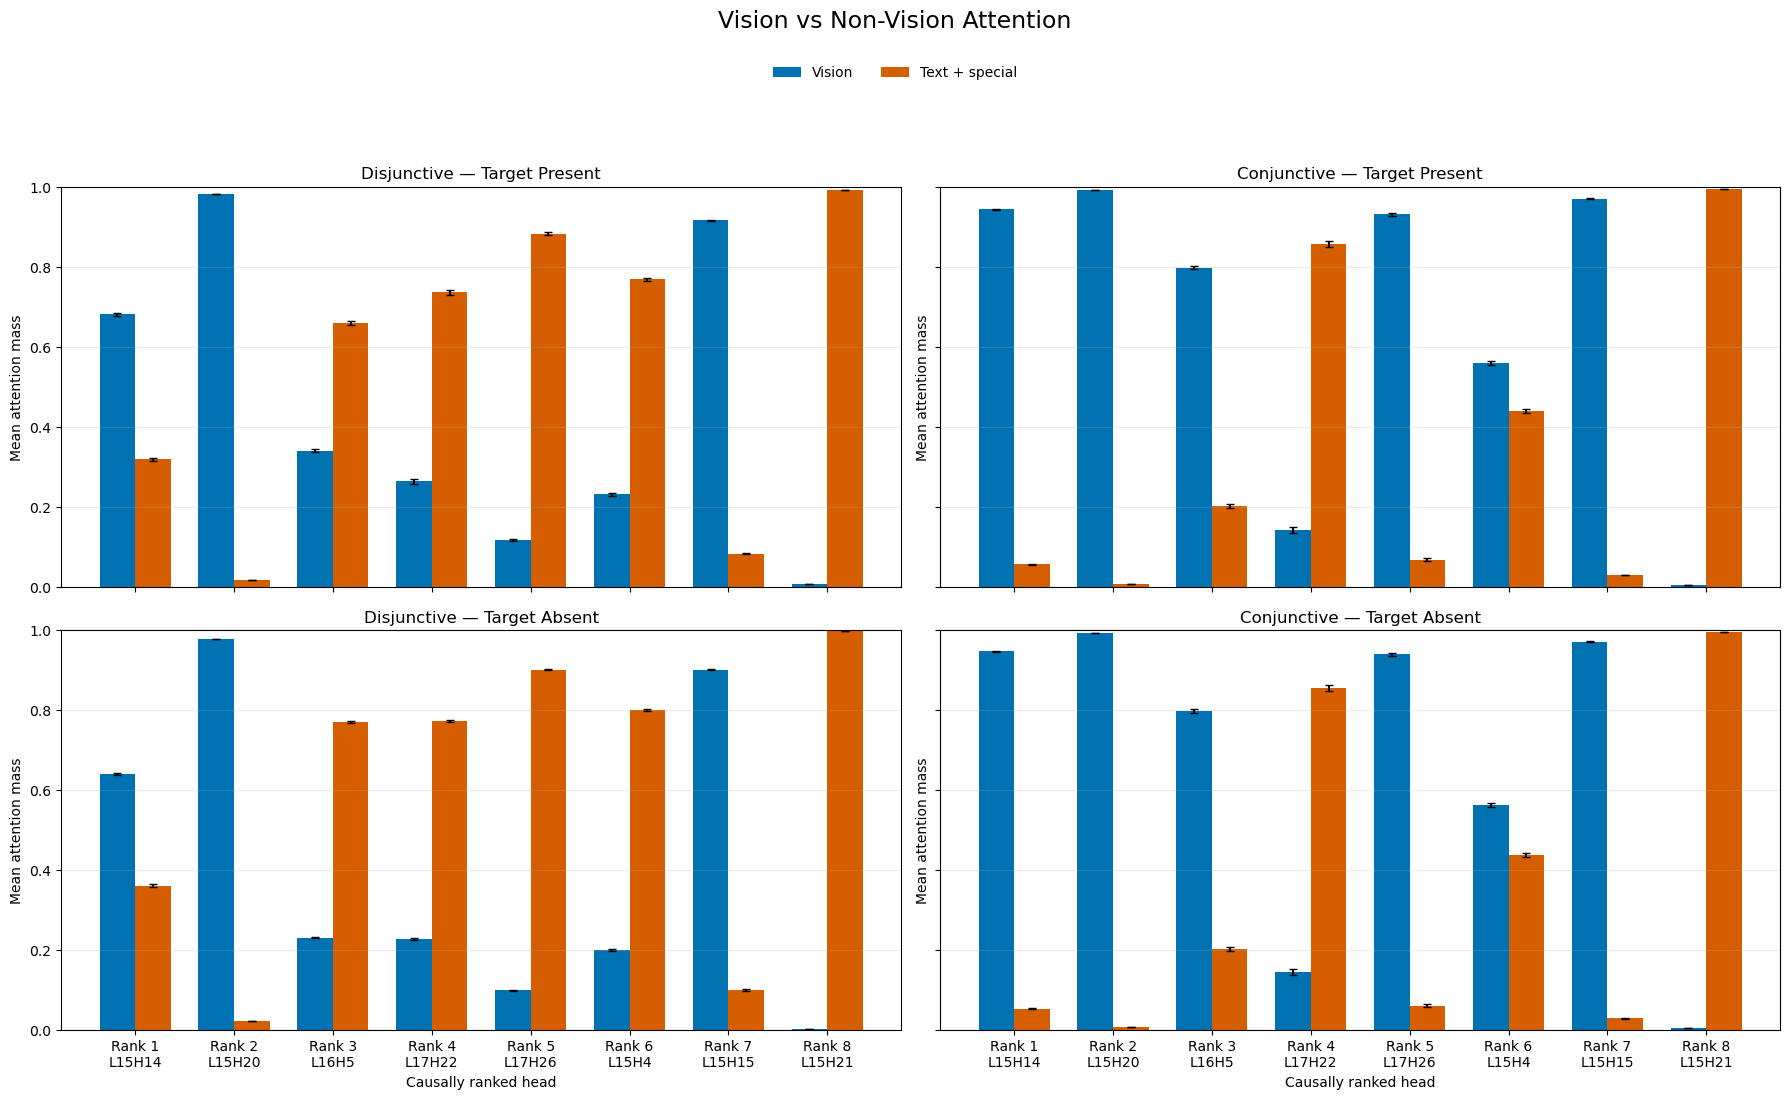

In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# LOAD
# ==========================================================

RESULTS_DIR = (
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_attention_maps_top8_offset_-9"
)

df = pd.read_csv(
    os.path.join(RESULTS_DIR, "token_attention.csv")
)

heads = (
    pd.read_csv(os.path.join(RESULTS_DIR, "selected_heads.csv"))
    .sort_values("rank")
)

if df["target_present"].dtype == object:
    df["target_present"] = (
        df["target_present"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({
            "true": True,
            "false": False,
            "1": True,
            "0": False,
        })
    )

# ==========================================================
# SUM ATTENTION MASS PER TRIAL
# ==========================================================

df["attention_type"] = np.where(
    df["token_group"] == "vision",
    "Vision",
    "Text + special",
)

trial_mass = (
    df.groupby(
        [
            "condition",
            "target_present",
            "trial",
            "layer",
            "head",
            "rank",
            "attention_type",
        ],
        as_index=False,
    )
    .agg(attention_mass=("attention", "sum"))
)


def sem(values):
    return (
        values.std(ddof=1) / np.sqrt(len(values))
        if len(values) > 1
        else 0.0
    )


summary = (
    trial_mass.groupby(
        [
            "condition",
            "target_present",
            "layer",
            "head",
            "rank",
            "attention_type",
        ],
        as_index=False,
    )
    .agg(
        mean_mass=("attention_mass", "mean"),
        sem_mass=("attention_mass", sem),
    )
)

# ==========================================================
# PLOT
# ==========================================================

head_order = [
    (int(r.layer), int(r.head), int(r.rank))
    for r in heads.itertuples(index=False)
]

x = np.arange(len(head_order))
width = 0.36

colors = {
    "Vision": "#0072B2",
    "Text + special": "#D55E00",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 11),
    sharex=True,
    sharey=True,
)

# Rows: target present / absent
# Columns: disjunctive / conjunctive
for row_index, target_present in enumerate([True, False]):
    for column_index, condition in enumerate(
        ["disjunctive", "conjunctive"]
    ):
        ax = axes[row_index, column_index]

        panel_df = summary[
            (summary["target_present"] == target_present)
            & (summary["condition"] == condition)
        ]

        for index, attention_type in enumerate(
            ["Vision", "Text + special"]
        ):
            values = (
                panel_df[
                    panel_df["attention_type"] == attention_type
                ]
                .set_index(["layer", "head"])
            )

            means = [
                values.loc[(layer, head), "mean_mass"]
                for layer, head, _ in head_order
            ]

            errors = [
                values.loc[(layer, head), "sem_mass"]
                for layer, head, _ in head_order
            ]

            ax.bar(
                x + (index - 0.5) * width,
                means,
                width,
                yerr=errors,
                capsize=3,
                color=colors[attention_type],
                label=attention_type,
            )

        target_label = (
            "Target Present"
            if target_present
            else "Target Absent"
        )

        ax.set_title(
            f"{condition.title()} — {target_label}"
        )

        ax.set_ylabel("Mean attention mass")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.25)

        ax.set_xticks(
            x,
            [
                f"Rank {rank}\nL{layer}H{head}"
                for layer, head, rank in head_order
            ],
        )

        ax.tick_params(
            axis="x",
            labelrotation=0,
        )

for ax in axes[-1]:
    ax.set_xlabel("Causally ranked head")

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=2,
    frameon=False,
)

fig.suptitle(
    "Vision vs Non-Vision Attention",
    fontsize=17,
    y=0.995,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.90]
)

plt.show()

# Neccesity of heads

Successful rows: 17600

Intervention groups:
intervention_group
random    16000
ranked     1600
Name: count, dtype: int64

Head counts:
[1, 2, 4, 8]

Random repetitions:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


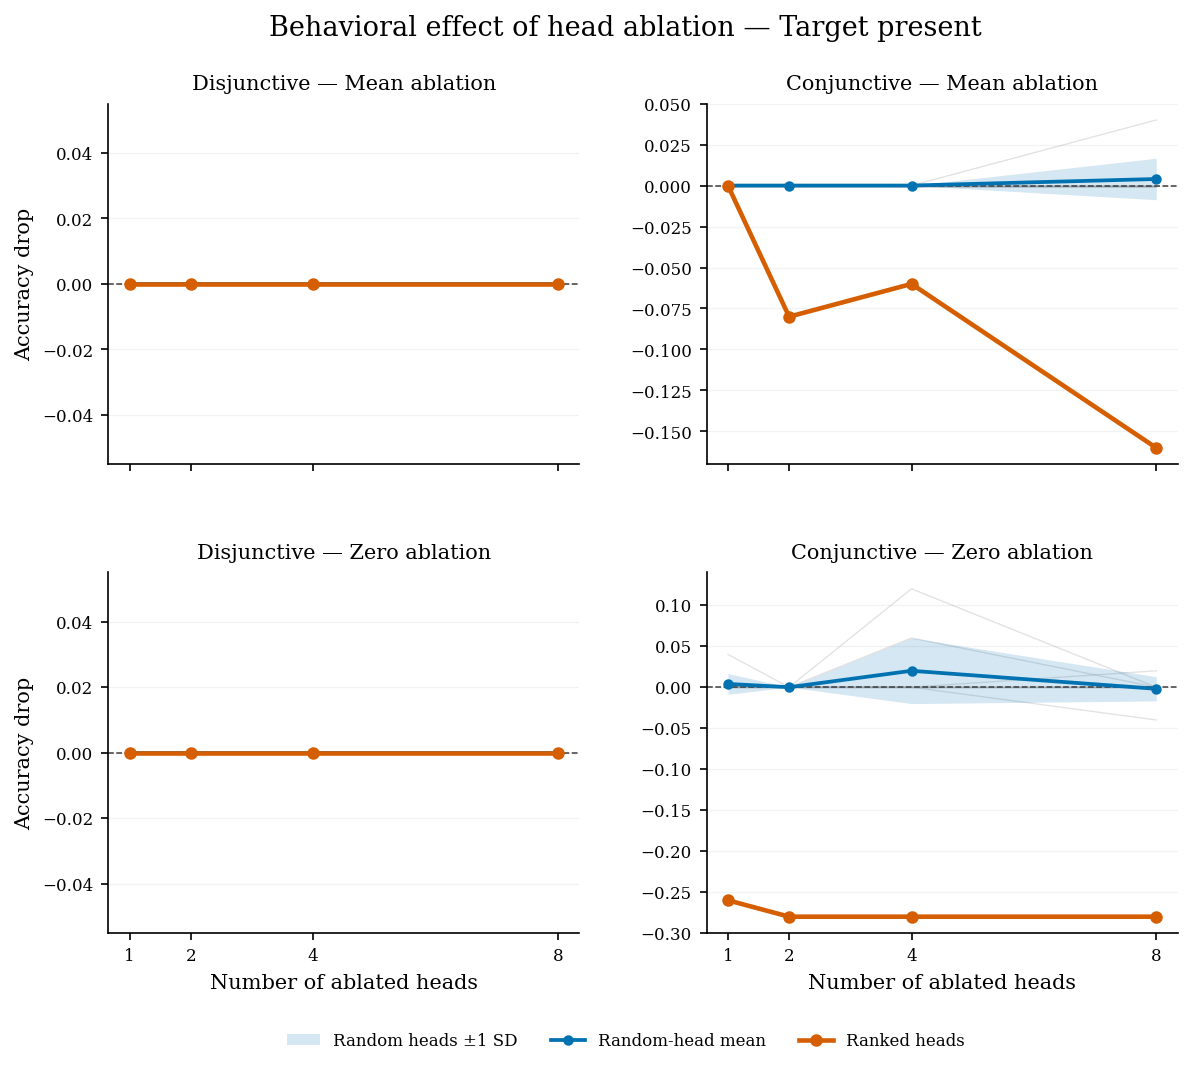

Saved: ../Results/top_heads_ablation_figures_offset_-9/accuracy_drop_ranked_vs_random_target_present.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/accuracy_drop_ranked_vs_random_target_present.png


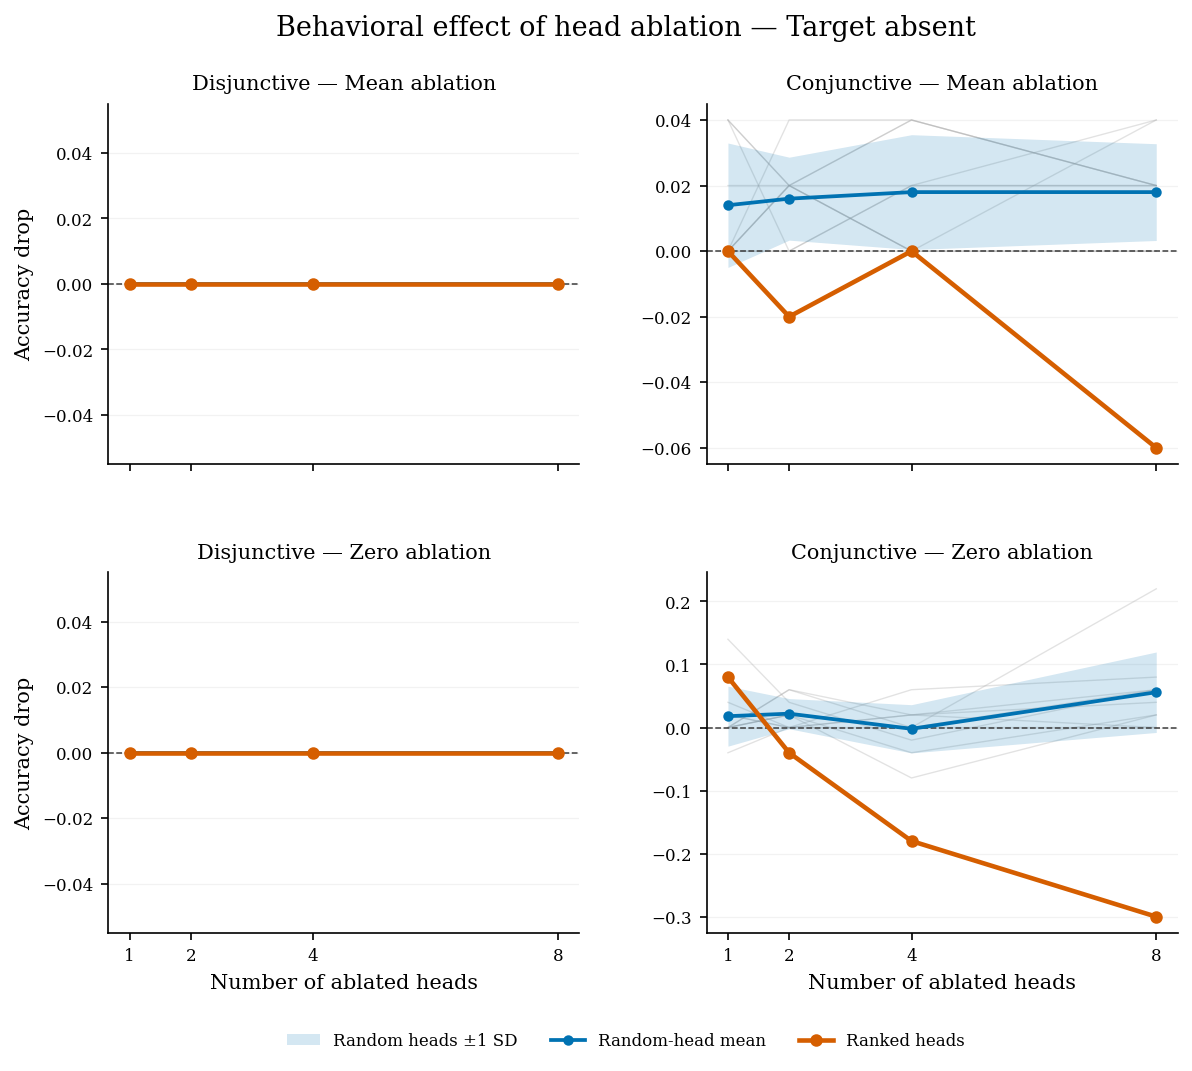

Saved: ../Results/top_heads_ablation_figures_offset_-9/accuracy_drop_ranked_vs_random_target_absent.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/accuracy_drop_ranked_vs_random_target_absent.png


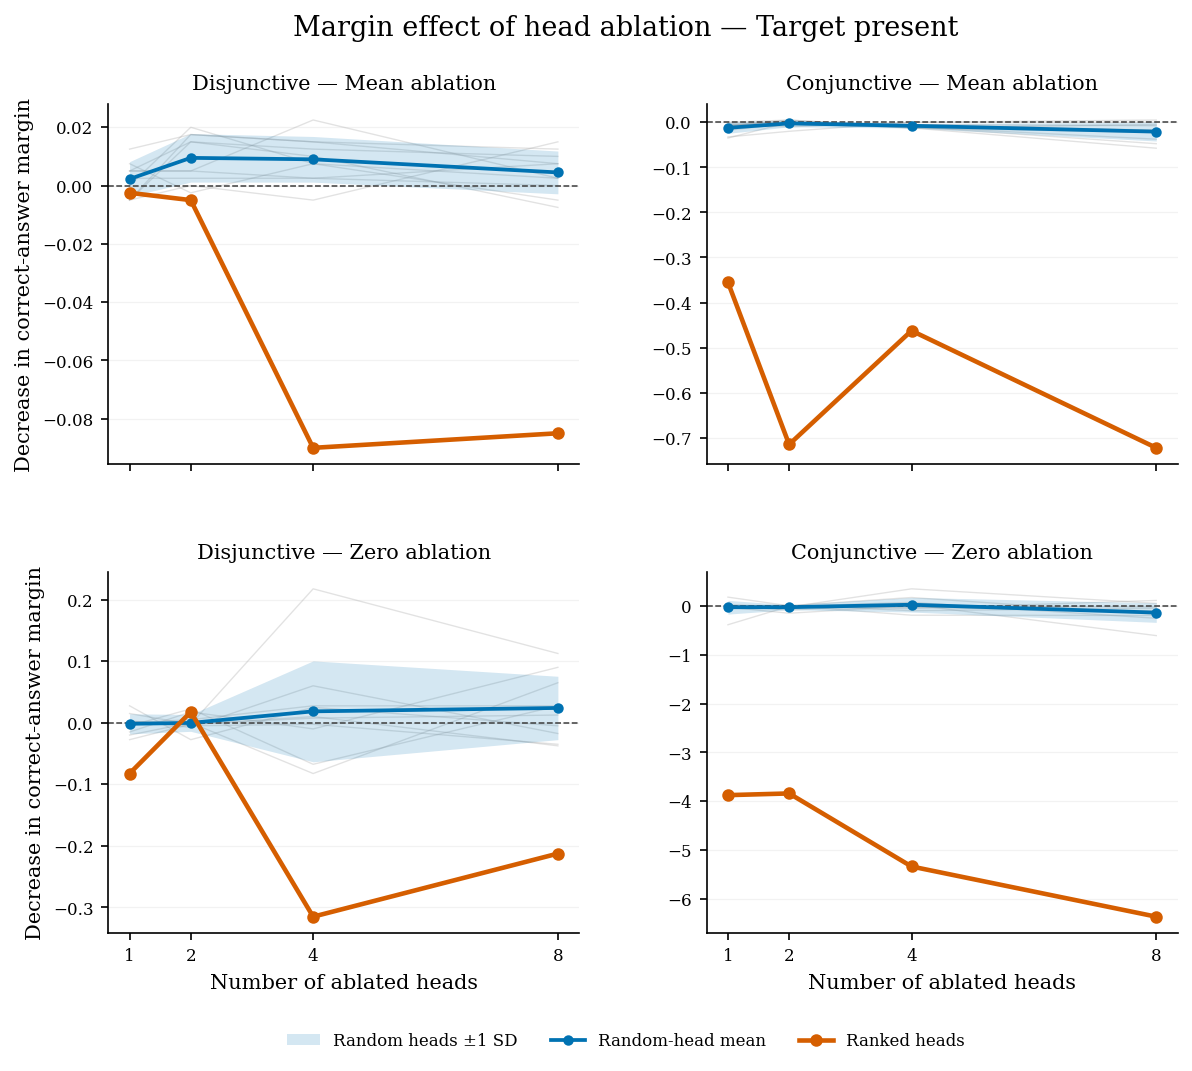

Saved: ../Results/top_heads_ablation_figures_offset_-9/margin_decrease_ranked_vs_random_target_present.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/margin_decrease_ranked_vs_random_target_present.png


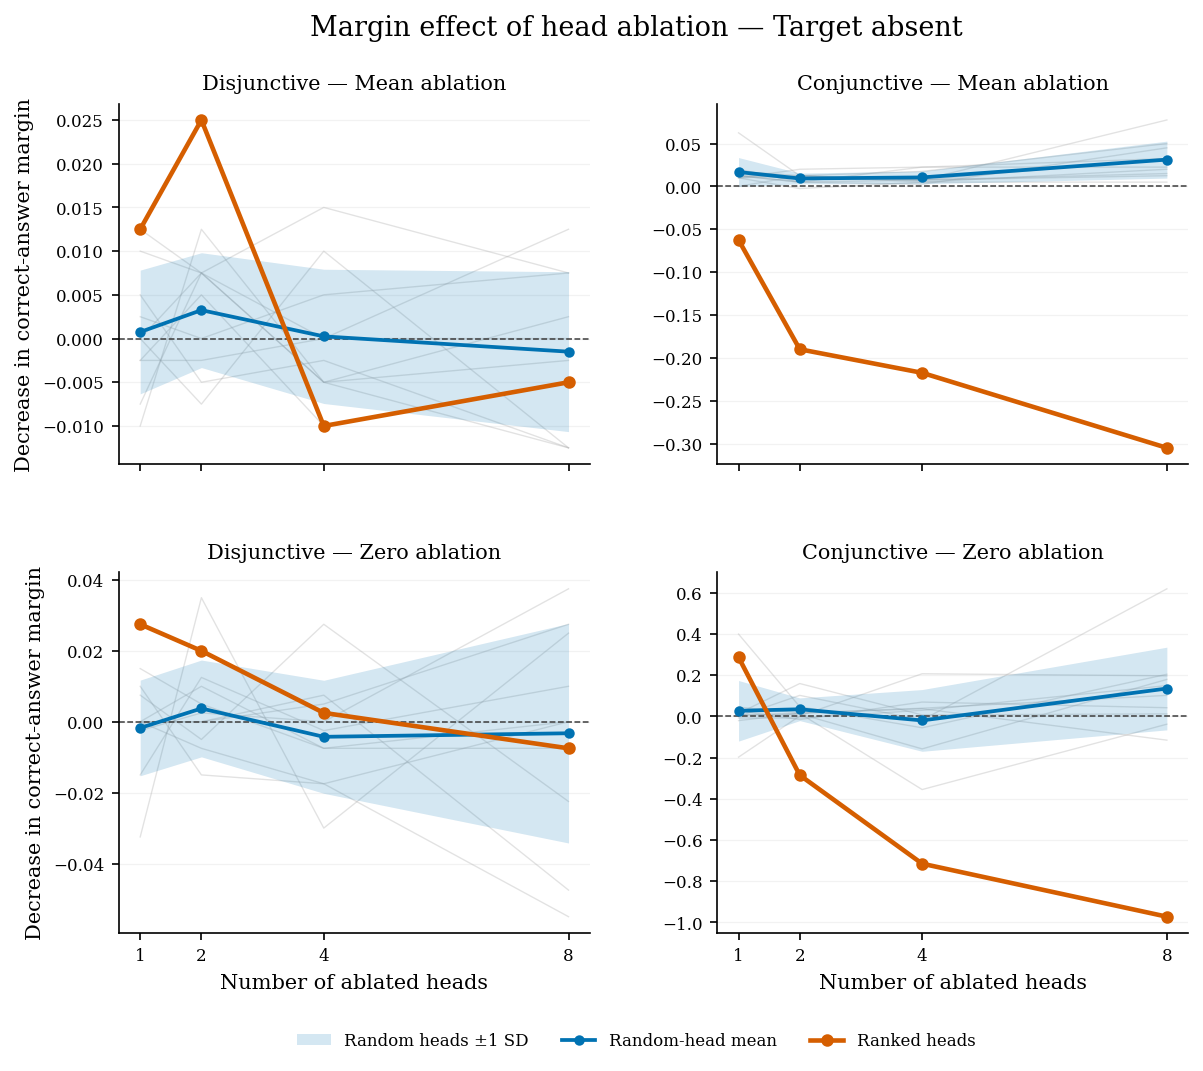

Saved: ../Results/top_heads_ablation_figures_offset_-9/margin_decrease_ranked_vs_random_target_absent.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/margin_decrease_ranked_vs_random_target_absent.png


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "../Results/top_heads_ablation_both_conditions_offset_-9.csv"
)

OUTPUT_DIR = Path(
    "../Results/top_heads_ablation_figures_offset_-9"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================================
# LOAD AND CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "baseline_correct",
    "ablated_correct",
]:
    df[column] = parse_bool(df[column])

for column in [
    "head_count",
    "random_repeat",
    "baseline_margin",
    "ablated_margin",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

# Positive values consistently mean that ablation hurt performance.
df["accuracy_drop"] = (
    df["baseline_correct"].astype(float)
    - df["ablated_correct"].astype(float)
)

df["margin_decrease"] = (
    df["baseline_margin"]
    - df["ablated_margin"]
)

print("Successful rows:", len(df))
print("\nIntervention groups:")
print(df["intervention_group"].value_counts())

print("\nHead counts:")
print(sorted(df["head_count"].dropna().unique()))

print("\nRandom repetitions:")
print(
    sorted(
        df.loc[
            df["intervention_group"] == "random",
            "random_repeat",
        ]
        .dropna()
        .unique()
    )
)


# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

RANKED_COLOR = "#D55E00"
RANDOM_COLOR = "#0072B2"


# ==========================================================
# AGGREGATION
# ==========================================================

def aggregate_metric(data, metric):
    """
    First average across trials within each head set.

    Then calculate the mean and standard deviation across the
    ten independently sampled random head sets.
    """

    per_set = (
        data.groupby(
            [
                "target_present",
                "condition",
                "ablation_mode",
                "head_count",
                "intervention_group",
                "random_repeat",
            ],
            as_index=False,
        )
        .agg(
            effect=(metric, "mean"),
            n_trials=(metric, "count"),
        )
    )

    ranked = (
        per_set[
            per_set["intervention_group"] == "ranked"
        ]
        .copy()
    )

    random_draws = (
        per_set[
            per_set["intervention_group"] == "random"
        ]
        .copy()
    )

    random_summary = (
        random_draws.groupby(
            [
                "target_present",
                "condition",
                "ablation_mode",
                "head_count",
            ],
            as_index=False,
        )
        .agg(
            random_mean=("effect", "mean"),
            random_std=("effect", "std"),
            n_random_sets=("effect", "count"),
        )
    )

    return ranked, random_draws, random_summary


def select_panel(
    data,
    target_present,
    condition,
    ablation_mode,
):
    return (
        data[
            (data["target_present"] == target_present)
            & (data["condition"] == condition)
            & (data["ablation_mode"] == ablation_mode)
        ]
        .sort_values("head_count")
    )


# ==========================================================
# PLOTTING FUNCTION
# ==========================================================

def plot_metric(
    data,
    metric,
    ylabel,
    figure_title,
    filename_prefix,
    show_individual_random_draws=True,
):
    ranked, random_draws, random_summary = (
        aggregate_metric(data, metric)
    )

    conditions = [
        "disjunctive",
        "conjunctive",
    ]

    ablation_modes = [
        "mean",
        "zero",
    ]

    for target_present in [True, False]:

        fig, axes = plt.subplots(
            2,
            2,
            figsize=(9.2, 7.0),
            sharex=True,
            gridspec_kw={
                "hspace": 0.30,
                "wspace": 0.27,
            },
        )

        legend_handles = []
        legend_labels = []

        for row_index, ablation_mode in enumerate(
            ablation_modes
        ):
            for column_index, condition in enumerate(
                conditions
            ):
                ax = axes[row_index, column_index]

                ranked_panel = select_panel(
                    ranked,
                    target_present,
                    condition,
                    ablation_mode,
                )

                random_panel = select_panel(
                    random_summary,
                    target_present,
                    condition,
                    ablation_mode,
                )

                random_draw_panel = select_panel(
                    random_draws,
                    target_present,
                    condition,
                    ablation_mode,
                )

                # ------------------------------------------
                # INDIVIDUAL RANDOM-HEAD SETS
                # ------------------------------------------

                if (
                    show_individual_random_draws
                    and not random_draw_panel.empty
                ):
                    for _, repeat_df in (
                        random_draw_panel.groupby(
                            "random_repeat"
                        )
                    ):
                        repeat_df = repeat_df.sort_values(
                            "head_count"
                        )

                        ax.plot(
                            repeat_df["head_count"],
                            repeat_df["effect"],
                            color="0.65",
                            linewidth=0.65,
                            alpha=0.32,
                            zorder=1,
                        )

                # ------------------------------------------
                # RANDOM-HEAD MEAN AND STANDARD DEVIATION
                # ------------------------------------------

                if not random_panel.empty:
                    x = random_panel[
                        "head_count"
                    ].to_numpy(dtype=float)

                    random_mean = random_panel[
                        "random_mean"
                    ].to_numpy(dtype=float)

                    random_std = (
                        random_panel["random_std"]
                        .fillna(0)
                        .to_numpy(dtype=float)
                    )

                    ax.fill_between(
                        x,
                        random_mean - random_std,
                        random_mean + random_std,
                        color=RANDOM_COLOR,
                        alpha=0.17,
                        linewidth=0,
                        label="Random heads ±1 SD",
                        zorder=2,
                    )

                    ax.plot(
                        x,
                        random_mean,
                        color=RANDOM_COLOR,
                        marker="o",
                        markersize=4,
                        linewidth=1.8,
                        label="Random-head mean",
                        zorder=3,
                    )

                # ------------------------------------------
                # RANKED HEADS
                # ------------------------------------------

                if not ranked_panel.empty:
                    ax.plot(
                        ranked_panel["head_count"],
                        ranked_panel["effect"],
                        color=RANKED_COLOR,
                        marker="o",
                        markersize=5,
                        linewidth=2.2,
                        label="Ranked heads",
                        zorder=4,
                    )

                ax.axhline(
                    0,
                    color="0.25",
                    linewidth=0.75,
                    linestyle="--",
                )

                ax.set_title(
                    f"{condition.title()} — "
                    f"{ablation_mode.title()} ablation",
                    pad=7,
                )

                ax.set_xticks(
                    sorted(
                        data["head_count"]
                        .dropna()
                        .unique()
                    )
                )

                ax.grid(
                    axis="y",
                    alpha=0.16,
                    linewidth=0.6,
                )

                ax.spines["top"].set_visible(False)
                ax.spines["right"].set_visible(False)

                if column_index == 0:
                    ax.set_ylabel(ylabel)

                if row_index == 1:
                    ax.set_xlabel(
                        "Number of ablated heads"
                    )

                handles, labels = (
                    ax.get_legend_handles_labels()
                )

                for handle, label in zip(
                    handles,
                    labels,
                ):
                    if label not in legend_labels:
                        legend_handles.append(handle)
                        legend_labels.append(label)

        target_label = (
            "Target present"
            if target_present
            else "Target absent"
        )

        fig.suptitle(
            f"{figure_title} — {target_label}",
            y=0.995,
            fontsize=13,
        )

        fig.legend(
            legend_handles,
            legend_labels,
            loc="lower center",
            ncol=3,
            bbox_to_anchor=(0.5, -0.005),
            frameon=False,
        )

        fig.subplots_adjust(
            bottom=0.12,
            top=0.91,
        )

        filename_label = (
            "target_present"
            if target_present
            else "target_absent"
        )

        pdf_path = (
            OUTPUT_DIR
            / f"{filename_prefix}_{filename_label}.pdf"
        )

        png_path = (
            OUTPUT_DIR
            / f"{filename_prefix}_{filename_label}.png"
        )

        fig.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close(fig)

        print("Saved:", pdf_path)
        print("Saved:", png_path)


# ==========================================================
# FIGURE 1: ACCURACY DROP
# ==========================================================

plot_metric(
    data=df,
    metric="accuracy_drop",
    ylabel="Accuracy drop",
    figure_title="Behavioral effect of head ablation",
    filename_prefix="accuracy_drop_ranked_vs_random",
)


# ==========================================================
# FIGURE 2: CORRECT-MARGIN DECREASE
# ==========================================================

plot_metric(
    data=df,
    metric="margin_decrease",
    ylabel="Decrease in correct-answer margin",
    figure_title="Margin effect of head ablation",
    filename_prefix="margin_decrease_ranked_vs_random",
)

Rows after cleaning: 17600

Ablation modes:
ablation_mode
mean    8800
zero    8800
Name: count, dtype: int64

Conditions:
condition
disjunctive    8800
conjunctive    8800
Name: count, dtype: int64

Intervention groups:
intervention_group
random    16000
ranked     1600
Name: count, dtype: int64
Saved: ../Results/top_heads_ablation_figures_offset_-9/mean_ablation_accuracy_target_present.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/mean_ablation_accuracy_target_present.png


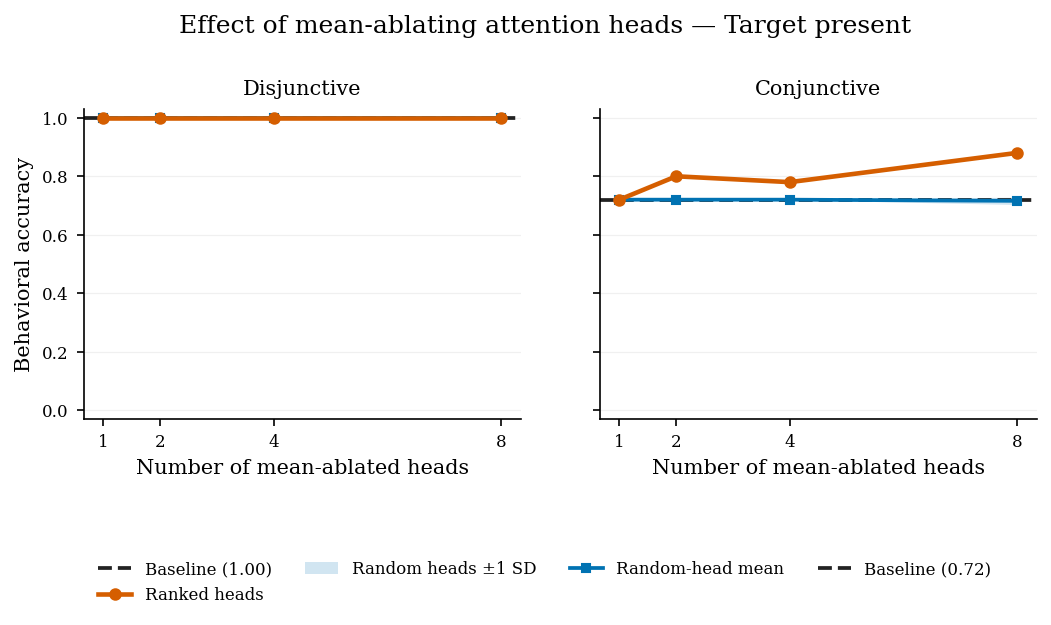

Saved: ../Results/top_heads_ablation_figures_offset_-9/zero_ablation_accuracy_target_present.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/zero_ablation_accuracy_target_present.png


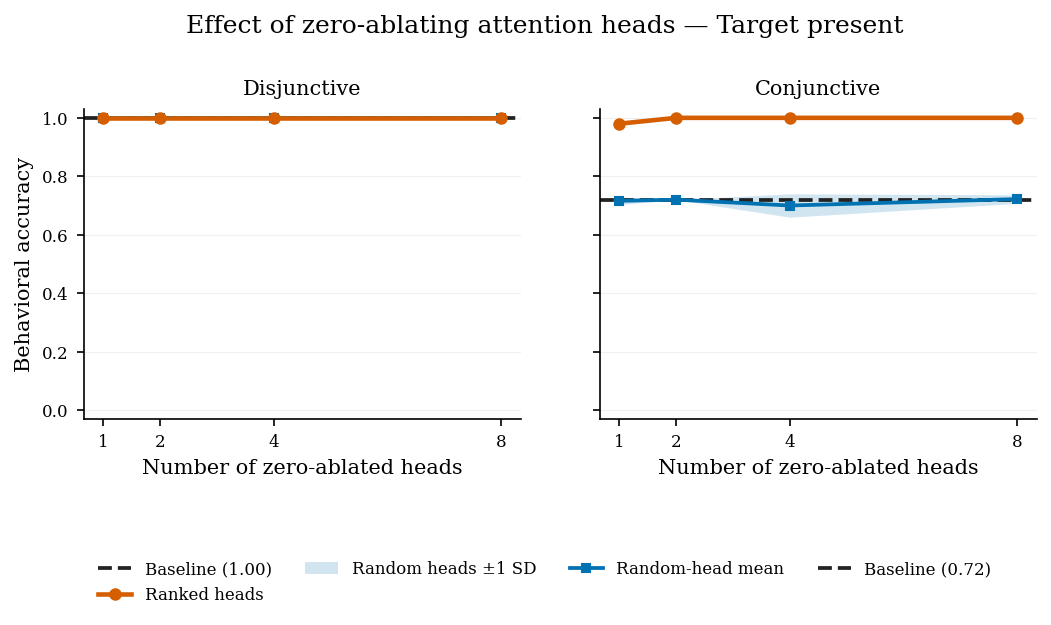

Saved: ../Results/top_heads_ablation_figures_offset_-9/mean_ablation_accuracy_target_absent.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/mean_ablation_accuracy_target_absent.png


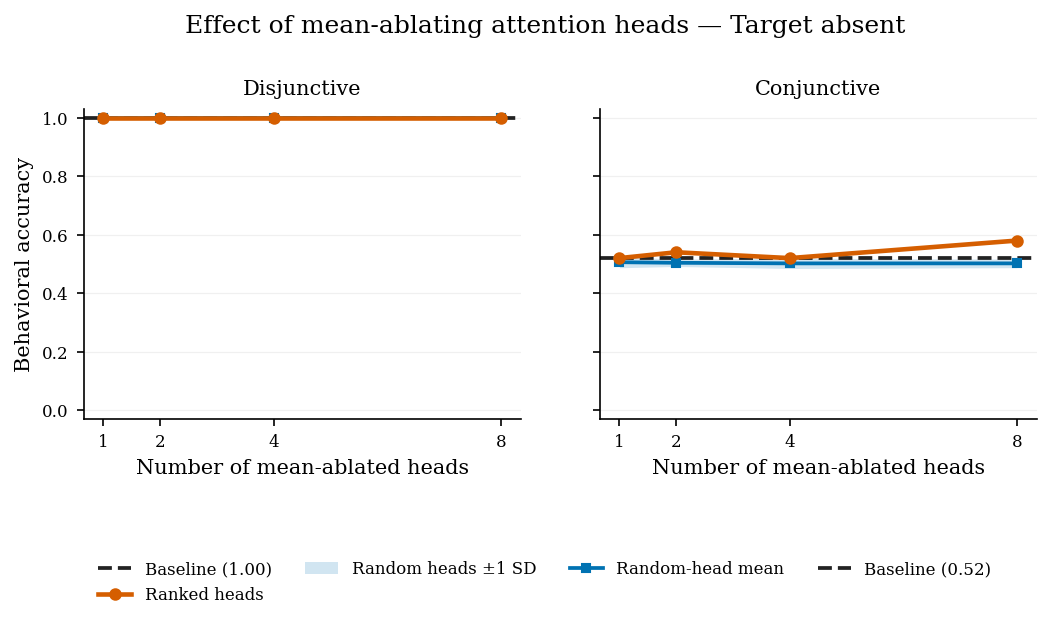

Saved: ../Results/top_heads_ablation_figures_offset_-9/zero_ablation_accuracy_target_absent.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/zero_ablation_accuracy_target_absent.png


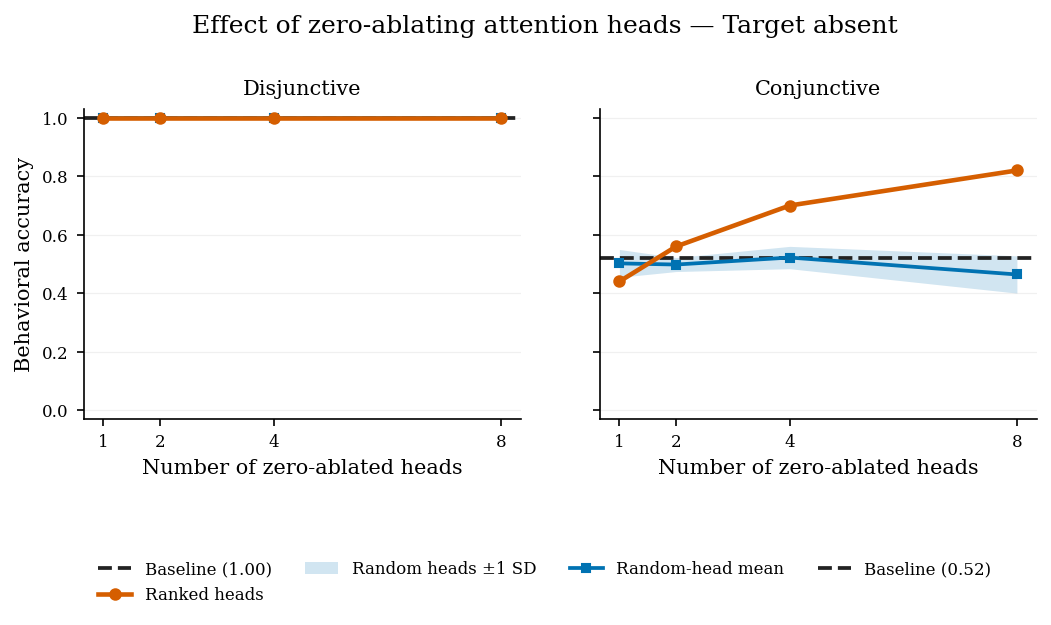

Saved: ../Results/top_heads_ablation_figures_offset_-9/mean_ablation_accuracy_both_targets.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/mean_ablation_accuracy_both_targets.png


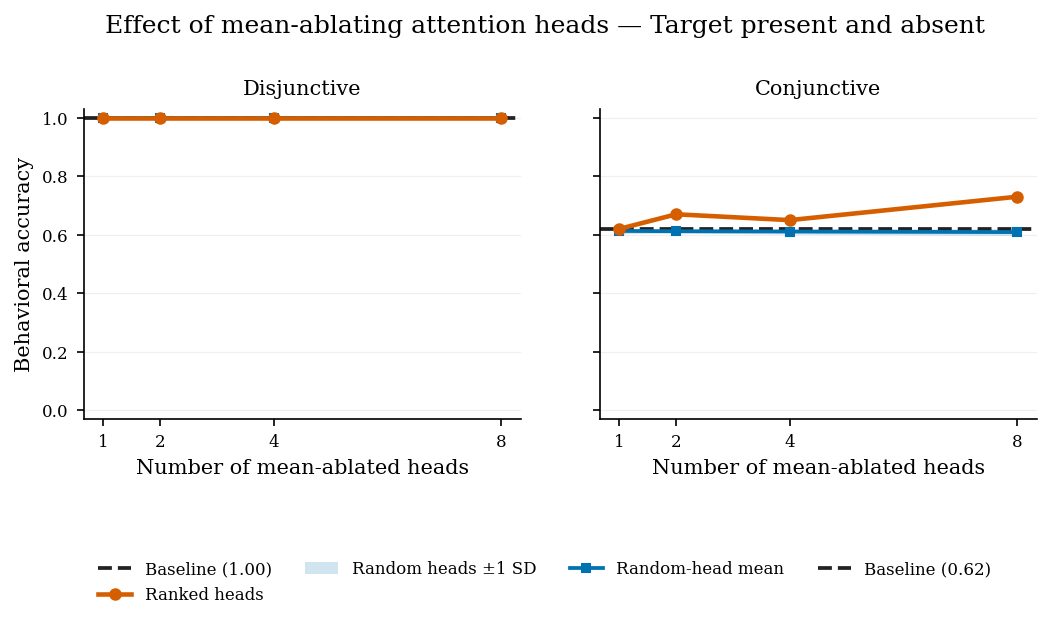

Saved: ../Results/top_heads_ablation_figures_offset_-9/zero_ablation_accuracy_both_targets.pdf
Saved: ../Results/top_heads_ablation_figures_offset_-9/zero_ablation_accuracy_both_targets.png


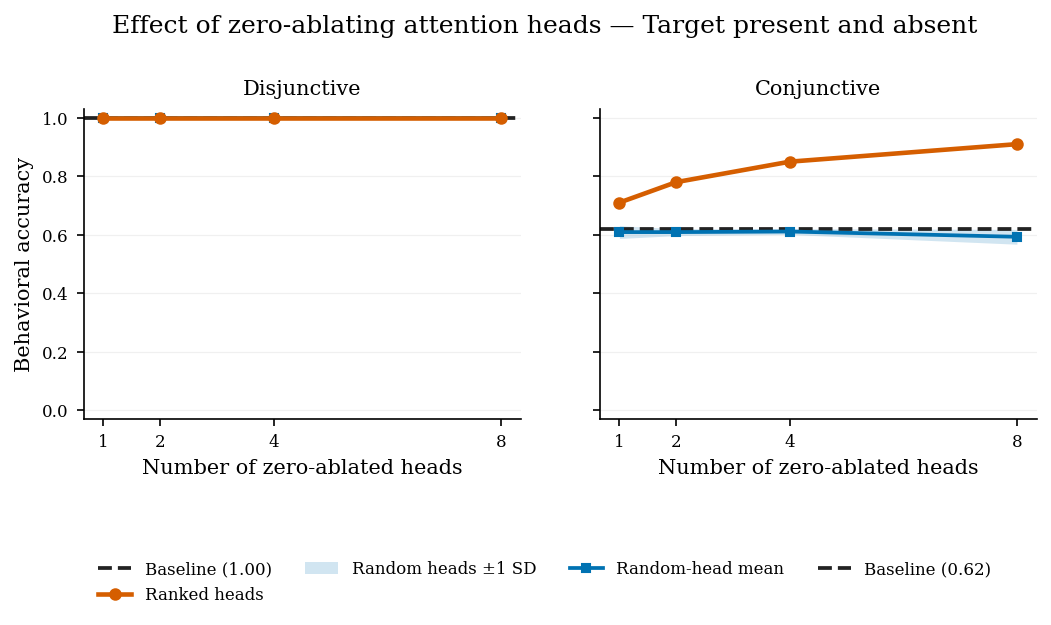

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "../Results/top_heads_ablation_both_conditions_offset_-9.csv"
)

OUTPUT_DIR = Path(
    "../Results/top_heads_ablation_figures_offset_-9"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ==========================================================
# LOAD AND CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    """Convert common textual Boolean encodings to bool."""
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )

    return series.astype(bool)


for column in [
    "target_present",
    "baseline_correct",
    "ablated_correct",
]:
    df[column] = parse_bool(df[column])

for column in [
    "head_count",
    "random_repeat",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

df["condition"] = (
    df["condition"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df["ablation_mode"] = (
    df["ablation_mode"]
    .astype(str)
    .str.strip()
    .str.lower()
)

df["intervention_group"] = (
    df["intervention_group"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Remove rows missing essential values.
df = df.dropna(
    subset=[
        "target_present",
        "baseline_correct",
        "ablated_correct",
        "head_count",
    ]
).copy()

print("Rows after cleaning:", len(df))
print("\nAblation modes:")
print(df["ablation_mode"].value_counts(dropna=False))

print("\nConditions:")
print(df["condition"].value_counts(dropna=False))

print("\nIntervention groups:")
print(df["intervention_group"].value_counts(dropna=False))


# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.8,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

RANKED_COLOR = "#D55E00"
RANDOM_COLOR = "#0072B2"
BASELINE_COLOR = "#222222"


# ==========================================================
# PANEL-SPECIFIC SUMMARY
# ==========================================================

def summarize_ablation(
    full_df,
    ablation_mode,
    target_present=None,
):
    """
    Summarize one ablation mode and one target subset.

    Parameters
    ----------
    full_df : pd.DataFrame
        Complete cleaned dataframe.

    ablation_mode : {"mean", "zero"}
        Head-ablation method.

    target_present : {True, False, None}
        True:
            Include target-present examples.
        False:
            Include target-absent examples.
        None:
            Include both target-present and target-absent
            examples.
    """

    subset = full_df[
        full_df["ablation_mode"].eq(ablation_mode)
    ].copy()

    if target_present is not None:
        subset = subset[
            subset["target_present"].eq(target_present)
        ].copy()

    if subset.empty:
        raise ValueError(
            f"No rows found for ablation_mode="
            f"{ablation_mode!r}, target_present="
            f"{target_present!r}"
        )

    # ------------------------------------------------------
    # SUMMARIZE EACH HEAD SET ACROSS TRIALS
    # ------------------------------------------------------

    # target_present is intentionally excluded here.
    # Therefore, when target_present=None, accuracy is
    # calculated jointly over present and absent examples.
    per_set = (
        subset.groupby(
            [
                "condition",
                "head_count",
                "intervention_group",
                "random_repeat",
            ],
            as_index=False,
            dropna=False,
        )
        .agg(
            n_trials=("trial", "size"),
            baseline_accuracy=(
                "baseline_correct",
                "mean",
            ),
            ablated_accuracy=(
                "ablated_correct",
                "mean",
            ),
        )
    )

    # Ranked-head intervention.
    ranked = (
        per_set[
            per_set["intervention_group"].eq("ranked")
        ]
        .copy()
    )

    # In case more than one ranked set remains at a head
    # count, aggregate them into a single plotted value.
    ranked_summary = (
        ranked.groupby(
            [
                "condition",
                "head_count",
            ],
            as_index=False,
        )
        .agg(
            ranked_accuracy=(
                "ablated_accuracy",
                "mean",
            ),
            n_ranked_sets=(
                "ablated_accuracy",
                "size",
            ),
        )
    )

    # Random-head control: mean ± SD across random sets.
    random_summary = (
        per_set[
            per_set["intervention_group"].eq("random")
        ]
        .groupby(
            [
                "condition",
                "head_count",
            ],
            as_index=False,
        )
        .agg(
            random_accuracy_mean=(
                "ablated_accuracy",
                "mean",
            ),
            random_accuracy_std=(
                "ablated_accuracy",
                "std",
            ),
            n_random_sets=(
                "random_repeat",
                "nunique",
            ),
        )
    )

    # ------------------------------------------------------
    # BASELINE ACCURACY
    # ------------------------------------------------------

    # Baseline results are duplicated across intervention
    # groups, head counts, and random repeats. Keep one row
    # per original example before calculating accuracy.
    #
    # target_present is included in the duplicate key because
    # trial identifiers could repeat between present and
    # absent subsets.
    baseline = (
        subset.drop_duplicates(
            [
                "target_present",
                "condition",
                "trial",
            ]
        )
        .groupby(
            "condition",
            as_index=False,
        )
        .agg(
            baseline_accuracy=(
                "baseline_correct",
                "mean",
            ),
            n_trials=("trial", "size"),
        )
    )

    return (
        subset,
        ranked_summary,
        random_summary,
        baseline,
    )


# ==========================================================
# CREATE ONE TWO-PANEL FIGURE
# ==========================================================

def plot_ablation_figure(
    full_df,
    ablation_mode,
    target_present,
    output_dir,
    save_figures=True,
):
    """
    Create a two-panel figure containing:
      - Disjunctive performance
      - Conjunctive performance
    """

    (
        subset,
        ranked_summary,
        random_summary,
        baseline,
    ) = summarize_ablation(
        full_df=full_df,
        ablation_mode=ablation_mode,
        target_present=target_present,
    )

    head_counts = sorted(
        subset["head_count"]
        .dropna()
        .unique()
    )

    # ------------------------------------------------------
    # TARGET LABELS
    # ------------------------------------------------------

    if target_present is True:
        target_title = "Target present"
        target_filename = "target_present"
    elif target_present is False:
        target_title = "Target absent"
        target_filename = "target_absent"
    else:
        target_title = "Target present and absent"
        target_filename = "both_targets"

    ablation_title = ablation_mode.capitalize()
    ablation_filename = ablation_mode.lower()

    # ------------------------------------------------------
    # FIGURE
    # ------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(8.2, 3.5),
        sharey=True,
        gridspec_kw={"wspace": 0.18},
    )

    for ax, condition in zip(
        axes,
        ["disjunctive", "conjunctive"],
    ):
        # --------------------------------------------------
        # BASELINE
        # --------------------------------------------------

        baseline_row = baseline[
            baseline["condition"].eq(condition)
        ]

        if baseline_row.empty:
            ax.text(
                0.5,
                0.5,
                "No data",
                transform=ax.transAxes,
                ha="center",
                va="center",
            )
            ax.set_title(condition.title())
            ax.set_xlabel(
                f"Number of {ablation_mode}-ablated heads"
            )
            continue

        baseline_accuracy = float(
            baseline_row["baseline_accuracy"].iloc[0]
        )

        ax.axhline(
            baseline_accuracy,
            color=BASELINE_COLOR,
            linestyle="--",
            linewidth=1.8,
            label=(
                f"Baseline "
                f"({baseline_accuracy:.2f})"
            ),
            zorder=2,
        )

        # --------------------------------------------------
        # RANKED HEADS
        # --------------------------------------------------

        ranked_panel = (
            ranked_summary[
                ranked_summary["condition"].eq(condition)
            ]
            .sort_values("head_count")
        )

        if not ranked_panel.empty:
            ax.plot(
                ranked_panel["head_count"],
                ranked_panel["ranked_accuracy"],
                color=RANKED_COLOR,
                marker="o",
                markersize=5,
                linewidth=2.2,
                label="Ranked heads",
                zorder=4,
            )

        # --------------------------------------------------
        # RANDOM-HEAD CONTROL
        # --------------------------------------------------

        random_panel = (
            random_summary[
                random_summary["condition"].eq(condition)
            ]
            .sort_values("head_count")
        )

        if not random_panel.empty:
            x = (
                random_panel["head_count"]
                .to_numpy(dtype=float)
            )

            random_mean = (
                random_panel["random_accuracy_mean"]
                .to_numpy(dtype=float)
            )

            random_std = (
                random_panel["random_accuracy_std"]
                .fillna(0)
                .to_numpy(dtype=float)
            )

            lower = np.clip(
                random_mean - random_std,
                0,
                1,
            )

            upper = np.clip(
                random_mean + random_std,
                0,
                1,
            )

            ax.fill_between(
                x,
                lower,
                upper,
                color=RANDOM_COLOR,
                alpha=0.18,
                linewidth=0,
                label="Random heads ±1 SD",
                zorder=1,
            )

            ax.plot(
                x,
                random_mean,
                color=RANDOM_COLOR,
                marker="s",
                markersize=4,
                linewidth=1.8,
                label="Random-head mean",
                zorder=3,
            )

        # --------------------------------------------------
        # FORMATTING
        # --------------------------------------------------

        ax.set_title(
            condition.title(),
            pad=7,
        )

        ax.set_xlabel(
            f"Number of {ablation_mode}-ablated heads"
        )

        ax.set_xticks(head_counts)
        ax.set_ylim(-0.03, 1.03)

        ax.grid(
            axis="y",
            alpha=0.18,
            linewidth=0.6,
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    axes[0].set_ylabel("Behavioral accuracy")

    fig.suptitle(
        f"Effect of {ablation_mode}-ablating "
        f"attention heads — {target_title}",
        y=1.02,
        fontsize=12,
    )

    # ------------------------------------------------------
    # SHARED LEGEND
    # ------------------------------------------------------

    # Collect legend items from both axes so the legend still
    # works if one condition is missing a plotted group.
    handles = []
    labels = []

    for ax in axes:
        panel_handles, panel_labels = (
            ax.get_legend_handles_labels()
        )

        for handle, label in zip(
            panel_handles,
            panel_labels,
        ):
            if label not in labels:
                handles.append(handle)
                labels.append(label)

    fig.legend(
        handles,
        labels,
        loc="lower center",
        ncol=min(4, len(labels)),
        bbox_to_anchor=(0.5, -0.13),
        frameon=False,
    )

    fig.subplots_adjust(
        bottom=0.25,
        top=0.84,
    )

    # ------------------------------------------------------
    # SAVE
    # ------------------------------------------------------

    file_stem = (
        f"{ablation_filename}_ablation_accuracy_"
        f"{target_filename}"
    )

    pdf_path = output_dir / f"{file_stem}.pdf"
    png_path = output_dir / f"{file_stem}.png"

    if save_figures:
        fig.savefig(
            pdf_path,
            bbox_inches="tight",
        )

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
        )

        print("Saved:", pdf_path)
        print("Saved:", png_path)

    plt.show()
    plt.close(fig)


# ==========================================================
# GENERATE ALL SIX FIGURES
# ==========================================================

figure_specs = [
    # 1. Target present — mean ablation
    {
        "target_present": True,
        "ablation_mode": "mean",
    },

    # 2. Target present — zero ablation
    {
        "target_present": True,
        "ablation_mode": "zero",
    },

    # 3. Target absent — mean ablation
    {
        "target_present": False,
        "ablation_mode": "mean",
    },

    # 4. Target absent — zero ablation
    {
        "target_present": False,
        "ablation_mode": "zero",
    },

    # 5. Both target states — mean ablation
    {
        "target_present": None,
        "ablation_mode": "mean",
    },

    # 6. Both target states — zero ablation
    {
        "target_present": None,
        "ablation_mode": "zero",
    },
]


for spec in figure_specs:
    plot_ablation_figure(
        full_df=df,
        ablation_mode=spec["ablation_mode"],
        target_present=spec["target_present"],
        output_dir=OUTPUT_DIR,
        save_figures=True,
    )

In [4]:
print(df.columns.tolist())
print(df["random_repeat"].value_counts(dropna=False))
df["selection_type"] = np.where(
    pd.to_numeric(
        df["random_repeat"],
        errors="coerce",
    ).isna(),
    "ranked",
    "random",
)
split_summary = (
    df.groupby([
        "condition",
        "target_present",
        "selection_type",
        "head_count",
        "ablation_mode",
    ])
    .agg(
        n_rows=("trial", "size"),
        n_trials=("trial", "nunique"),
        baseline_accuracy=("baseline_correct", "mean"),
        ablated_accuracy=("ablated_correct", "mean"),
    )
    .reset_index()
)

display(split_summary)
def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )

    return series.astype(bool)


for column in [
    "target_present",
    "baseline_correct",
    "ablated_correct",
]:
    df[column] = parse_bool(df[column])
    df["rescued"] = (
    ~df["baseline_correct"]
    & df["ablated_correct"]
)

df["harmed"] = (
    df["baseline_correct"]
    & ~df["ablated_correct"]
)

df["unchanged_correct"] = (
    df["baseline_correct"]
    & df["ablated_correct"]
)

df["unchanged_incorrect"] = (
    ~df["baseline_correct"]
    & ~df["ablated_correct"]
)

flip_summary = (
    df.groupby([
        "condition",
        "target_present",
        "selection_type",
        "head_count",
        "ablation_mode",
    ])
    .agg(
        n_rows=("trial", "size"),
        n_trials=("trial", "nunique"),
        baseline_accuracy=("baseline_correct", "mean"),
        ablated_accuracy=("ablated_correct", "mean"),
        rescue_rate=("rescued", "mean"),
        harm_rate=("harmed", "mean"),
        unchanged_correct_rate=("unchanged_correct", "mean"),
        unchanged_incorrect_rate=("unchanged_incorrect", "mean"),
    )
    .reset_index()
)

flip_summary["net_rescue_rate"] = (
    flip_summary["rescue_rate"]
    - flip_summary["harm_rate"]
)

display(flip_summary)
display(
    flip_summary[
        (flip_summary["condition"] == "conjunctive")
        & (flip_summary["selection_type"] == "ranked")
    ].sort_values([
        "target_present",
        "head_count",
    ])
)

['condition', 'num_distractors', 'trial', 'target_present', 'image_path', 'ablation_mode', 'mean_grouping', 'head_count', 'actual_percentage', 'selected_heads', 'intervention_group', 'random_repeat', 'random_seed', 'ranking_group', 'ranking_metric', 'baseline_prediction', 'baseline_correct', 'baseline_true_logit', 'baseline_false_logit', 'baseline_margin', 'ablated_prediction', 'ablated_correct', 'ablated_true_logit', 'ablated_false_logit', 'ablated_margin', 'margin_decrease', 'accuracy_decrease', 'flip_correct_to_incorrect', 'token_offset', 'last_position', 'ablation_position', 'ablation_token_id', 'ablation_token', 'num_layers', 'num_heads', 'head_dim', 'error']
random_repeat
0     1600
1     1600
2     1600
3     1600
4     1600
5     1600
6     1600
7     1600
8     1600
9     1600
10    1600
Name: count, dtype: int64


,condition,target_present,selection_type,head_count,ablation_mode,n_rows,n_trials,baseline_accuracy,ablated_accuracy
0,conjunctive,False,random,1,mean,550,50,0.52,0.507273
1,conjunctive,False,random,1,zero,550,50,0.52,0.496364
2,conjunctive,False,random,2,mean,550,50,0.52,0.507273
3,conjunctive,False,random,2,zero,550,50,0.52,0.503636
4,conjunctive,False,random,4,mean,550,50,0.52,0.503636
5,conjunctive,False,random,4,zero,550,50,0.52,0.538182
6,conjunctive,False,random,8,mean,550,50,0.52,0.509091
7,conjunctive,False,random,8,zero,550,50,0.52,0.496364
8,conjunctive,True,random,1,mean,550,50,0.72,0.720000
9,conjunctive,True,random,1,zero,550,50,0.72,0.740000


,condition,target_present,selection_type,head_count,ablation_mode,n_rows,n_trials,baseline_accuracy,ablated_accuracy,rescue_rate,harm_rate,unchanged_correct_rate,unchanged_incorrect_rate,net_rescue_rate
0,conjunctive,False,random,1,mean,550,50,0.52,0.507273,0.000000,0.012727,0.507273,0.480000,-0.012727
1,conjunctive,False,random,1,zero,550,50,0.52,0.496364,0.003636,0.027273,0.492727,0.476364,-0.023636
2,conjunctive,False,random,2,mean,550,50,0.52,0.507273,0.001818,0.014545,0.505455,0.478182,-0.012727
3,conjunctive,False,random,2,zero,550,50,0.52,0.503636,0.003636,0.020000,0.500000,0.476364,-0.016364
4,conjunctive,False,random,4,mean,550,50,0.52,0.503636,0.003636,0.020000,0.500000,0.476364,-0.016364
5,conjunctive,False,random,4,zero,550,50,0.52,0.538182,0.030909,0.012727,0.507273,0.449091,0.018182
6,conjunctive,False,random,8,mean,550,50,0.52,0.509091,0.007273,0.018182,0.501818,0.472727,-0.010909
7,conjunctive,False,random,8,zero,550,50,0.52,0.496364,0.029091,0.052727,0.467273,0.450909,-0.023636
8,conjunctive,True,random,1,mean,550,50,0.72,0.720000,0.000000,0.000000,0.720000,0.280000,0.000000
9,conjunctive,True,random,1,zero,550,50,0.72,0.740000,0.023636,0.003636,0.716364,0.256364,0.020000


,condition,target_present,selection_type,head_count,ablation_mode,n_rows,n_trials,baseline_accuracy,ablated_accuracy,rescue_rate,harm_rate,unchanged_correct_rate,unchanged_incorrect_rate,net_rescue_rate


Rows after cleaning: 21900

Conditions:
condition
disjunctive    12600
conjunctive     9300
Name: count, dtype: int64

Ablation modes:
ablation_mode
mean    10950
zero    10950
Name: count, dtype: int64

Intervention groups:
intervention_group
random    15640
ranked     6260
Name: count, dtype: int64

Ranking groups:
ranking_group
random_control    15640
target_present     3130
target_absent      3130
Name: count, dtype: int64

Ranked cross-test counts:
ranking_group   target_present
target_absent   False             1330
                True              1800
target_present  False             1330
                True              1800
dtype: int64

Complete ranking-by-target cross-test found.
Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/disjunctive_mean_ablation_cross_target_2x2.pdf
Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/disjunctive_mean_ablation_cross_target_2x2.png


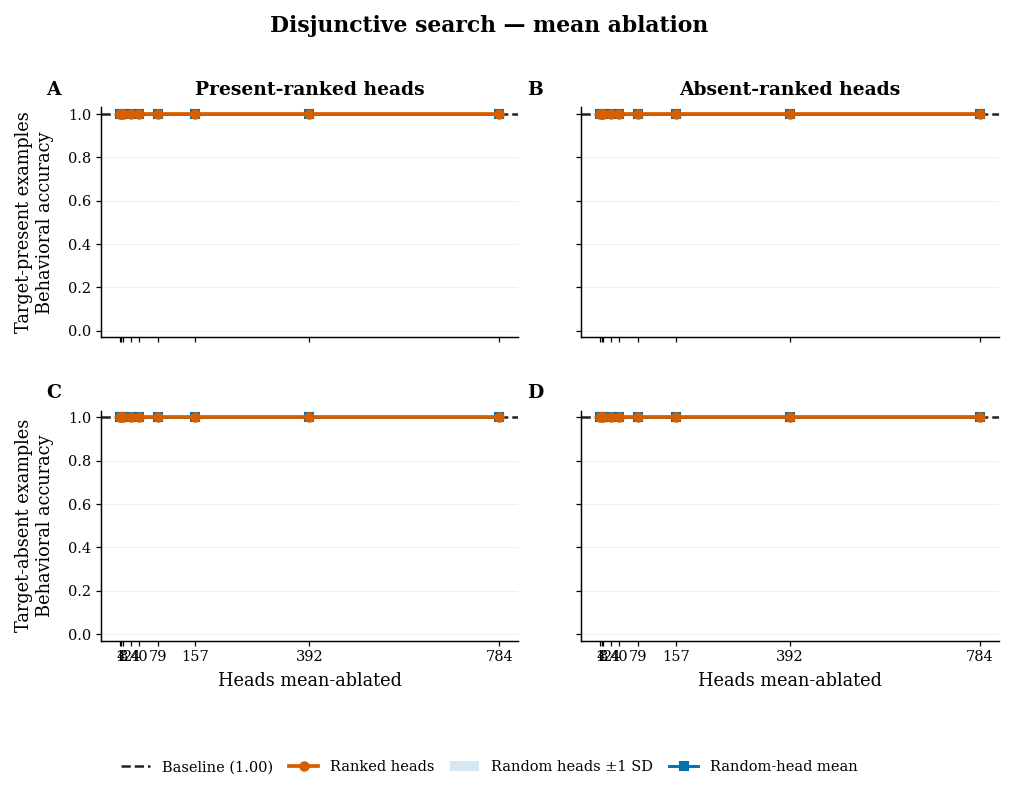

Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/disjunctive_zero_ablation_cross_target_2x2.pdf
Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/disjunctive_zero_ablation_cross_target_2x2.png


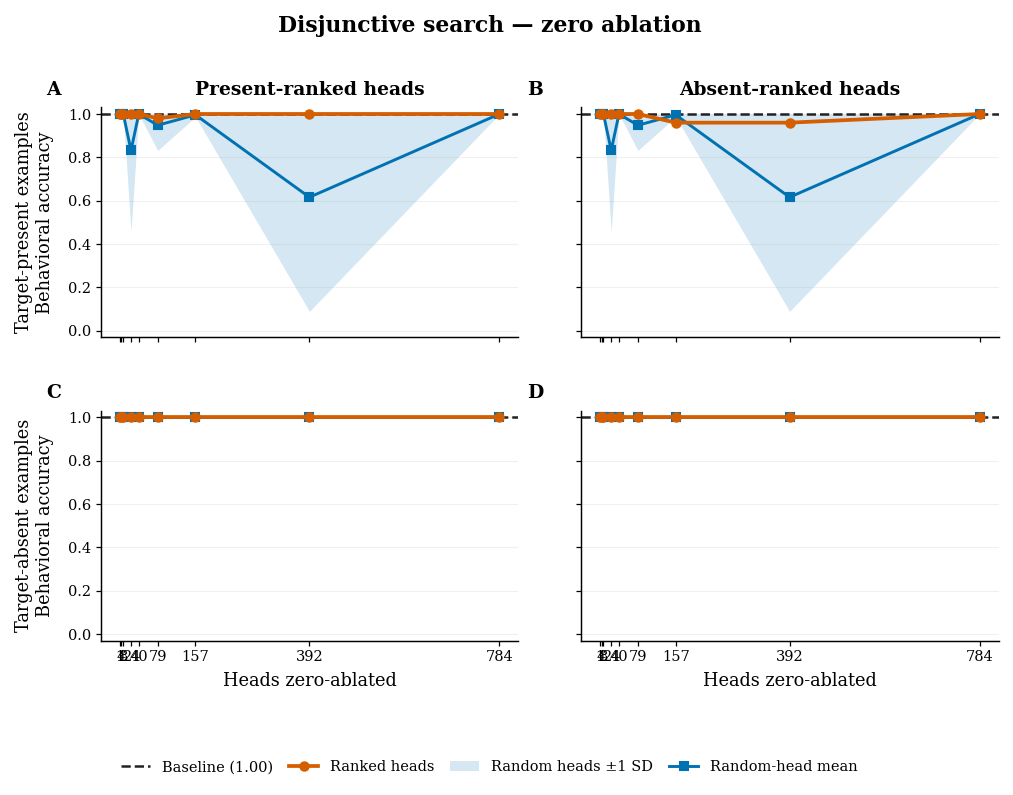

Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/conjunctive_mean_ablation_cross_target_2x2.pdf
Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/conjunctive_mean_ablation_cross_target_2x2.png


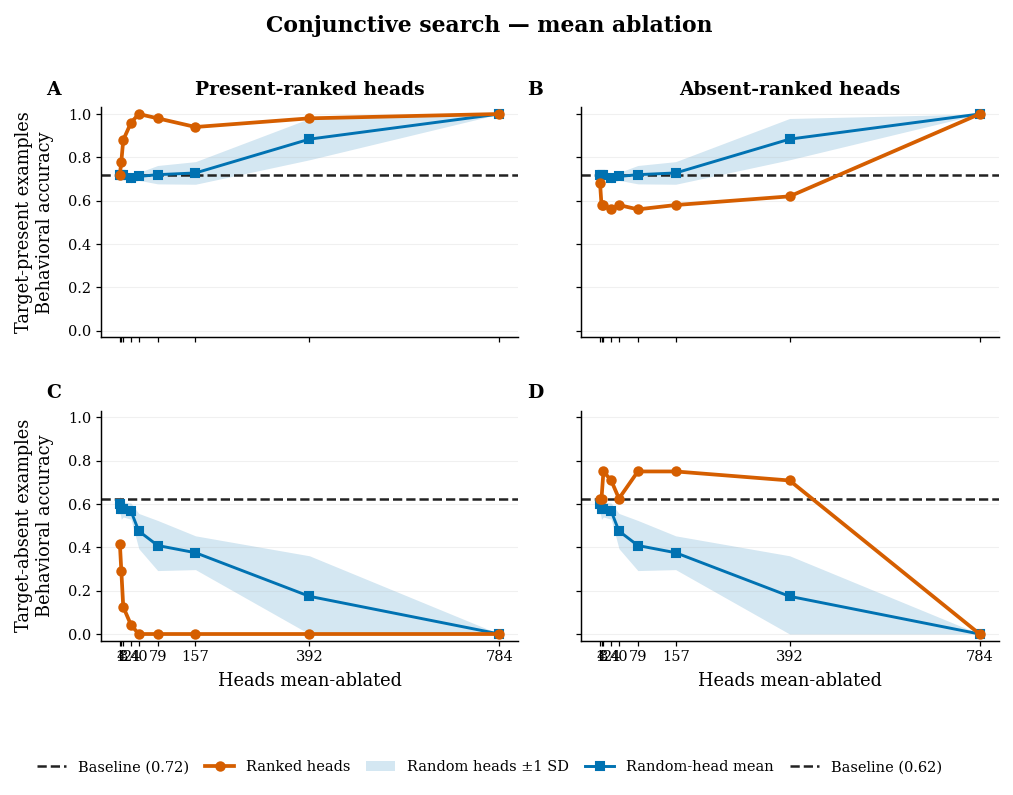

Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/conjunctive_zero_ablation_cross_target_2x2.pdf
Saved: ../Results/top_heads_ablation_cross_target_figures_offset_-9/conjunctive_zero_ablation_cross_target_2x2.png


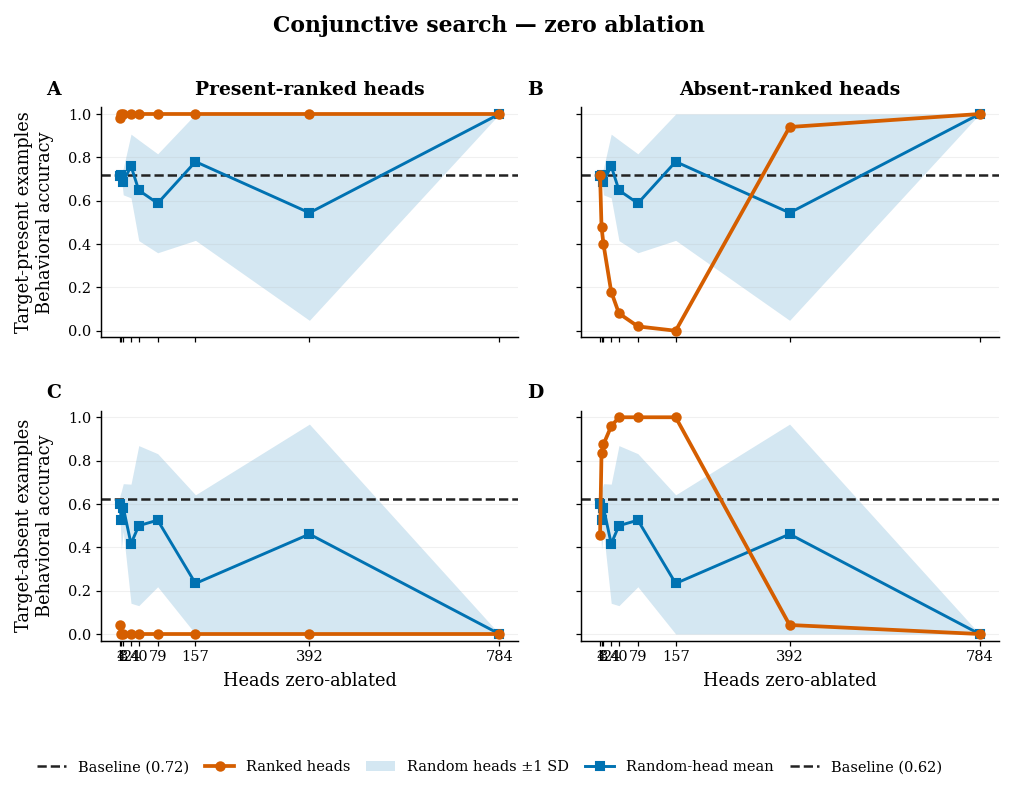

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "../Results/"
    "top_heads_ablation_both_conditions_offset_-9_pct.csv"
)

OUTPUT_DIR = Path(
    "../Results/"
    "top_heads_ablation_cross_target_figures_offset_-9"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ==========================================================
# LOAD AND CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    """Convert common Boolean encodings to bool."""

    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )

    return series.astype(bool)


for column in [
    "target_present",
    "baseline_correct",
    "ablated_correct",
]:
    df[column] = parse_bool(df[column])


for column in [
    "head_count",
    "ablation_percentage",
    "random_repeat",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )


for column in [
    "condition",
    "ablation_mode",
    "intervention_group",
    "ranking_group",
]:
    df[column] = (
        df[column]
        .astype(str)
        .str.strip()
        .str.lower()
    )


required_columns = {
    "condition",
    "target_present",
    "ablation_mode",
    "intervention_group",
    "ranking_group",
    "head_count",
    "baseline_correct",
    "ablated_correct",
    "random_repeat",
    "trial",
}

missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing columns: {sorted(missing_columns)}"
    )


df = df.dropna(
    subset=[
        "target_present",
        "head_count",
        "baseline_correct",
        "ablated_correct",
    ]
).copy()


print("Rows after cleaning:", len(df))

print("\nConditions:")
print(df["condition"].value_counts(dropna=False))

print("\nAblation modes:")
print(df["ablation_mode"].value_counts(dropna=False))

print("\nIntervention groups:")
print(df["intervention_group"].value_counts(dropna=False))

print("\nRanking groups:")
print(df["ranking_group"].value_counts(dropna=False))

print("\nRanked cross-test counts:")
print(
    df[
        df["intervention_group"].eq("ranked")
    ]
    .groupby([
        "ranking_group",
        "target_present",
    ])
    .size()
)


# ==========================================================
# VERIFY THAT THE FULL CROSS-TEST EXISTS
# ==========================================================

expected_cross_test = {
    ("target_present", True),
    ("target_present", False),
    ("target_absent", True),
    ("target_absent", False),
}

observed_cross_test = set(
    df.loc[
        df["intervention_group"].eq("ranked"),
        [
            "ranking_group",
            "target_present",
        ],
    ]
    .drop_duplicates()
    .itertuples(
        index=False,
        name=None,
    )
)

missing_cross_test = (
    expected_cross_test
    - observed_cross_test
)

if missing_cross_test:
    raise ValueError(
        "The CSV does not contain the complete cross-test. "
        f"Missing combinations: {missing_cross_test}"
    )

print("\nComplete ranking-by-target cross-test found.")


# ==========================================================
# NEURIPS-STYLE SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "legend.fontsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "axes.linewidth": 0.7,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

RANKED_COLOR = "#D55E00"
RANDOM_COLOR = "#0072B2"
BASELINE_COLOR = "#222222"


# ==========================================================
# SUMMARIZE ONE PANEL
# ==========================================================

def summarize_panel(
    full_df,
    condition,
    ablation_mode,
    evaluation_target_present,
    ranking_group,
):
    """
    Summarize one cell of the ranking-by-target cross-test.

    Rows of the final figure correspond to the target label
    of the evaluated examples.

    Columns correspond to the target label used to rank the
    ablated attention heads.
    """

    common = full_df[
        full_df["condition"].eq(condition)
        & full_df["ablation_mode"].eq(
            ablation_mode
        )
        & full_df["target_present"].eq(
            evaluation_target_present
        )
    ].copy()

    if common.empty:
        raise ValueError(
            "No rows found for "
            f"condition={condition!r}, "
            f"ablation_mode={ablation_mode!r}, "
            "evaluation_target_present="
            f"{evaluation_target_present!r}"
        )

    # ------------------------------------------------------
    # RANKED HEADS
    # ------------------------------------------------------

    ranked_rows = common[
        common["intervention_group"].eq("ranked")
        & common["ranking_group"].eq(
            ranking_group
        )
    ].copy()

    ranked_summary = (
        ranked_rows.groupby(
            "head_count",
            as_index=False,
        )
        .agg(
            ranked_accuracy=(
                "ablated_correct",
                "mean",
            ),
            n_trials=(
                "trial",
                "nunique",
            ),
        )
        .sort_values("head_count")
    )

    # ------------------------------------------------------
    # RANDOM CONTROLS
    #
    # First calculate accuracy for each independently sampled
    # random-head set. Then calculate mean ± SD across the
    # 10 random sets.
    # ------------------------------------------------------

    random_rows = common[
        common["intervention_group"].eq("random")
    ].copy()

    random_per_set = (
        random_rows.groupby(
            [
                "head_count",
                "random_repeat",
            ],
            as_index=False,
        )
        .agg(
            random_accuracy=(
                "ablated_correct",
                "mean",
            ),
        )
    )

    random_summary = (
        random_per_set.groupby(
            "head_count",
            as_index=False,
        )
        .agg(
            random_accuracy_mean=(
                "random_accuracy",
                "mean",
            ),
            random_accuracy_std=(
                "random_accuracy",
                "std",
            ),
            n_random_sets=(
                "random_repeat",
                "nunique",
            ),
        )
        .sort_values("head_count")
    )

    # ------------------------------------------------------
    # BASELINE
    #
    # Baseline values are duplicated across head counts,
    # intervention groups, and random repeats. Keep one row
    # per original example.
    # ------------------------------------------------------

    baseline_examples = (
        common.drop_duplicates([
            "condition",
            "target_present",
            "trial",
        ])
    )

    baseline_accuracy = (
        baseline_examples[
            "baseline_correct"
        ].mean()
    )

    return (
        ranked_summary,
        random_summary,
        float(baseline_accuracy),
    )


# ==========================================================
# CREATE ONE 2 × 2 CROSS-TEST FIGURE
# ==========================================================

def plot_cross_test(
    full_df,
    condition,
    ablation_mode,
    output_dir,
    save_figure=True,
):
    """
    Create a 2 × 2 cross-test figure.

    Columns:
        Present-ranked heads
        Absent-ranked heads

    Rows:
        Target-present examples
        Target-absent examples
    """

    evaluation_specs = [
        (
            True,
            "Target-present examples",
        ),
        (
            False,
            "Target-absent examples",
        ),
    ]

    ranking_specs = [
        (
            "target_present",
            "Present-ranked heads",
        ),
        (
            "target_absent",
            "Absent-ranked heads",
        ),
    ]

    figure_df = full_df[
        full_df["condition"].eq(condition)
        & full_df["ablation_mode"].eq(
            ablation_mode
        )
    ].copy()

    if figure_df.empty:
        print(
            "Skipping missing condition: "
            f"{condition}, {ablation_mode}"
        )
        return

    head_counts = sorted(
        figure_df["head_count"]
        .dropna()
        .unique()
    )

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(7.0, 5.15),
        sharex=True,
        sharey=True,
        gridspec_kw={
            "wspace": 0.15,
            "hspace": 0.32,
        },
    )

    for row, (
        evaluation_target,
        evaluation_title,
    ) in enumerate(evaluation_specs):

        for column, (
            ranking_group,
            ranking_title,
        ) in enumerate(ranking_specs):

            ax = axes[row, column]

            (
                ranked_summary,
                random_summary,
                baseline_accuracy,
            ) = summarize_panel(
                full_df=full_df,
                condition=condition,
                ablation_mode=ablation_mode,
                evaluation_target_present=(
                    evaluation_target
                ),
                ranking_group=ranking_group,
            )

            # ------------------------------------------------
            # BASELINE
            # ------------------------------------------------

            ax.axhline(
                baseline_accuracy,
                color=BASELINE_COLOR,
                linestyle="--",
                linewidth=1.2,
                label=(
                    f"Baseline "
                    f"({baseline_accuracy:.2f})"
                ),
                zorder=2,
            )

            # ------------------------------------------------
            # RANKED HEADS
            # ------------------------------------------------

            if not ranked_summary.empty:
                ax.plot(
                    ranked_summary["head_count"],
                    ranked_summary[
                        "ranked_accuracy"
                    ],
                    color=RANKED_COLOR,
                    marker="o",
                    markersize=4,
                    linewidth=1.8,
                    label="Ranked heads",
                    zorder=4,
                )

            # ------------------------------------------------
            # RANDOM CONTROLS
            # ------------------------------------------------

            if not random_summary.empty:
                x = (
                    random_summary["head_count"]
                    .to_numpy(dtype=float)
                )

                random_mean = (
                    random_summary[
                        "random_accuracy_mean"
                    ]
                    .to_numpy(dtype=float)
                )

                random_std = (
                    random_summary[
                        "random_accuracy_std"
                    ]
                    .fillna(0)
                    .to_numpy(dtype=float)
                )

                lower = np.clip(
                    random_mean - random_std,
                    0,
                    1,
                )

                upper = np.clip(
                    random_mean + random_std,
                    0,
                    1,
                )

                ax.fill_between(
                    x,
                    lower,
                    upper,
                    color=RANDOM_COLOR,
                    alpha=0.17,
                    linewidth=0,
                    label="Random heads ±1 SD",
                    zorder=1,
                )

                ax.plot(
                    x,
                    random_mean,
                    color=RANDOM_COLOR,
                    marker="s",
                    markersize=3.5,
                    linewidth=1.4,
                    label="Random-head mean",
                    zorder=3,
                )

            # ------------------------------------------------
            # PANEL TITLES AND LABELS
            # ------------------------------------------------

            if row == 0:
                ax.set_title(
                    ranking_title,
                    fontweight="semibold",
                    pad=6,
                )

            if column == 0:
                ax.set_ylabel(
                    f"{evaluation_title}\n"
                    "Behavioral accuracy",
                    labelpad=7,
                )

            if row == 1:
                ax.set_xlabel(
                    f"Heads {ablation_mode}-ablated"
                )

            ax.set_xticks(head_counts)
            ax.set_ylim(-0.03, 1.03)

            ax.grid(
                axis="y",
                alpha=0.18,
                linewidth=0.5,
            )

            ax.tick_params(
                width=0.6,
                length=2.5,
                pad=2,
            )

            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

    # ======================================================
    # PANEL LABELS
    # ======================================================

    for label, ax in zip(
        ["A", "B", "C", "D"],
        axes.flat,
    ):
        ax.text(
            -0.13,
            1.04,
            label,
            transform=ax.transAxes,
            fontsize=9,
            fontweight="bold",
            va="bottom",
            ha="left",
            clip_on=False,
        )

    # ======================================================
    # SHARED LEGEND
    # ======================================================

    handles = []
    legend_labels = []

    for ax in axes.flat:
        panel_handles, panel_labels = (
            ax.get_legend_handles_labels()
        )

        for handle, label in zip(
            panel_handles,
            panel_labels,
        ):
            if label not in legend_labels:
                handles.append(handle)
                legend_labels.append(label)

    fig.legend(
        handles,
        legend_labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.01),
        ncol=min(5, len(legend_labels)),
        frameon=False,
        columnspacing=1.1,
        handlelength=2.0,
    )

    # ======================================================
    # OVERALL TITLE
    # ======================================================

    fig.suptitle(
        f"{condition.title()} search — "
        f"{ablation_mode} ablation",
        fontsize=10.5,
        fontweight="semibold",
        y=0.99,
    )

    fig.subplots_adjust(
        left=0.13,
        right=0.985,
        bottom=0.18,
        top=0.87,
    )

    # ======================================================
    # SAVE
    # ======================================================

    file_stem = (
        f"{condition}_"
        f"{ablation_mode}_ablation_"
        "cross_target_2x2"
    )

    pdf_path = (
        output_dir
        / f"{file_stem}.pdf"
    )

    png_path = (
        output_dir
        / f"{file_stem}.png"
    )

    if save_figure:
        fig.savefig(
            pdf_path,
            bbox_inches="tight",
            pad_inches=0.02,
        )

        fig.savefig(
            png_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

        print("Saved:", pdf_path)
        print("Saved:", png_path)

    plt.show()
    plt.close(fig)


# ==========================================================
# GENERATE ALL FOUR FIGURES
# ==========================================================

for condition in [
    "disjunctive",
    "conjunctive",
]:
    for ablation_mode in [
        "mean",
        "zero",
    ]:
        plot_cross_test(
            full_df=df,
            condition=condition,
            ablation_mode=ablation_mode,
            output_dir=OUTPUT_DIR,
            save_figure=True,
        )

# Vocab projection

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

# ==========================================================
# SETTINGS
# ==========================================================

CSV = Path(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/"
    "disj40_to_conj40_top1pct_vocab_offset_-11"
    "_per_example_top_tokens.csv"
)

TOP_N_HEADS = 8
TOP_K_TOKENS = 10

# Change this value to select a different random completed trial.
# Set to None for a different result every time the cell runs.
RANDOM_SEED = None

CONDITION_ORDER = [
    "native_target",
    "attention_patched",
    "value_patched",
    "full_source",
]

CONDITION_LABELS = {
    "native_target": "Native target: Atgt Vtgt",
    "attention_patched": "Attention patched: Asrc Vtgt",
    "value_patched": "Value patched: Atgt Vsrc",
    "full_source": "Full source: Asrc Vsrc",
}


# ==========================================================
# CHECK WHETHER THE FIRST INTERMEDIATE SAVE EXISTS
# ==========================================================

if not CSV.exists():
    raise FileNotFoundError(
        f"Intermediate CSV does not exist yet:\n{CSV}\n\n"
        "Wait until the extraction prints its first "
        "'Intermediate save' message."
    )


# ==========================================================
# RELOAD CURRENT INTERMEDIATE RESULTS
#
# Because the extraction uses atomic replacement, this read
# will see either the previous complete checkpoint or the new
# complete checkpoint, never a partially written CSV.
# ==========================================================

df = pd.read_csv(CSV).copy()

print("Loaded intermediate CSV:")
print(CSV)
print("Rows currently available:", len(df))


# ==========================================================
# CLEAN
# ==========================================================

def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )

    return series.astype(bool)


df["target_present"] = parse_bool(df["target_present"])

for column in [
    "trial",
    "layer",
    "head",
    "head_rank",
    "token_rank",
    "ranking_value",
    "logit",
]:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce",
    )

# Keep only top-token outputs if bottom tokens were also saved.
if "vocab_direction" in df.columns:
    df = df[
        df["vocab_direction"] == "top"
    ].copy()

df = df.dropna(
    subset=[
        "trial",
        "target_present",
        "layer",
        "head",
        "head_rank",
        "token_rank",
        "condition",
    ]
).copy()

df["trial"] = df["trial"].astype(int)
df["layer"] = df["layer"].astype(int)
df["head"] = df["head"].astype(int)
df["head_rank"] = df["head_rank"].astype(int)
df["token_rank"] = df["token_rank"].astype(int)

df = df[
    (df["head_rank"] <= TOP_N_HEADS)
    & (df["token_rank"] <= TOP_K_TOKENS)
].copy()


# ==========================================================
# IDENTIFY FULLY COMPLETED TRIALS
#
# Each completed trial should contain:
#   8 heads × 4 conditions × 10 tokens = 320 rows
# ==========================================================

expected_rows_per_trial = (
    TOP_N_HEADS
    * len(CONDITION_ORDER)
    * TOP_K_TOKENS
)

trial_checks = (
    df.groupby(
        ["trial", "target_present"],
        as_index=False,
    )
    .agg(
        rows=("token_rank", "size"),
        heads=("head_rank", "nunique"),
        conditions=("condition", "nunique"),
    )
)

complete_trials = trial_checks[
    (trial_checks["rows"] >= expected_rows_per_trial)
    & (trial_checks["heads"] == TOP_N_HEADS)
    & (
        trial_checks["conditions"]
        == len(CONDITION_ORDER)
    )
].copy()

if complete_trials.empty:
    raise RuntimeError(
        "The CSV exists, but no fully completed trial is "
        "available yet. Wait for the next intermediate save."
    )

print("\nExtraction progress visible to notebook:")
print("Complete matched pairs:", len(complete_trials))

print("\nComplete pairs by target label:")
display(
    complete_trials.groupby(
        "target_present"
    ).size().rename({
        True: "Target present",
        False: "Target absent",
    }).to_frame("Completed pairs")
)


# ==========================================================
# RANDOMLY SELECT ONE COMPLETED MATCHED PAIR
# ==========================================================

rng = np.random.default_rng(RANDOM_SEED)

selected_index = int(
    rng.integers(0, len(complete_trials))
)

selected = complete_trials.iloc[selected_index]

selected_trial = int(selected["trial"])
selected_target_present = bool(
    selected["target_present"]
)

label = (
    "Target Present"
    if selected_target_present
    else "Target Absent"
)

trial_df = df[
    (df["trial"] == selected_trial)
    & (
        df["target_present"]
        == selected_target_present
    )
].copy()

print("\n" + "=" * 110)
print(
    f"RANDOM COMPLETED PAIR: "
    f"{label} — Trial {selected_trial}"
)
print("=" * 110)

print(
    f"Source: disjunctive, 40 distractors, "
    f"trial {selected_trial}"
)
print(
    f"Target: conjunctive, 40 distractors, "
    f"trial {selected_trial}"
)


# ==========================================================
# HEAD SUMMARY
# ==========================================================

head_summary = (
    trial_df[
        [
            "head_rank",
            "layer",
            "head",
            "ranking_value",
        ]
    ]
    .drop_duplicates()
    .sort_values("head_rank")
    .copy()
)

head_summary["Head"] = [
    f"L{layer}H{head}"
    for layer, head in zip(
        head_summary["layer"],
        head_summary["head"],
    )
]

head_summary = head_summary.rename(
    columns={
        "head_rank": "Rank",
        "ranking_value": "Mean delta margin",
    }
)

print("\nTop-1% heads:")
display(
    head_summary[
        [
            "Rank",
            "Head",
            "Mean delta margin",
        ]
    ].reset_index(drop=True)
)


# ==========================================================
# FORMAT VOCABULARY TOKENS
# ==========================================================

def get_token_text(row):
    if (
        "decoded_token_repr" in row.index
        and pd.notna(row["decoded_token_repr"])
    ):
        return str(row["decoded_token_repr"])

    if (
        "decoded_token" in row.index
        and pd.notna(row["decoded_token"])
    ):
        return repr(str(row["decoded_token"]))

    return str(row["token"])


def format_vocabulary(group):
    group = (
        group.sort_values("token_rank")
        .drop_duplicates("token_rank")
    )

    outputs = []

    for _, row in group.iterrows():
        token = get_token_text(row)
        logit = row["logit"]

        if pd.notna(logit):
            outputs.append(
                f"{token} ({logit:.2f})"
            )
        else:
            outputs.append(token)

    return ", ".join(outputs)


# ==========================================================
# DETAILED VIEW: ONE TABLE PER HEAD
# ==========================================================

for head_rank in range(1, TOP_N_HEADS + 1):
    head_df = trial_df[
        trial_df["head_rank"] == head_rank
    ].copy()

    if head_df.empty:
        continue

    layer = int(head_df["layer"].iloc[0])
    head = int(head_df["head"].iloc[0])
    ranking_value = float(
        head_df["ranking_value"].iloc[0]
    )

    print(
        f"\nRank {head_rank}: "
        f"L{layer}H{head} "
        f"(mean delta margin = {ranking_value:.4f})"
    )

    output_rows = []

    for condition in CONDITION_ORDER:
        condition_df = head_df[
            head_df["condition"] == condition
        ].copy()

        output_rows.append({
            "Output": CONDITION_LABELS[condition],
            "Top vocabulary tokens": (
                format_vocabulary(condition_df)
                if not condition_df.empty
                else "No output found"
            ),
        })

    display(pd.DataFrame(output_rows))


# ==========================================================
# COMPACT VIEW
#
# One row per head and one column per A-V output.
# ==========================================================

compact_rows = []

for (
    head_rank,
    layer,
    head,
    condition,
), group in trial_df.groupby(
    [
        "head_rank",
        "layer",
        "head",
        "condition",
    ],
    sort=False,
):
    compact_rows.append({
        "Rank": int(head_rank),
        "Head": f"L{int(layer)}H{int(head)}",
        "condition": condition,
        "vocabulary": format_vocabulary(group),
    })

compact = pd.DataFrame(compact_rows)

compact_table = (
    compact.pivot(
        index=["Rank", "Head"],
        columns="condition",
        values="vocabulary",
    )
    .reindex(columns=CONDITION_ORDER)
    .reset_index()
    .sort_values("Rank")
    .rename(
        columns={
            "native_target": "Native: Atgt Vtgt",
            "attention_patched": "Attention: Asrc Vtgt",
            "value_patched": "Values: Atgt Vsrc",
            "full_source": "Full: Asrc Vsrc",
        }
    )
)

print("\n" + "=" * 110)
print(
    f"COMPACT VIEW: {label} — Trial {selected_trial}"
)
print("=" * 110)

display(compact_table)

Loaded intermediate CSV:
/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/disj40_to_conj40_top1pct_vocab_offset_-11_per_example_top_tokens.csv
Rows currently available: 9600

Extraction progress visible to notebook:
Complete matched pairs: 30

Complete pairs by target label:


,Completed pairs
target_present,
Target present,30



RANDOM COMPLETED PAIR: Target Present — Trial 4
Source: disjunctive, 40 distractors, trial 4
Target: conjunctive, 40 distractors, trial 4

Top-1% heads:


,Rank,Head,Mean delta margin
0,1,L14H8,0.23500
1,2,L14H0,0.17250
2,3,L14H13,0.12625
3,4,L14H2,0.11875
4,5,L10H2,0.07250
5,6,L15H15,0.06875
6,7,L16H1,0.04750
7,8,L14H20,0.04125



Rank 1: L14H8 (mean delta margin = 0.2350)


,Output,Top vocabulary tokens
0,Native target: Atgt Vtgt,"'码' (14.31), '騰' (12.69), ':eq' (11.56), 'izio..."
1,Attention patched: Asrc Vtgt,"'伯' (13.50), '阳' (12.31), '研发投入' (11.81), ' lo..."
2,Value patched: Atgt Vsrc,"'一小' (15.06), 'rees' (13.62), '取' (12.94), 'co..."
3,Full source: Asrc Vsrc,"'oters' (12.88), '向' (11.62), 'rage' (11.44), ..."


... (12 outputs left out)


Rank 8: L14H20 (mean delta margin = 0.0413)


,Output,Top vocabulary tokens
0,Native target: Atgt Vtgt,"'集中' (14.62), '悲哀' (14.44), '不如' (13.88), '滢' ..."
1,Attention patched: Asrc Vtgt,"'集中' (17.75), '不如' (14.00), '秣' (13.62), ' App..."
2,Value patched: Atgt Vsrc,"'滢' (15.50), '不如' (15.44), 'anio' (14.94), '湎'..."
3,Full source: Asrc Vsrc,"'滢' (14.56), '不如' (14.19), ' cioè' (13.81), '懒..."



COMPACT VIEW: Target Present — Trial 4


condition,Rank,Head,Native: Atgt Vtgt,Attention: Asrc Vtgt,Values: Atgt Vsrc,Full: Asrc Vsrc
0,1,L14H8,"'码' (14.31), '騰' (12.69), ':eq' (11.56), 'izio...","'伯' (13.50), '阳' (12.31), '研发投入' (11.81), ' lo...","'一小' (15.06), 'rees' (13.62), '取' (12.94), 'co...","'oters' (12.88), '向' (11.62), 'rage' (11.44), ..."
1,2,L14H0,"' MediaTek' (16.12), ' Qualcomm' (16.00), 'tol...","'伯' (13.00), '诸' (12.75), '叟' (12.62), '道' (12...","'fsp' (15.31), '千万别' (14.50), "">'+\n"" (14.38),...","'拐' (12.44), '这家伙' (12.06), 'urst' (11.50), 'd..."
2,3,L14H13,"'代言' (13.69), 'itol' (13.31), 'ńsk' (12.75), '...","'しておく' (15.88), '黢' (13.75), '很不错' (13.75), '在...","'.tell' (14.00), '流浪' (13.50), '总的' (13.19), '...","'.Contracts' (12.75), 'лас' (10.94), '面向' (10...."
3,4,L14H2,"'呵呵' (16.25), ' pushViewController' (15.94), '...","'消灭' (13.38), '创新型' (12.69), '冲击' (12.38), '反馈...","' pushViewController' (14.50), ' consect' (14....","'坊' (13.06), 'leness' (11.94), 'caf' (11.88), ..."
4,5,L10H2,"'窝' (14.25), '崒' (13.12), 'paralleled' (12.69)...","'iores' (14.31), '芭' (13.88), '践' (13.06), '屁股...","'摘' (14.75), 'erosis' (12.62), '亲' (12.38), '季...","'烊' (12.88), '现实生活' (12.50), '?""\n\n\n\n' (12...."
5,6,L15H15,"'憔' (14.75), '围' (11.69), '加盟店' (11.62), '往后' ...","'鳙' (14.56), '孝' (13.62), '逻辑' (13.50), '憔' (1...","'一夜' (13.94), '猎' (13.00), '伊' (12.69), '枕' (1...","'kers' (12.62), '参' (12.38), 'loe' (12.06), '围..."
6,7,L16H1,"'乐观' (12.50), '这么多' (12.00), '召集' (10.62), 'id...","'召集' (14.19), '迟到' (12.38), 'avic' (12.00), '....","'洛杉' (13.62), '这么多' (13.31), '不愿' (13.31), '个体...","'唯' (12.62), '容' (11.94), '异常' (11.81), '弹' (1..."
7,8,L14H20,"'集中' (14.62), '悲哀' (14.44), '不如' (13.88), '滢' ...","'集中' (17.75), '不如' (14.00), '秣' (13.62), ' App...","'滢' (15.50), '不如' (15.44), 'anio' (14.94), '湎'...","'滢' (14.56), '不如' (14.19), ' cioè' (13.81), '懒..."


## Visualize Attention Maps

,head_label,target_present,search_condition,mass_type,mean,sem,n
0,L14H8,True,Disjunctive,Image,0.974899,0.001206,50
1,L14H8,True,Disjunctive,Text,0.025101,0.001206,50
2,L14H8,True,Conjunctive,Image,0.982913,0.000500,50
3,L14H8,True,Conjunctive,Text,0.017087,0.000500,50
4,L14H8,False,Disjunctive,Image,0.679701,0.005664,50
5,L14H8,False,Disjunctive,Text,0.320299,0.005664,50
6,L14H8,False,Conjunctive,Image,0.984792,0.000468,50
7,L14H8,False,Conjunctive,Text,0.015208,0.000468,50
8,L14H0,True,Disjunctive,Image,0.801862,0.018414,50
9,L14H0,True,Disjunctive,Text,0.198138,0.018414,50


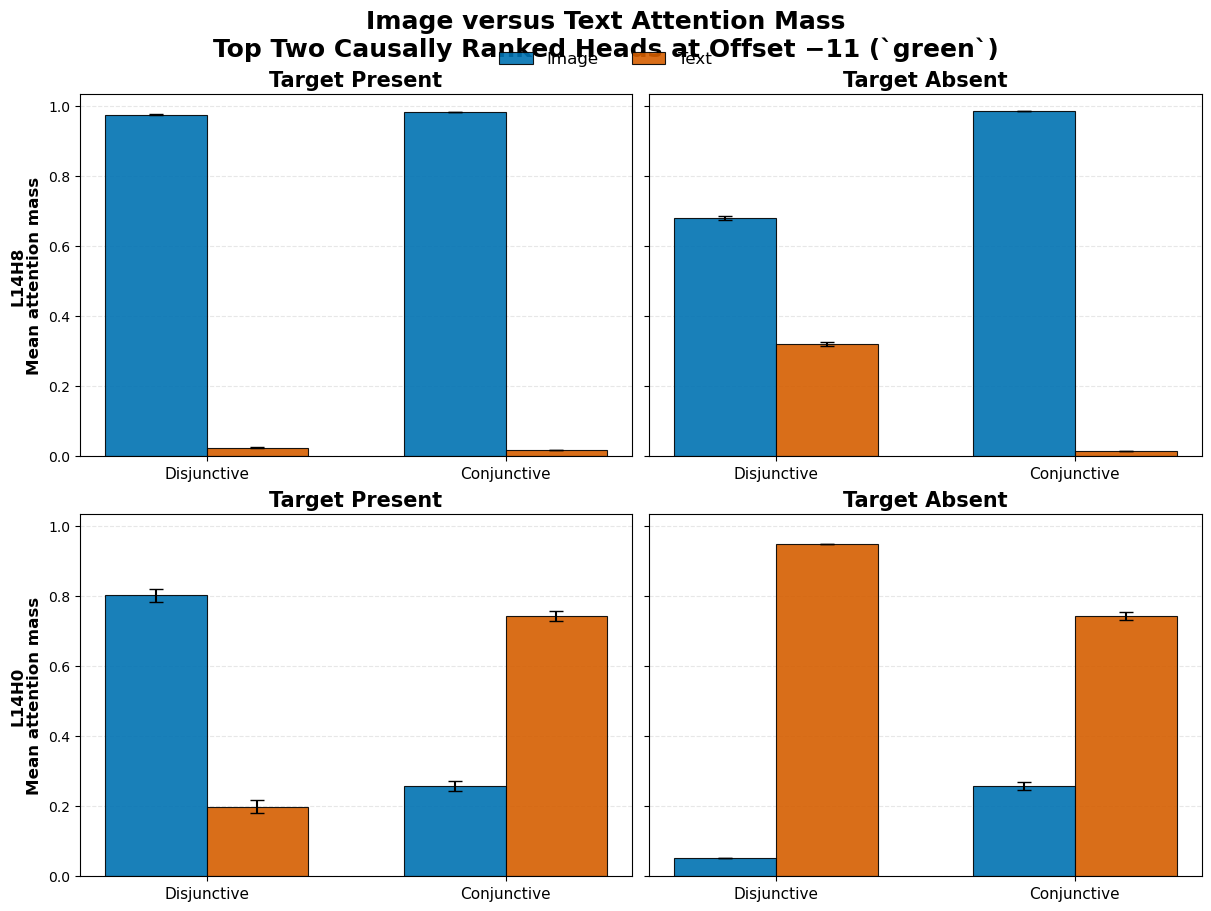

NameError: name 'png_path' is not defined

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# SETTINGS
# ==========================================================

TOP_HEADS = [
    (14, 8),
    (14, 0),
]

CONDITION_ORDER = [
    "Disjunctive",
    "Conjunctive",
]

TARGET_COLUMNS = [
    (True, "Target Present"),
    (False, "Target Absent"),
]

MASS_TYPES = [
    ("vision_mass", "Image", "#0072B2"),
    ("text_mass", "Text", "#D55E00"),
]


# ==========================================================
# SELECT TOP TWO HEADS
# ==========================================================

top_head_df = pd.concat(
    [
        df[
            (df["layer"] == layer)
            & (df["head"] == head)
        ].assign(
            head_label=f"L{layer}H{head}"
        )
        for layer, head in TOP_HEADS
    ],
    ignore_index=True,
)


# ==========================================================
# COMPUTE MEAN AND SEM
# ==========================================================

rows = []

for layer, head in TOP_HEADS:

    head_label = f"L{layer}H{head}"

    for target_present, _ in TARGET_COLUMNS:

        for condition in CONDITION_ORDER:

            subset = top_head_df[
                (
                    top_head_df["head_label"]
                    == head_label
                )
                & (
                    top_head_df["target_present"]
                    == target_present
                )
                & (
                    top_head_df["search_condition"]
                    == condition
                )
            ]

            for column, mass_label, _ in MASS_TYPES:

                values = (
                    subset[column]
                    .replace(
                        [np.inf, -np.inf],
                        np.nan,
                    )
                    .dropna()
                    .to_numpy()
                )

                if len(values) == 0:
                    mean = np.nan
                    sem = np.nan
                else:
                    mean = np.mean(values)

                    sem = (
                        np.std(values, ddof=1)
                        / np.sqrt(len(values))
                        if len(values) > 1
                        else 0
                    )

                rows.append({
                    "head_label": head_label,
                    "target_present": target_present,
                    "search_condition": condition,
                    "mass_type": mass_label,
                    "mean": mean,
                    "sem": sem,
                    "n": len(values),
                })


mass_summary = pd.DataFrame(rows)

display(mass_summary)


# ==========================================================
# PLOT
# ==========================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
    sharey=True,
    constrained_layout=True,
)

bar_width = 0.34
x = np.arange(len(CONDITION_ORDER))


for row_index, (layer, head) in enumerate(
    TOP_HEADS
):

    head_label = f"L{layer}H{head}"

    for column_index, (
        target_present,
        target_label,
    ) in enumerate(TARGET_COLUMNS):

        ax = axes[
            row_index,
            column_index,
        ]

        panel = mass_summary[
            (
                mass_summary["head_label"]
                == head_label
            )
            & (
                mass_summary["target_present"]
                == target_present
            )
        ]


        for mass_index, (
            _,
            mass_label,
            color,
        ) in enumerate(MASS_TYPES):

            mass_data = (
                panel[
                    panel["mass_type"]
                    == mass_label
                ]
                .set_index("search_condition")
                .reindex(CONDITION_ORDER)
            )

            means = mass_data[
                "mean"
            ].to_numpy()

            sems = mass_data[
                "sem"
            ].to_numpy()

            positions = (
                x
                + (
                    mass_index - 0.5
                ) * bar_width
            )

            ax.bar(
                positions,
                means,
                width=bar_width,
                yerr=sems,
                capsize=5,
                color=color,
                edgecolor="black",
                linewidth=0.8,
                alpha=0.90,
                label=mass_label,
                zorder=2,
            )


        ax.set_title(
            target_label,
            fontsize=15,
            fontweight="bold",
        )

        ax.set_xticks(x)

        ax.set_xticklabels(
            CONDITION_ORDER,
            fontsize=11,
        )

        ax.set_ylim(
            0,
            max(
                1.0,
                ax.get_ylim()[1],
            ),
        )

        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.3,
            zorder=0,
        )


        if column_index == 0:
            ax.set_ylabel(
                (
                    f"{head_label}\n"
                    "Mean attention mass"
                ),
                fontsize=12,
                fontweight="bold",
            )


# One shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.965),
    ncol=2,
    frameon=False,
    fontsize=12,
)

fig.suptitle(
    (
        "Image versus Text Attention Mass\n"
        "Top Two Causally Ranked Heads "
        "at Offset −11 (`green`)"
    ),
    fontsize=18,
    fontweight="bold",
)


# png_path = (
#     OUTPUT_DIR
#     / "top2_image_vs_text_attention_mass_offset_-11.png"
# )

# pdf_path = (
#     OUTPUT_DIR
#     / "top2_image_vs_text_attention_mass_offset_-11.pdf"
# )

# fig.savefig(
#     png_path,
#     dpi=300,
#     bbox_inches="tight",
# )

# fig.savefig(
#     pdf_path,
#     bbox_inches="tight",
# )

plt.show()

print("Saved:", png_path)
print("Saved:", pdf_path)

# Atomic Spatial Feature Map Patching

## Target present improvement analysis

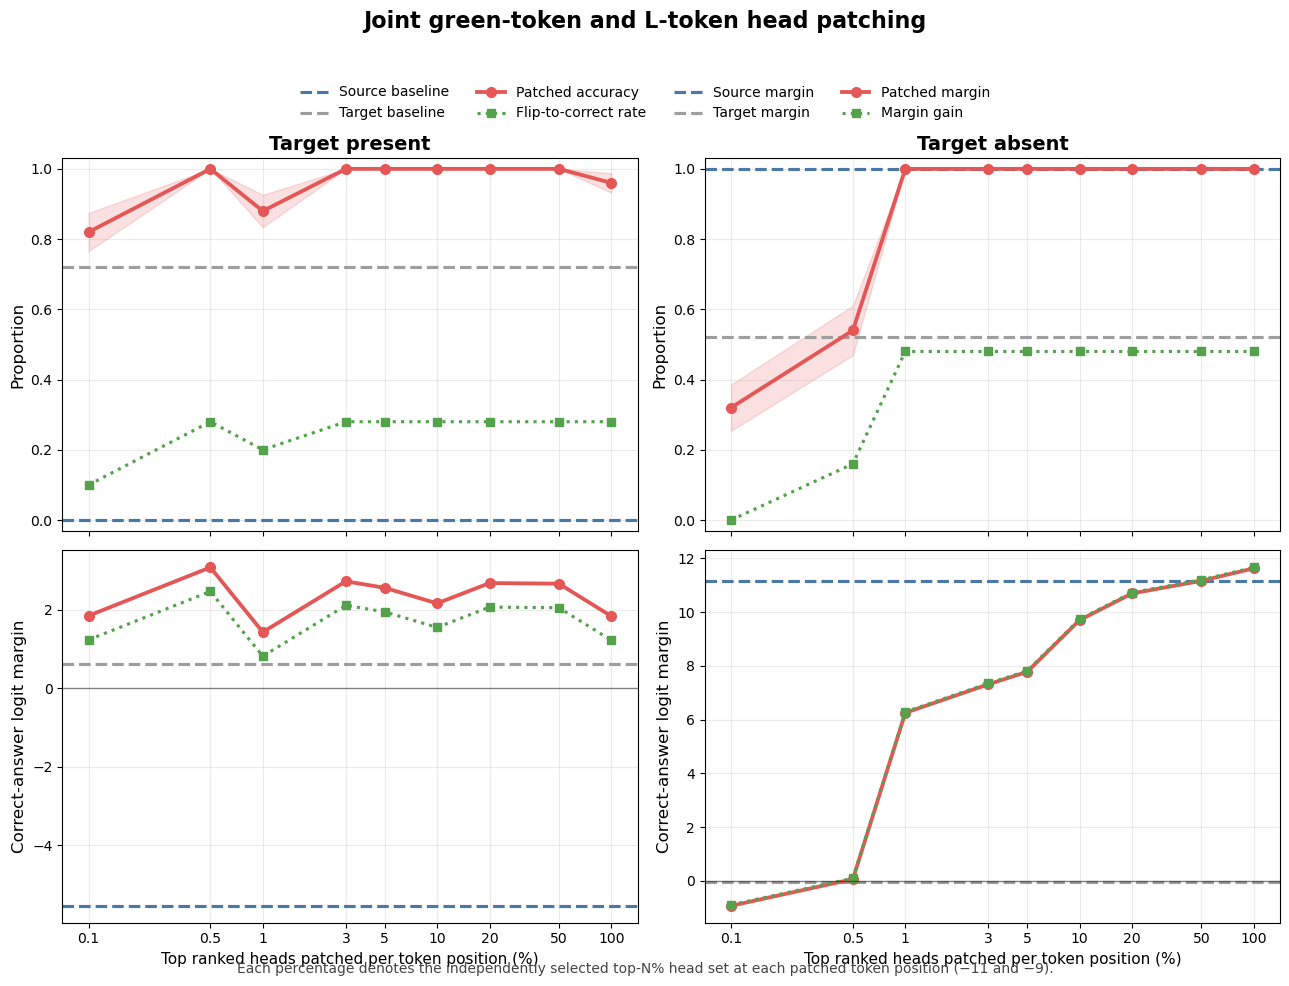

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "../Results/green_L_mask_to_conj40.csv"
)

OUTPUT_PATH = Path(
    "../Results/green_L_mask_to_conj40_performance.pdf"
)


# ==========================================================
# LOAD + CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
    "patched_flip_to_correct",
]:
    if column in df.columns:
        df[column] = parse_bool(df[column])


numeric_columns = [
    "patch_percentage",
    "source_margin",
    "target_margin",
    "patched_margin",
    "delta_margin",
    "recovery",
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")


# ==========================================================
# SUMMARIZE
# ==========================================================

summary = (
    df.groupby(["target_present", "patch_percentage"], as_index=False)
    .agg(
        n=("trial", "size"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        flip_to_correct_rate=("patched_flip_to_correct", "mean"),
        source_margin=("source_margin", "mean"),
        target_margin=("target_margin", "mean"),
        patched_margin=("patched_margin", "mean"),
        delta_margin=("delta_margin", "mean"),
        recovery=("recovery", "mean"),
    )
    .sort_values(["target_present", "patch_percentage"])
)

# Binomial standard errors for accuracy / flip rate.
for metric in [
    "patched_accuracy",
    "flip_to_correct_rate",
]:
    summary[f"{metric}_sem"] = np.sqrt(
        summary[metric] * (1 - summary[metric]) / summary["n"]
    )


# ==========================================================
# PLOT
# ==========================================================

COLORS = {
    "source": "#4C78A8",
    "target": "#9E9E9E",
    "patched": "#E45756",
    "gain": "#54A24B",
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(13, 9),
    sharex=True,
)

condition_info = [
    (True, "Target present"),
    (False, "Target absent"),
]

for column_index, (target_present, title) in enumerate(condition_info):
    ax_behavior = axes[0, column_index]
    ax_margin = axes[1, column_index]

    subset = (
        summary[summary["target_present"] == target_present]
        .sort_values("patch_percentage")
        .copy()
    )

    x = subset["patch_percentage"].to_numpy()

    # ------------------------------------------------------
    # Behavioral space
    # ------------------------------------------------------

    source_accuracy = subset["source_accuracy"].iloc[0]
    target_accuracy = subset["target_accuracy"].iloc[0]

    ax_behavior.axhline(
        source_accuracy,
        color=COLORS["source"],
        linestyle="--",
        linewidth=2.25,
        label="Source baseline",
    )

    ax_behavior.axhline(
        target_accuracy,
        color=COLORS["target"],
        linestyle="--",
        linewidth=2.25,
        label="Target baseline",
    )

    ax_behavior.plot(
        x,
        subset["patched_accuracy"],
        marker="o",
        linewidth=2.75,
        markersize=7,
        color=COLORS["patched"],
        label="Patched accuracy",
    )

    ax_behavior.fill_between(
        x,
        np.clip(
            subset["patched_accuracy"] - subset["patched_accuracy_sem"],
            0,
            1,
        ),
        np.clip(
            subset["patched_accuracy"] + subset["patched_accuracy_sem"],
            0,
            1,
        ),
        color=COLORS["patched"],
        alpha=0.18,
    )

    ax_behavior.plot(
        x,
        subset["flip_to_correct_rate"],
        marker="s",
        linestyle=":",
        linewidth=2.25,
        markersize=6,
        color=COLORS["gain"],
        label="Flip-to-correct rate",
    )

    ax_behavior.set_title(title, fontsize=14, fontweight="bold")
    ax_behavior.set_ylabel("Proportion", fontsize=12)
    ax_behavior.set_ylim(-0.03, 1.03)
    ax_behavior.grid(alpha=0.25)

    # ------------------------------------------------------
    # Margin space
    # ------------------------------------------------------

    source_margin = subset["source_margin"].iloc[0]
    target_margin = subset["target_margin"].iloc[0]

    ax_margin.axhline(
        source_margin,
        color=COLORS["source"],
        linestyle="--",
        linewidth=2.25,
        label="Source margin",
    )

    ax_margin.axhline(
        target_margin,
        color=COLORS["target"],
        linestyle="--",
        linewidth=2.25,
        label="Target margin",
    )

    ax_margin.plot(
        x,
        subset["patched_margin"],
        marker="o",
        linewidth=2.75,
        markersize=7,
        color=COLORS["patched"],
        label="Patched margin",
    )

    ax_margin.plot(
        x,
        subset["delta_margin"],
        marker="s",
        linestyle=":",
        linewidth=2.25,
        markersize=6,
        color=COLORS["gain"],
        label="Margin gain",
    )

    ax_margin.axhline(
        0,
        color="black",
        linewidth=1,
        alpha=0.45,
    )

    ax_margin.set_xlabel(
        "Top ranked heads patched per token position (%)",
        fontsize=11,
    )
    ax_margin.set_ylabel(
        "Correct-answer logit margin",
        fontsize=12,
    )
    ax_margin.grid(alpha=0.25)

    for axis in [ax_behavior, ax_margin]:
        axis.set_xscale("symlog", linthresh=0.1)
        axis.set_xticks(x)
        axis.set_xticklabels([f"{value:g}" for value in x])


# One shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
margin_handles, margin_labels = axes[1, 0].get_legend_handles_labels()

legend_items = dict(zip(labels + margin_labels, handles + margin_handles))

fig.legend(
    legend_items.values(),
    legend_items.keys(),
    loc="upper center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01),
)

fig.suptitle(
    "Joint green-token and L-token head patching",
    fontsize=16,
    fontweight="bold",
    y=1.08,
)

fig.text(
    0.5,
    0.01,
    "Each percentage denotes the independently selected top-N% head set "
    "at each patched token position (−11 and −9).",
    ha="center",
    fontsize=10,
    color="#444444",
)

plt.tight_layout()
# plt.savefig(
#     OUTPUT_PATH,
#     dpi=300,
#     bbox_inches="tight",
# )
plt.show()

# print(f"Saved: {OUTPUT_PATH}")

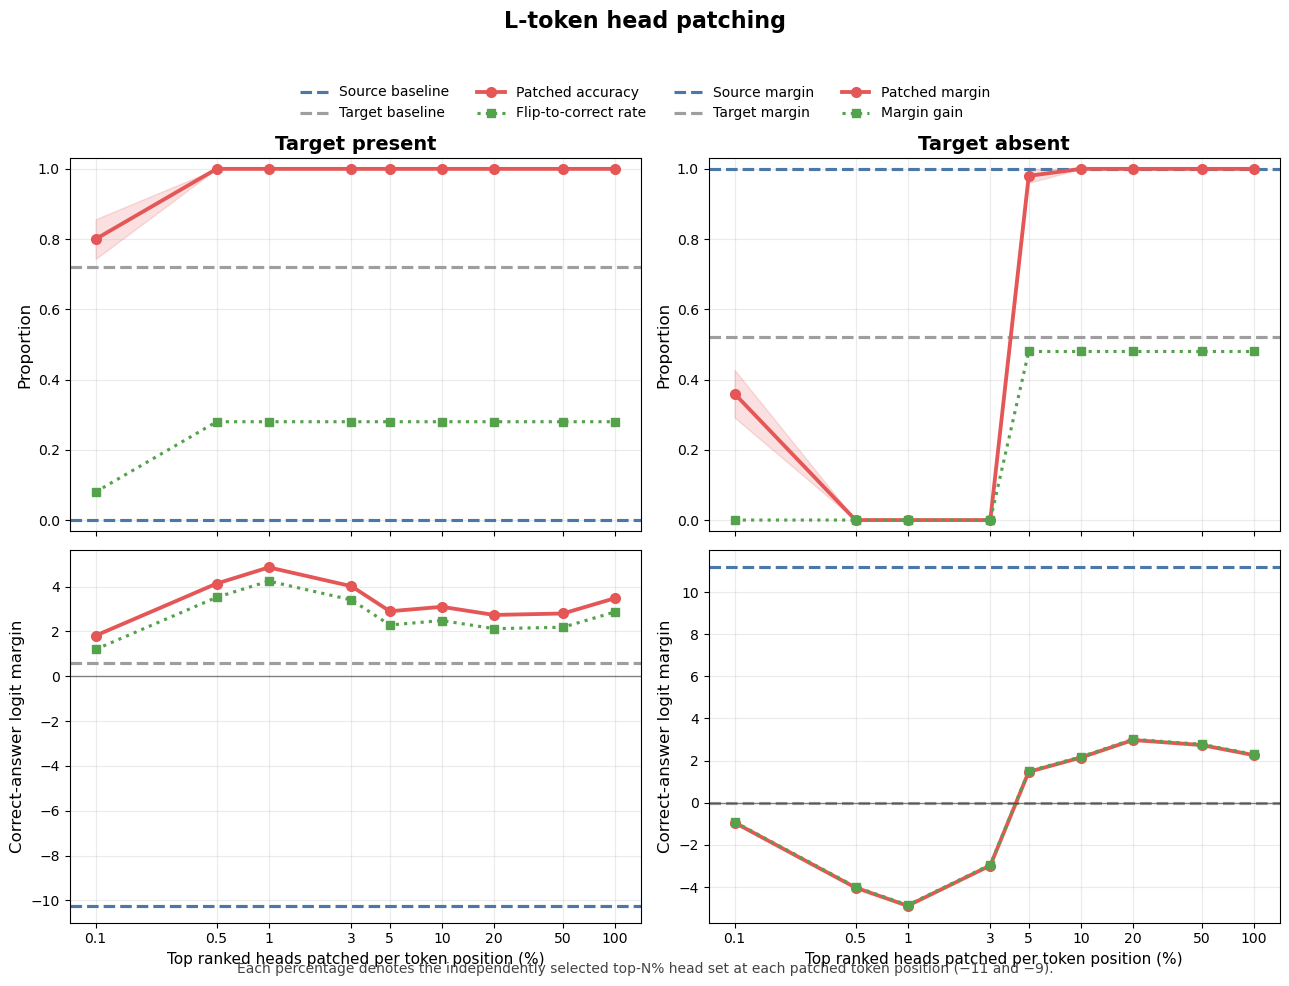

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "../Results/L_mask_to_conj40.csv"
)

OUTPUT_PATH = Path(
    "../Results/L_mask_to_conj40_performance.pdf"
)


# ==========================================================
# LOAD + CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
    "patched_flip_to_correct",
]:
    if column in df.columns:
        df[column] = parse_bool(df[column])


numeric_columns = [
    "patch_percentage",
    "source_margin",
    "target_margin",
    "patched_margin",
    "delta_margin",
    "recovery",
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")


# ==========================================================
# SUMMARIZE
# ==========================================================

summary = (
    df.groupby(["target_present", "patch_percentage"], as_index=False)
    .agg(
        n=("trial", "size"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        flip_to_correct_rate=("patched_flip_to_correct", "mean"),
        source_margin=("source_margin", "mean"),
        target_margin=("target_margin", "mean"),
        patched_margin=("patched_margin", "mean"),
        delta_margin=("delta_margin", "mean"),
        recovery=("recovery", "mean"),
    )
    .sort_values(["target_present", "patch_percentage"])
)

# Binomial standard errors for accuracy / flip rate.
for metric in [
    "patched_accuracy",
    "flip_to_correct_rate",
]:
    summary[f"{metric}_sem"] = np.sqrt(
        summary[metric] * (1 - summary[metric]) / summary["n"]
    )


# ==========================================================
# PLOT
# ==========================================================

COLORS = {
    "source": "#4C78A8",
    "target": "#9E9E9E",
    "patched": "#E45756",
    "gain": "#54A24B",
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(13, 9),
    sharex=True,
)

condition_info = [
    (True, "Target present"),
    (False, "Target absent"),
]

for column_index, (target_present, title) in enumerate(condition_info):
    ax_behavior = axes[0, column_index]
    ax_margin = axes[1, column_index]

    subset = (
        summary[summary["target_present"] == target_present]
        .sort_values("patch_percentage")
        .copy()
    )

    x = subset["patch_percentage"].to_numpy()

    # ------------------------------------------------------
    # Behavioral space
    # ------------------------------------------------------

    source_accuracy = subset["source_accuracy"].iloc[0]
    target_accuracy = subset["target_accuracy"].iloc[0]

    ax_behavior.axhline(
        source_accuracy,
        color=COLORS["source"],
        linestyle="--",
        linewidth=2.25,
        label="Source baseline",
    )

    ax_behavior.axhline(
        target_accuracy,
        color=COLORS["target"],
        linestyle="--",
        linewidth=2.25,
        label="Target baseline",
    )

    ax_behavior.plot(
        x,
        subset["patched_accuracy"],
        marker="o",
        linewidth=2.75,
        markersize=7,
        color=COLORS["patched"],
        label="Patched accuracy",
    )

    ax_behavior.fill_between(
        x,
        np.clip(
            subset["patched_accuracy"] - subset["patched_accuracy_sem"],
            0,
            1,
        ),
        np.clip(
            subset["patched_accuracy"] + subset["patched_accuracy_sem"],
            0,
            1,
        ),
        color=COLORS["patched"],
        alpha=0.18,
    )

    ax_behavior.plot(
        x,
        subset["flip_to_correct_rate"],
        marker="s",
        linestyle=":",
        linewidth=2.25,
        markersize=6,
        color=COLORS["gain"],
        label="Flip-to-correct rate",
    )

    ax_behavior.set_title(title, fontsize=14, fontweight="bold")
    ax_behavior.set_ylabel("Proportion", fontsize=12)
    ax_behavior.set_ylim(-0.03, 1.03)
    ax_behavior.grid(alpha=0.25)

    # ------------------------------------------------------
    # Margin space
    # ------------------------------------------------------

    source_margin = subset["source_margin"].iloc[0]
    target_margin = subset["target_margin"].iloc[0]

    ax_margin.axhline(
        source_margin,
        color=COLORS["source"],
        linestyle="--",
        linewidth=2.25,
        label="Source margin",
    )

    ax_margin.axhline(
        target_margin,
        color=COLORS["target"],
        linestyle="--",
        linewidth=2.25,
        label="Target margin",
    )

    ax_margin.plot(
        x,
        subset["patched_margin"],
        marker="o",
        linewidth=2.75,
        markersize=7,
        color=COLORS["patched"],
        label="Patched margin",
    )

    ax_margin.plot(
        x,
        subset["delta_margin"],
        marker="s",
        linestyle=":",
        linewidth=2.25,
        markersize=6,
        color=COLORS["gain"],
        label="Margin gain",
    )

    ax_margin.axhline(
        0,
        color="black",
        linewidth=1,
        alpha=0.45,
    )

    ax_margin.set_xlabel(
        "Top ranked heads patched per token position (%)",
        fontsize=11,
    )
    ax_margin.set_ylabel(
        "Correct-answer logit margin",
        fontsize=12,
    )
    ax_margin.grid(alpha=0.25)

    for axis in [ax_behavior, ax_margin]:
        axis.set_xscale("symlog", linthresh=0.1)
        axis.set_xticks(x)
        axis.set_xticklabels([f"{value:g}" for value in x])


# One shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
margin_handles, margin_labels = axes[1, 0].get_legend_handles_labels()

legend_items = dict(zip(labels + margin_labels, handles + margin_handles))

fig.legend(
    legend_items.values(),
    legend_items.keys(),
    loc="upper center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01),
)

fig.suptitle(
    "L-token head patching",
    fontsize=16,
    fontweight="bold",
    y=1.08,
)

fig.text(
    0.5,
    0.01,
    "Each percentage denotes the independently selected top-N% head set "
    "at each patched token position (−11 and −9).",
    ha="center",
    fontsize=10,
    color="#444444",
)

plt.tight_layout()
# plt.savefig(
#     OUTPUT_PATH,
#     dpi=300,
#     bbox_inches="tight",
# )
plt.show()

# print(f"Saved: {OUTPUT_PATH}")

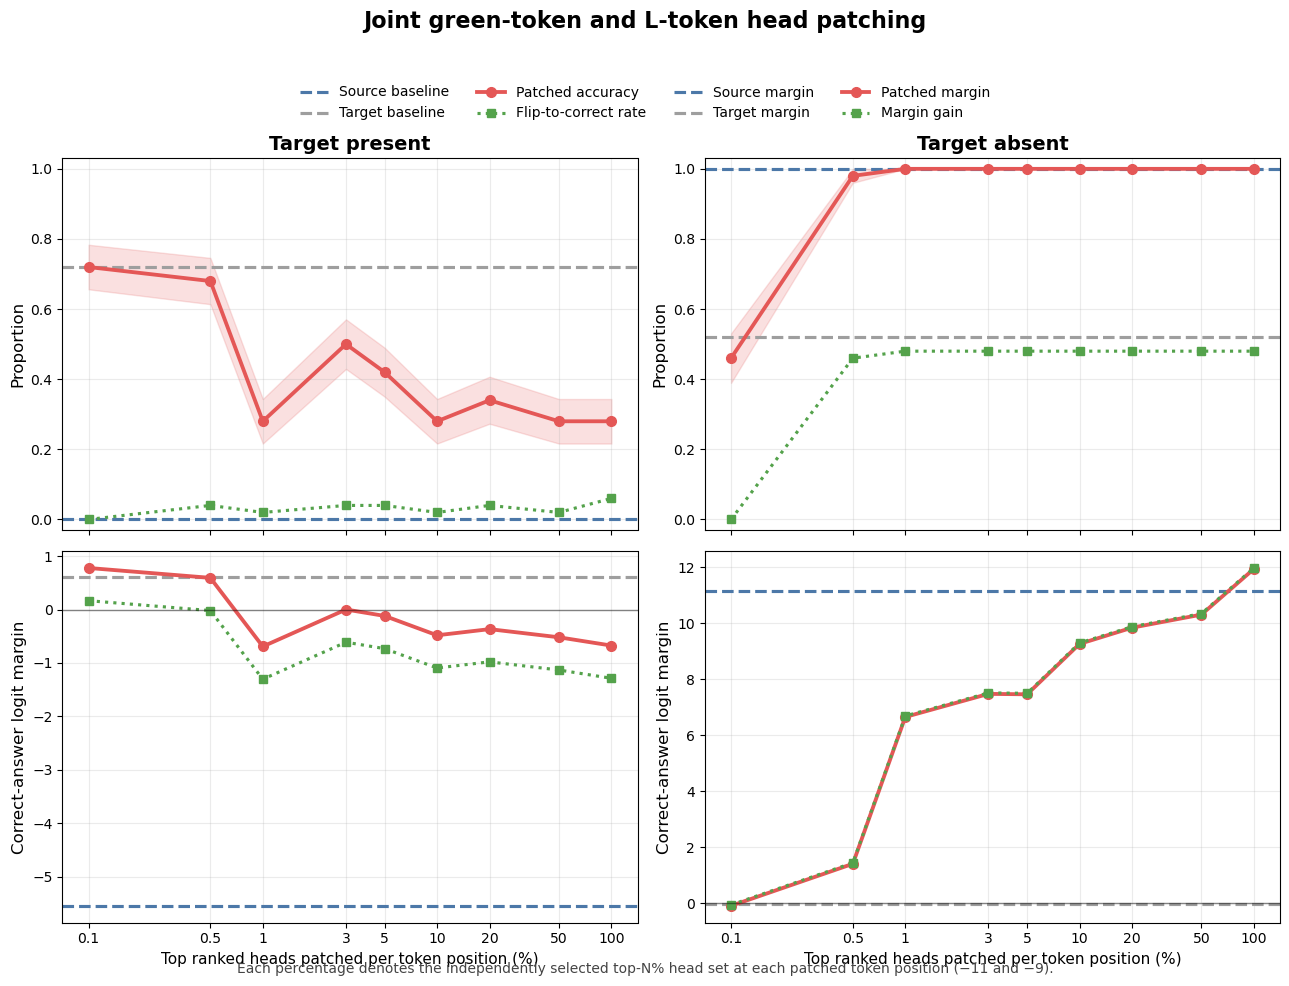

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "../Results/green_mask_to_conj40.csv"
)

OUTPUT_PATH = Path(
    "../Results/green_mask_to_conj40_performance.pdf"
)


# ==========================================================
# LOAD + CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
    "patched_flip_to_correct",
]:
    if column in df.columns:
        df[column] = parse_bool(df[column])


numeric_columns = [
    "patch_percentage",
    "source_margin",
    "target_margin",
    "patched_margin",
    "delta_margin",
    "recovery",
]

for column in numeric_columns:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")


# ==========================================================
# SUMMARIZE
# ==========================================================

summary = (
    df.groupby(["target_present", "patch_percentage"], as_index=False)
    .agg(
        n=("trial", "size"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        flip_to_correct_rate=("patched_flip_to_correct", "mean"),
        source_margin=("source_margin", "mean"),
        target_margin=("target_margin", "mean"),
        patched_margin=("patched_margin", "mean"),
        delta_margin=("delta_margin", "mean"),
        recovery=("recovery", "mean"),
    )
    .sort_values(["target_present", "patch_percentage"])
)

# Binomial standard errors for accuracy / flip rate.
for metric in [
    "patched_accuracy",
    "flip_to_correct_rate",
]:
    summary[f"{metric}_sem"] = np.sqrt(
        summary[metric] * (1 - summary[metric]) / summary["n"]
    )


# ==========================================================
# PLOT
# ==========================================================

COLORS = {
    "source": "#4C78A8",
    "target": "#9E9E9E",
    "patched": "#E45756",
    "gain": "#54A24B",
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(13, 9),
    sharex=True,
)

condition_info = [
    (True, "Target present"),
    (False, "Target absent"),
]

for column_index, (target_present, title) in enumerate(condition_info):
    ax_behavior = axes[0, column_index]
    ax_margin = axes[1, column_index]

    subset = (
        summary[summary["target_present"] == target_present]
        .sort_values("patch_percentage")
        .copy()
    )

    x = subset["patch_percentage"].to_numpy()

    # ------------------------------------------------------
    # Behavioral space
    # ------------------------------------------------------

    source_accuracy = subset["source_accuracy"].iloc[0]
    target_accuracy = subset["target_accuracy"].iloc[0]

    ax_behavior.axhline(
        source_accuracy,
        color=COLORS["source"],
        linestyle="--",
        linewidth=2.25,
        label="Source baseline",
    )

    ax_behavior.axhline(
        target_accuracy,
        color=COLORS["target"],
        linestyle="--",
        linewidth=2.25,
        label="Target baseline",
    )

    ax_behavior.plot(
        x,
        subset["patched_accuracy"],
        marker="o",
        linewidth=2.75,
        markersize=7,
        color=COLORS["patched"],
        label="Patched accuracy",
    )

    ax_behavior.fill_between(
        x,
        np.clip(
            subset["patched_accuracy"] - subset["patched_accuracy_sem"],
            0,
            1,
        ),
        np.clip(
            subset["patched_accuracy"] + subset["patched_accuracy_sem"],
            0,
            1,
        ),
        color=COLORS["patched"],
        alpha=0.18,
    )

    ax_behavior.plot(
        x,
        subset["flip_to_correct_rate"],
        marker="s",
        linestyle=":",
        linewidth=2.25,
        markersize=6,
        color=COLORS["gain"],
        label="Flip-to-correct rate",
    )

    ax_behavior.set_title(title, fontsize=14, fontweight="bold")
    ax_behavior.set_ylabel("Proportion", fontsize=12)
    ax_behavior.set_ylim(-0.03, 1.03)
    ax_behavior.grid(alpha=0.25)

    # ------------------------------------------------------
    # Margin space
    # ------------------------------------------------------

    source_margin = subset["source_margin"].iloc[0]
    target_margin = subset["target_margin"].iloc[0]

    ax_margin.axhline(
        source_margin,
        color=COLORS["source"],
        linestyle="--",
        linewidth=2.25,
        label="Source margin",
    )

    ax_margin.axhline(
        target_margin,
        color=COLORS["target"],
        linestyle="--",
        linewidth=2.25,
        label="Target margin",
    )

    ax_margin.plot(
        x,
        subset["patched_margin"],
        marker="o",
        linewidth=2.75,
        markersize=7,
        color=COLORS["patched"],
        label="Patched margin",
    )

    ax_margin.plot(
        x,
        subset["delta_margin"],
        marker="s",
        linestyle=":",
        linewidth=2.25,
        markersize=6,
        color=COLORS["gain"],
        label="Margin gain",
    )

    ax_margin.axhline(
        0,
        color="black",
        linewidth=1,
        alpha=0.45,
    )

    ax_margin.set_xlabel(
        "Top ranked heads patched per token position (%)",
        fontsize=11,
    )
    ax_margin.set_ylabel(
        "Correct-answer logit margin",
        fontsize=12,
    )
    ax_margin.grid(alpha=0.25)

    for axis in [ax_behavior, ax_margin]:
        axis.set_xscale("symlog", linthresh=0.1)
        axis.set_xticks(x)
        axis.set_xticklabels([f"{value:g}" for value in x])


# One shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
margin_handles, margin_labels = axes[1, 0].get_legend_handles_labels()

legend_items = dict(zip(labels + margin_labels, handles + margin_handles))

fig.legend(
    legend_items.values(),
    legend_items.keys(),
    loc="upper center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 1.01),
)

fig.suptitle(
    "green-token head patching",
    fontsize=16,
    fontweight="bold",
    y=1.08,
)

fig.text(
    0.5,
    0.01,
    "Each percentage denotes the independently selected top-N% head set "
    "at each patched token position (−11 and −9).",
    ha="center",
    fontsize=10,
    color="#444444",
)

plt.tight_layout()
# plt.savefig(
#     OUTPUT_PATH,
#     dpi=300,
#     bbox_inches="tight",
# )
plt.show()

# print(f"Saved: {OUTPUT_PATH}")

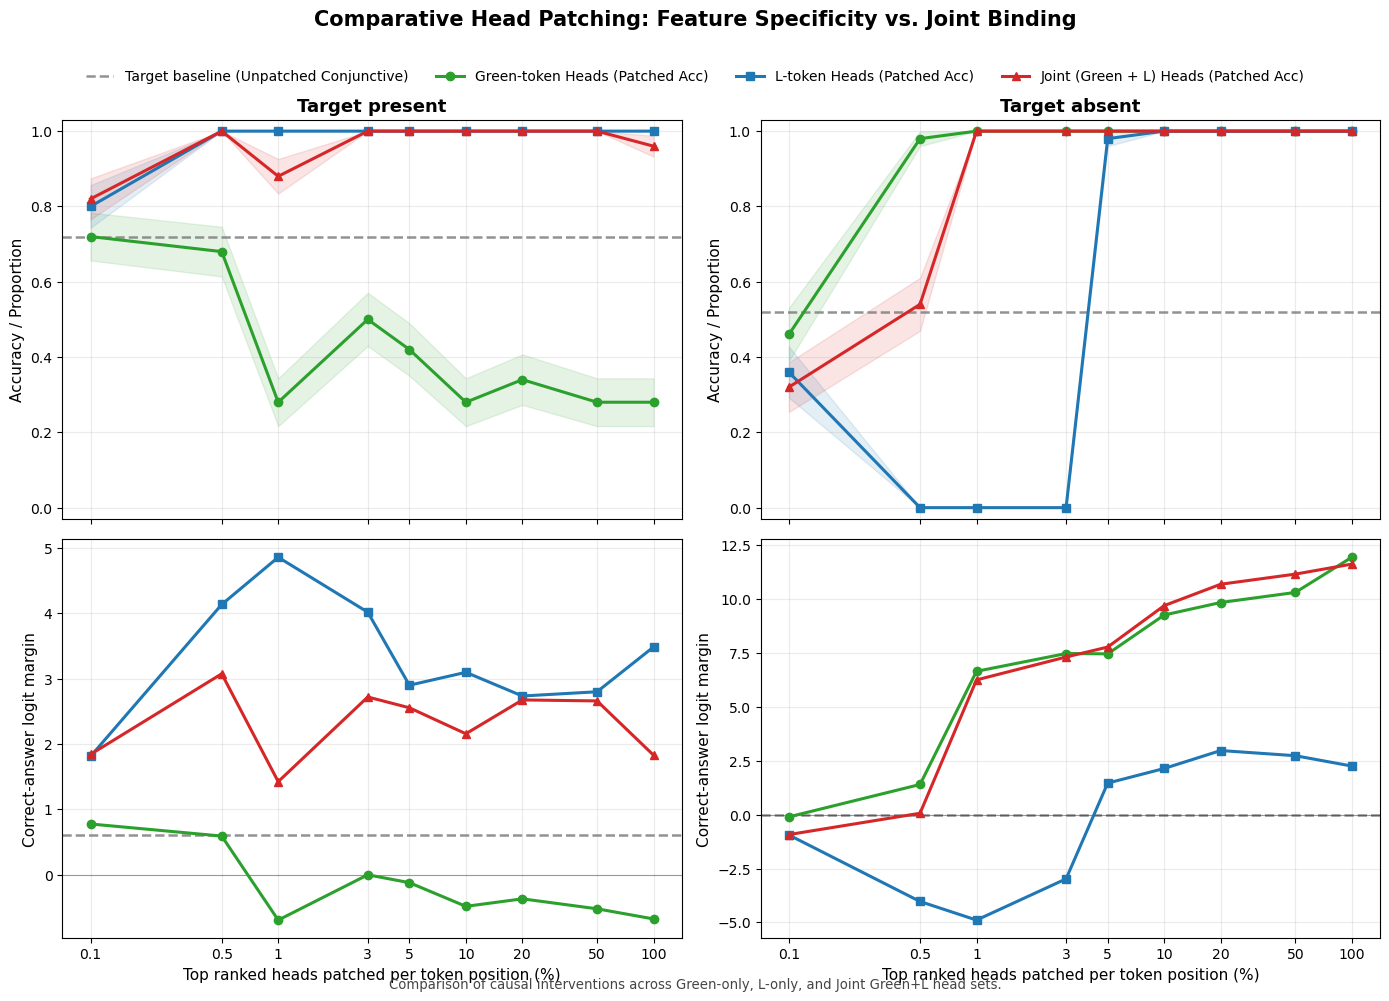

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================================
# EXPERIMENT CONFIGS & PATHS
# ==========================================================

RESULTS_DIR = Path("../Results")
OUTPUT_PATH = RESULTS_DIR / "combined_head_patching_performance.pdf"

EXPERIMENTS = {
    "green_mask": {
        "path": RESULTS_DIR / "green_mask_to_conj40.csv",
        "label": "Green-token Heads",
        "color": "#2CA02C",  # Green
        "marker": "o",
    },
    "L_mask": {
        "path": RESULTS_DIR / "L_mask_to_conj40.csv",
        "label": "L-token Heads",
        "color": "#1F77B4",  # Blue
        "marker": "s",
    },
    "green_L_mask": {
        "path": RESULTS_DIR / "green_L_mask_to_conj40.csv",
        "label": "Joint (Green + L) Heads",
        "color": "#D62728",  # Red
        "marker": "^",
    },
}

# ==========================================================
# DATA LOADING & CLEANING PIPELINE
# ==========================================================

def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


def load_and_summarize(csv_path: Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path).copy()

    if "error" in df.columns:
        df = df[df["error"].isna()].copy()

    for col in [
        "target_present",
        "source_correct",
        "target_correct",
        "patched_correct",
        "patched_flip_to_correct",
    ]:
        if col in df.columns:
            df[col] = parse_bool(df[col])

    numeric_cols = [
        "patch_percentage",
        "source_margin",
        "target_margin",
        "patched_margin",
        "delta_margin",
        "recovery",
    ]
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    summary = (
        df.groupby(["target_present", "patch_percentage"], as_index=False)
        .agg(
            n=("trial", "size"),
            source_accuracy=("source_correct", "mean"),
            target_accuracy=("target_correct", "mean"),
            patched_accuracy=("patched_correct", "mean"),
            flip_to_correct_rate=("patched_flip_to_correct", "mean"),
            source_margin=("source_margin", "mean"),
            target_margin=("target_margin", "mean"),
            patched_margin=("patched_margin", "mean"),
            delta_margin=("delta_margin", "mean"),
            recovery=("recovery", "mean"),
        )
        .sort_values(["target_present", "patch_percentage"])
    )

    for metric in ["patched_accuracy", "flip_to_correct_rate"]:
        summary[f"{metric}_sem"] = np.sqrt(
            summary[metric] * (1 - summary[metric]) / summary["n"]
        )

    return summary


# Load and process all datasets
summaries = {}
for key, cfg in EXPERIMENTS.items():
    if cfg["path"].exists():
        summaries[key] = load_and_summarize(cfg["path"])
    else:
        print(f"Warning: File not found {cfg['path']}")

# ==========================================================
# PLOT OVERLAY
# ==========================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 9.5),
    sharex=True,
)

condition_info = [
    (True, "Target present"),
    (False, "Target absent"),
]

for col_idx, (target_present, title) in enumerate(condition_info):
    ax_behavior = axes[0, col_idx]
    ax_margin = axes[1, col_idx]

    # ------------------------------------------------------
    # Shared Baselines (using target baseline from first dataset)
    # ------------------------------------------------------
    first_key = list(summaries.keys())[0]
    ref_subset = summaries[first_key][
        summaries[first_key]["target_present"] == target_present
    ]
    target_accuracy_base = ref_subset["target_accuracy"].iloc[0]
    target_margin_base = ref_subset["target_margin"].iloc[0]

    ax_behavior.axhline(
        target_accuracy_base,
        color="#7F7F7F",
        linestyle="--",
        linewidth=1.8,
        alpha=0.85,
        label="Target baseline (Unpatched Conjunctive)",
    )

    ax_margin.axhline(
        target_margin_base,
        color="#7F7F7F",
        linestyle="--",
        linewidth=1.8,
        alpha=0.85,
        label="Target baseline (Unpatched Conjunctive)",
    )
    ax_margin.axhline(0, color="black", linewidth=0.8, alpha=0.35)

    # ------------------------------------------------------
    # Overlay Experiments
    # ------------------------------------------------------
    x_ticks = None

    for exp_key, cfg in EXPERIMENTS.items():
        if exp_key not in summaries:
            continue

        subset = (
            summaries[exp_key][
                summaries[exp_key]["target_present"] == target_present
            ]
            .sort_values("patch_percentage")
            .copy()
        )

        x = subset["patch_percentage"].to_numpy()
        x_ticks = x

        # Row 0: Behavioral Accuracy
        ax_behavior.plot(
            x,
            subset["patched_accuracy"],
            marker=cfg["marker"],
            linewidth=2.2,
            markersize=6,
            color=cfg["color"],
            label=f"{cfg['label']} (Patched Acc)",
        )
        ax_behavior.fill_between(
            x,
            np.clip(subset["patched_accuracy"] - subset["patched_accuracy_sem"], 0, 1),
            np.clip(subset["patched_accuracy"] + subset["patched_accuracy_sem"], 0, 1),
            color=cfg["color"],
            alpha=0.12,
        )

        # Row 1: Correct Logit Margin
        ax_margin.plot(
            x,
            subset["patched_margin"],
            marker=cfg["marker"],
            linewidth=2.2,
            markersize=6,
            color=cfg["color"],
            label=f"{cfg['label']} (Patched Margin)",
        )

    # Subplot formatting
    ax_behavior.set_title(title, fontsize=13, fontweight="bold")
    ax_behavior.set_ylabel("Accuracy / Proportion", fontsize=11)
    ax_behavior.set_ylim(-0.03, 1.03)
    ax_behavior.grid(alpha=0.25)

    ax_margin.set_xlabel("Top ranked heads patched per token position (%)", fontsize=11)
    ax_margin.set_ylabel("Correct-answer logit margin", fontsize=11)
    ax_margin.grid(alpha=0.25)

    if x_ticks is not None:
        for axis in [ax_behavior, ax_margin]:
            axis.set_xscale("symlog", linthresh=0.1)
            axis.set_xticks(x_ticks)
            axis.set_xticklabels([f"{val:g}" for val in x_ticks])

# Consolidated Legend
handles, labels = axes[0, 0].get_legend_handles_labels()
unique_legend = dict(zip(labels, handles))

fig.legend(
    unique_legend.values(),
    unique_legend.keys(),
    loc="upper center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.99),
    fontsize=10,
)

fig.suptitle(
    "Comparative Head Patching: Feature Specificity vs. Joint Binding",
    fontsize=15,
    fontweight="bold",
    y=1.04,
)

fig.text(
    0.5,
    0.01,
    "Comparison of causal interventions across Green-only, L-only, and Joint Green+L head sets.",
    ha="center",
    fontsize=9.5,
    color="#444444",
)

plt.tight_layout()
plt.show()

### Attention head decomp for atomic maps

Components found: ['attention_matrix', 'full_head_output', 'value_vectors']
Rows: 5400


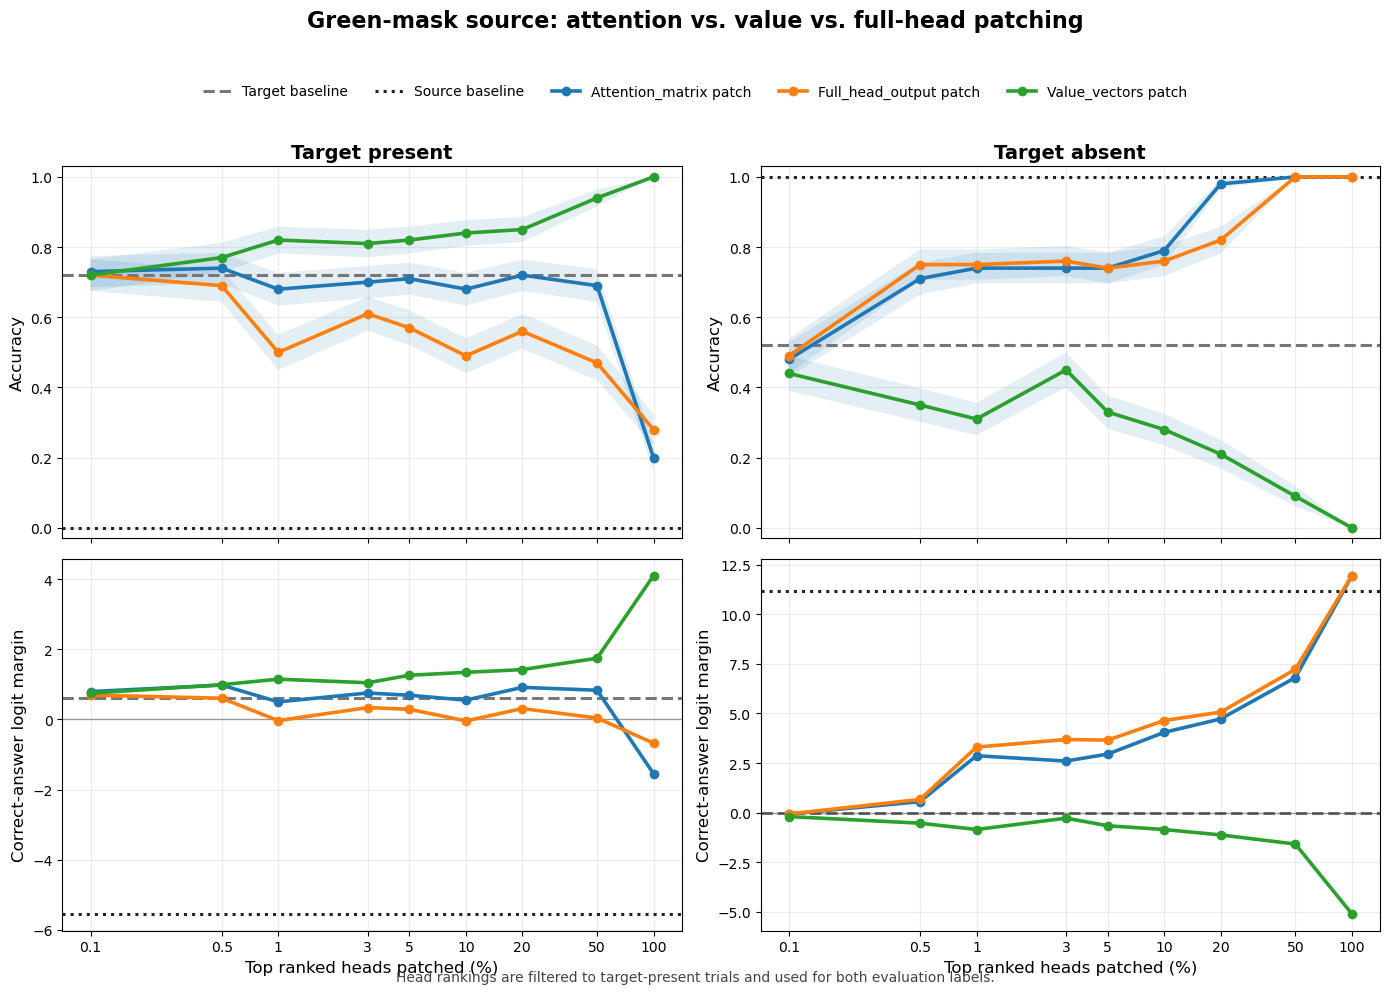

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==========================================================
# PATHS
# ==========================================================

INPUT_CSV = Path(
    "../Results/green_mask_component_to_conj40.csv"
)

OUTPUT_PATH = Path(
    "../Results/green_mask_component_to_conj40_components.pdf"
)


# ==========================================================
# LOAD + CLEAN
# ==========================================================

df = pd.read_csv(INPUT_CSV).copy()

if "error" in df.columns:
    df = df[df["error"].isna()].copy()


def parse_bool(series):
    if series.dtype == object:
        return (
            series.astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            })
        )
    return series.astype(bool)


for column in [
    "target_present",
    "source_correct",
    "target_correct",
    "patched_correct",
]:
    if column in df.columns:
        df[column] = parse_bool(df[column])


for column in [
    "patch_percentage",
    "source_margin",
    "target_margin",
    "patched_margin",
    "delta_margin",
    "recovery",
]:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

df["component"] = (
    df["intervention_component"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        "attention_only": "attention",
        "attn": "attention",
        "value_only": "value",
        "values": "value",
        "full_head": "full",
        "full_heads": "full",
    })
)

print("Components found:", sorted(df["component"].dropna().unique()))
print("Rows:", len(df))


# ==========================================================
# SUMMARY
# ==========================================================

summary = (
    df.groupby(
        ["target_present", "component", "patch_percentage"],
        as_index=False,
    )
    .agg(
        n=("trial", "size"),
        source_accuracy=("source_correct", "mean"),
        target_accuracy=("target_correct", "mean"),
        patched_accuracy=("patched_correct", "mean"),
        source_margin=("source_margin", "mean"),
        target_margin=("target_margin", "mean"),
        patched_margin=("patched_margin", "mean"),
        delta_margin=("delta_margin", "mean"),
        mean_recovery=("recovery", "mean"),
    )
    .sort_values(
        ["target_present", "component", "patch_percentage"]
    )
)

summary["patched_accuracy_sem"] = np.sqrt(
    summary["patched_accuracy"]
    * (1 - summary["patched_accuracy"])
    / summary["n"]
)


# ==========================================================
# PLOT SETTINGS
# ==========================================================

COMPONENT_ORDER = [
    component
    for component in ["attention", "value", "full"]
    if component in set(summary["component"])
]

# Include any unexpected component labels too.
COMPONENT_ORDER += [
    component
    for component in sorted(summary["component"].dropna().unique())
    if component not in COMPONENT_ORDER
]

COLORS = {
    "attention": "#4C78A8",
    "value": "#F58518",
    "full": "#E45756",
}

LINESTYLES = {
    "attention": "-",
    "value": "--",
    "full": "-.",
}


# ==========================================================
# 2 × 2 FIGURE
# ==========================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 9),
    sharex=True,
)

conditions = [
    (True, "Target present"),
    (False, "Target absent"),
]

for col_idx, (target_present, title) in enumerate(conditions):
    ax_behavior = axes[0, col_idx]
    ax_margin = axes[1, col_idx]

    condition_df = summary[
        summary["target_present"] == target_present
    ].copy()

    if condition_df.empty:
        ax_behavior.set_title(f"{title} (no successful rows yet)")
        ax_margin.set_title(f"{title} (no successful rows yet)")

        for axis in [ax_behavior, ax_margin]:
            axis.text(
                0.5,
                0.5,
                "No successful rows available",
                transform=axis.transAxes,
                ha="center",
                va="center",
            )
            axis.set_axis_off()

        continue

    # Baselines should be identical across components, so take the first row.
    baseline_row = condition_df.iloc[0]

    target_accuracy = baseline_row["target_accuracy"]
    source_accuracy = baseline_row["source_accuracy"]
    target_margin = baseline_row["target_margin"]
    source_margin = baseline_row["source_margin"]

    # ------------------------------------------------------
    # Behavioral space: target / source baselines + accuracy
    # ------------------------------------------------------

    ax_behavior.axhline(
        target_accuracy,
        color="#777777",
        linestyle="--",
        linewidth=2.2,
        label="Target baseline",
    )

    ax_behavior.axhline(
        source_accuracy,
        color="#222222",
        linestyle=":",
        linewidth=2.2,
        label="Source baseline",
    )

    for component in COMPONENT_ORDER:
        component_df = (
            condition_df[condition_df["component"] == component]
            .sort_values("patch_percentage")
        )

        if component_df.empty:
            continue

        x = component_df["patch_percentage"].to_numpy()
        y = component_df["patched_accuracy"].to_numpy()
        sem = component_df["patched_accuracy_sem"].to_numpy()

        color = COLORS.get(component, None)
        linestyle = LINESTYLES.get(component, "-")

        ax_behavior.plot(
            x,
            y,
            marker="o",
            markersize=6,
            linewidth=2.6,
            linestyle=linestyle,
            color=color,
            label=f"{component.capitalize()} patch",
        )

        ax_behavior.fill_between(
            x,
            np.clip(y - sem, 0, 1),
            np.clip(y + sem, 0, 1),
            color=color,
            alpha=0.12,
        )

    ax_behavior.set_title(title, fontsize=14, fontweight="bold")
    ax_behavior.set_ylabel("Accuracy", fontsize=12)
    ax_behavior.set_ylim(-0.03, 1.03)
    ax_behavior.grid(alpha=0.25)

    # ------------------------------------------------------
    # Logit / margin space
    # ------------------------------------------------------

    ax_margin.axhline(
        target_margin,
        color="#777777",
        linestyle="--",
        linewidth=2.2,
        label="Target margin",
    )

    ax_margin.axhline(
        source_margin,
        color="#222222",
        linestyle=":",
        linewidth=2.2,
        label="Source margin",
    )

    ax_margin.axhline(
        0,
        color="black",
        linewidth=1,
        alpha=0.35,
    )

    for component in COMPONENT_ORDER:
        component_df = (
            condition_df[condition_df["component"] == component]
            .sort_values("patch_percentage")
        )

        if component_df.empty:
            continue

        x = component_df["patch_percentage"].to_numpy()
        y = component_df["patched_margin"].to_numpy()

        color = COLORS.get(component, None)
        linestyle = LINESTYLES.get(component, "-")

        ax_margin.plot(
            x,
            y,
            marker="o",
            markersize=6,
            linewidth=2.6,
            linestyle=linestyle,
            color=color,
            label=f"{component.capitalize()} patch",
        )

    ax_margin.set_xlabel(
        "Top ranked heads patched (%)",
        fontsize=12,
    )
    ax_margin.set_ylabel(
        "Correct-answer logit margin",
        fontsize=12,
    )
    ax_margin.grid(alpha=0.25)

    # Log-scaled spacing while retaining 0.1%.
    for axis in [ax_behavior, ax_margin]:
        x_values = sorted(condition_df["patch_percentage"].unique())
        axis.set_xscale("symlog", linthresh=0.1)
        axis.set_xticks(x_values)
        axis.set_xticklabels([f"{value:g}" for value in x_values])


# Shared legend
handles, labels = axes[0, 0].get_legend_handles_labels()
legend = dict(zip(labels, handles))

fig.legend(
    legend.values(),
    legend.keys(),
    loc="upper center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, 1.02),
)

fig.suptitle(
    "Green-mask source: attention vs. value vs. full-head patching",
    fontsize=16,
    fontweight="bold",
    y=1.09,
)

fig.text(
    0.5,
    0.01,
    "Head rankings are filtered to target-present trials and used for both evaluation labels.",
    ha="center",
    fontsize=10,
    color="#444444",
)

plt.tight_layout()
# plt.savefig(
#     OUTPUT_PATH,
#     dpi=300,
#     bbox_inches="tight",
# )
plt.show()

#print(f"Saved figure to: {OUTPUT_PATH}")

In [10]:
df = pd.read_csv("../Results/green_mask_component_to_conj40.csv")

print(df.columns.tolist())
display(df.head())

['source_condition', 'target_condition', 'trial', 'target_present', 'source_distractors', 'target_distractors', 'source_image_path', 'source_image_paths_by_offset', 'target_image_path', 'patch_percentage', 'intervention_component', 'selection_type', 'random_seed', 'selected_head_count', 'actual_percentage', 'selected_heads', 'ranking_metric', 'head_ranking_csv', 'patch_configs', 'ranking_mode', 'ranking_group', 'token_offsets', 'source_correct', 'source_margin', 'target_correct', 'target_margin', 'patched_correct', 'patched_margin', 'patched_prediction', 'patched_flip_to_correct', 'source_input_text_length', 'target_input_text_length', 'target_patch_positions', 'target_patch_tokens', 'patched_layer_count', 'observed_o_proj_layouts', 'observed_o_proj_input_shapes', 'num_layers', 'num_heads', 'total_heads', 'head_dim', 'margin_drop', 'delta_margin', 'recovery', 'recovery_valid', 'error']


,source_condition,target_condition,trial,target_present,source_distractors,target_distractors,source_image_path,source_image_paths_by_offset,target_image_path,patch_percentage,...,observed_o_proj_input_shapes,num_layers,num_heads,total_heads,head_dim,margin_drop,delta_margin,recovery,recovery_valid,error
0,multi_source,conjunctive,0,True,40,40,/oscar/data/epavlick/aparasel/Binding-Problem-...,"{""-11"": ""/oscar/data/epavlick/aparasel/Binding...",/oscar/data/epavlick/aparasel/Binding-Problem-...,0.1,...,"{""15"": ""(1, 319, 3584)""}",28,28,784,128,-8.75,-0.25,NaN,False,NaN
1,multi_source,conjunctive,0,True,40,40,/oscar/data/epavlick/aparasel/Binding-Problem-...,"{""-11"": ""/oscar/data/epavlick/aparasel/Binding...",/oscar/data/epavlick/aparasel/Binding-Problem-...,0.1,...,"{""15"": ""(1, 319, 3584)""}",28,28,784,128,-8.75,0.25,NaN,False,NaN
2,multi_source,conjunctive,0,True,40,40,/oscar/data/epavlick/aparasel/Binding-Problem-...,"{""-11"": ""/oscar/data/epavlick/aparasel/Binding...",/oscar/data/epavlick/aparasel/Binding-Problem-...,0.1,...,"{""15"": ""(1, 319, 3584)""}",28,28,784,128,-8.75,0.25,NaN,False,NaN
3,multi_source,conjunctive,0,True,40,40,/oscar/data/epavlick/aparasel/Binding-Problem-...,"{""-11"": ""/oscar/data/epavlick/aparasel/Binding...",/oscar/data/epavlick/aparasel/Binding-Problem-...,0.1,...,"{""24"": ""(1, 319, 3584)""}",28,28,784,128,-8.75,0.00,NaN,False,NaN
4,multi_source,conjunctive,0,True,40,40,/oscar/data/epavlick/aparasel/Binding-Problem-...,"{""-11"": ""/oscar/data/epavlick/aparasel/Binding...",/oscar/data/epavlick/aparasel/Binding-Problem-...,0.1,...,"{""24"": ""(1, 319, 3584)""}",28,28,784,128,-8.75,0.00,NaN,False,NaN
